# Single-Lead ECG Signal-Quality Assessment under Controlled Injected Noise (Experiment Protocol v3.0)

**Scope.** This is a single-lead ECG signal-quality assessment (SQA) model.  v3.0 adds PLI injection (synthetic 50/60 Hz with optional real extract from MIT-BIH records 103/108/119/222) and multi-source noise mixtures (shared-SNR Dirichlet weighting plus named clinical/wearable scenarios). It classifies 2-second windows into clean, mildly noisy or severely noisy, with an auxiliary SNR regression output. It is not a six-lead arrhythmia classifier and not a denoising model. The labels describe the level of noise that was injected into MIT-BIH ECG windows, not independently validated absolute ECG quality. The MIT-BIH recordings are not noise-free, and the auxiliary "clean = 30 dB" SNR target is a modeling convention, not a measured ground truth. Titles, abstracts and contribution statements should say so.

**Why v3.0.** Protocol v2.2 froze the architecture comparison and investigated why mild noise is hard. v3.0 extends the protocol in two directions: (1) it adds Power-Line Interference (PLI) as a fourth noise type alongside baseline wander, electrode motion and muscle artifact; (2) it adds multi-source noise mixtures so that the model can be tested under realistic combined-noise conditions. The architecture is unchanged from v2.2 because the existing M4-D3 already handles arbitrary noise implicitly via the raw-window input. **Why v2.2 (historical).** Protocols v2.0 and v2.1 produced a clear direction but also exposed process problems: the 7-patient test split was reused across many ablations, the intrinsic-quality filter meant models were only evaluated on windows that passed a handcrafted filter, the registry backup path was undefined, the dataset-copy cell failed to find the NSTDB noise files, the configuration needed to reproduce each result was not saved, and the architecture comparison was drawn from a single test split. v2.2 does not add architectures. It preserves the earlier runs, repairs the process, freezes the comparison and investigates why mild noise is hard to detect.

**What is frozen.** Candidate architectures are M1-D3, M3-D3 and M4-D3 (depth 3, pooled, std pooling). M4-D3nostd is an exploratory variant and can never be declared the winner. Evidence for the architecture comparison is 5-fold grouped patient cross-validation (3 seeds per fold, patient-level bootstrap over all 47 patients). The 7-patient held-out split is supplementary and is evaluated only after the selection rule has been applied to the cross-validation results.

**Frozen selection rule.** On the cross-validation macro-F1 (mean over seeds, then over folds), choose the cheapest candidate (lowest batch-1 CPU latency) whose mean is within 0.01 of the best candidate (non-inferiority margin). The rule is applied to the unfiltered evaluation (primary endpoint) and to the filtered evaluation (secondary endpoint); if they disagree, the cheapest candidate is chosen and the disagreement is reported.

**SNR definition.** Injected noise is scaled so that 10 log10(P_window / P_noise) equals the sampled SNR.  For multi-source mixtures the *total* injected noise power equals the same target; the per-source powers are sampled from a Dirichlet distribution so that their sum is exactly the target.  Original note:  where P_window is the mean-removed power of the ECG window, including whatever intrinsic noise it already contains, and the noise segment is mean-removed and scaled to the required power. This is a window-referenced injected SNR, not the ratio of true cardiac signal to total noise. Mild uses 12-20 dB, severe 0-4 dB, and 4-12 dB is excluded from training and from the 3-class evaluation and used only as an unlabeled probe.

**Evaluation sets.** Filtered: windows that pass the intrinsic-quality filter (the v2.1 protocol, kept for comparison). Unfiltered: all windows of the test partition, including those the filter would remove. Training remains on filtered windows so that every v2.1 checkpoint stays valid.

**Requirement.** Internet access, or the PhysioNet files placed in Kaggle input or `/content`; optionally the v2.1 output folder or `ecg_quality_v21_package.zip` as a Kaggle dataset so that its checkpoints are reused.

## Protocol v3.0 Changes (additive to v2.2)

v3.0 keeps every v2.2 guarantee (patient-disjoint splits, frozen selection, patient-level bootstrap with Holm correction, source audit) and adds:

1. **PLI as a fourth noise type.** Synthetic 50/60 Hz sinusoid with random amplitude, phase, slow AM modulation, and 3rd harmonic. Optional real extract from MIT-BIH records 103, 108, 119, 222 (set `PLI_SOURCE = 'real_mitbih'` or `'both'`).

2. **Multi-source noise mixtures.** Each noisy window may now contain 1, 2, or 3 concurrent noise sources sharing a single total SNR budget. Weights are sampled either from a Dirichlet distribution (random) or from named clinical/wearable scenarios (e.g. `wearable_walking` = 40% bw + 60% ma, `icu_noise` = 30/30/40 bw/em/pli).

3. **Real-world PLI test set.** A naturally-corrupted subset of MIT-BIH windows (no injection) is used as an external validation set to test generalization beyond synthetic injection.

4. **Extended audit.** New checks verify PLI FFT peaks, mixture weight sums, realized mixture SNRs, scenario coverage, and PLI seed determinism.

5. **Extended analysis & figures.** Detection curves now span 4 noise types; new figures show detection-vs-noise-count and per-scenario accuracy heatmaps.

**Configuration switches** (all in Cell 3):
- `PLI_SOURCE` ∈ {`synthetic`, `real_mitbih`, `both`}
- `ENABLE_MULTI_NOUSE` (bool)
- `MIX_STRATEGY` ∈ {`single`, `shared_snr_dirichlet`, `scenario`}
- `MIX_SCENARIO_PROBA` (float in [0, 1]) — probability of using a named scenario
- `MIX_SCENARIOS` (dict of named profiles)
- `EVAL_REAL_PLI` (bool) — enable real-world PLI test set


## Stage 1: Environment, configuration and preservation of earlier runs

**Why.** The v2.0/v2.1 results are the evidence trail for every later decision. They must be backed up with checksums before anything new is written, and new outputs must go to a different folder so that nothing can be overwritten.

**How.** Cell 2 imports libraries. Cell 3 defines the protocol, the frozen model set and paths. Cell 4 locates the v2.1 outputs (folder or zip), copies them to a timestamped read-only folder with a SHA-256 manifest and verifies the copy.

In [1]:
from pathlib import Path

# Path to the attached dataset on Kaggle
dataset_dir = Path("/kaggle/input/datasets/dule11/ecg-quality-v21")  # Adjust if your dataset slug differs
print(list(dataset_dir.glob("*")))
import shutil
from pathlib import Path

# Path where Kaggle attached your dataset
src_dir = Path("/kaggle/input/datasets/dule11/ecg-quality-v21")
# Destination in your working directory
dest_dir = Path("/kaggle/working/ecg_quality_v21")

if src_dir.exists():
    if dest_dir.exists():
        shutil.rmtree(dest_dir)  # Clean previous copy if needed
    shutil.copytree(src_dir, dest_dir)
    print(f"Successfully loaded and copied dataset to: {dest_dir}")
    
    # Verify subfolders and files
    print("Contents loaded:")
    for item in sorted(dest_dir.glob("*")):
        print(f" - {item.name} ({'folder' if item.is_dir() else 'file'})")
else:
    print(f"Source dataset directory not found at {src_dir}. Please check your Add Input panel.")

[PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/checksums.json'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/figures'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/manifests'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/metrics'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/models'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/tables')]
Successfully loaded and copied dataset to: /kaggle/working/ecg_quality_v21
Contents loaded:
 - checksums.json (file)
 - figures (folder)
 - manifests (folder)
 - metrics (folder)
 - models (folder)
 - tables (folder)


In [2]:
# Cell 2: install and import
%pip install -q wfdb

import copy
import hashlib
import inspect
import io
import json
import os
import pickle
import platform
import random
import shutil
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as sps
import torch
import torch.nn as nn
import wfdb
from IPython.display import display
from scipy import stats
from scipy.stats import kurtosis, skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Cell 3: global configuration (Experiment Protocol v3.0)
PROTOCOL = "v3.0"
DATA_SEED = 42
CV_SEED = 42
MAIN_SEEDS = [42, 123, 2026, 7, 99]
CV_SEEDS = [42, 123, 2026]
CV_FOLDS = 5
RUN_CV = True
REUSE_V21 = False  # v3.0 has new noise distribution; cannot reuse v2.1 checkpoints
NONINFERIORITY_MARGIN = 0.01
FROZEN_CANDIDATES = ["M1-D3", "M3-D3", "M4-D3"]
EXPLORATORY_MODELS = ["M4-D3nostd"]

FS = 360
WIN_SEC = 2
WIN = FS * WIN_SEC
MIN_STD = 1e-3
QC_KEEP_QUANTILE = 0.70

SPLITS = ["train", "val", "test"]
SPLIT_FRAC = {"train": 0.70, "val": 0.15, "test": 0.15}
NOISE_PART = {"train": (0.0, 0.6), "val": (0.6, 0.8), "test": (0.8, 1.0)}
GUARD_SEC = 5

CLASS_NAMES = ["clean", "mild", "severe"]
NOISE_NAMES = ["bw", "em", "ma", "pli"]
NOISE_LABEL = {"bw": "Baseline wander", "em": "Electrode motion", "ma": "Muscle artifact", "pli": "Power-line interference"}

# ---- v3.0 additions: PLI configuration ----
PLI_FREQS = [50, 60]                       # Hz; both line frequencies supported
PLI_AMPS = (0.05, 0.5)                     # mV; peak amplitude range (relative to ECG scale)
PLI_AM_MOD_FREQ = (0.1, 0.5)               # Hz; slow AM modulation frequency range
PLI_AM_MOD_DEPTH = 0.3                     # 0..1; AM modulation depth
PLI_HARMONICS = [1, 3]                     # which harmonics to include (1 = fundamental)
PLI_SOURCE = "synthetic"                   # "synthetic" | "real_mitbih" | "both"
REAL_PLI_RECORDS = ["103", "108", "119", "222"]  # MIT-BIH records known to contain PLI

# ---- v3.0 additions: multi-noise mixture configuration ----
ENABLE_MULTI_NOISE = True                 # master switch for mixture injection
MIX_STRATEGY = "shared_snr_dirichlet"      # "single" | "shared_snr_dirichlet" | "scenario"
MIX_MIN_TYPES = 1                          # minimum number of noise types per noisy window
MIX_MAX_TYPES = 3                          # cap on number of concurrent noise sources
MIX_SCENARIO_PROBA = 0.4                   # probability of using a named scenario vs random Dirichlet
MAX_NOISE_TYPES_PER_WINDOW = MIX_MAX_TYPES

# Named clinical / wearable noise profiles (weights sum to 1.0)
MIX_SCENARIOS = {
    "single_bw":           {"bw": 1.0},
    "single_em":           {"em": 1.0},
    "single_ma":           {"ma": 1.0},
    "single_pli":          {"pli": 1.0},
    "wearable_walking":    {"bw": 0.4, "ma": 0.6},
    "clinical_motion":    {"bw": 0.5, "em": 0.5},
    "icu_noise":           {"bw": 0.3, "em": 0.3, "pli": 0.4},
    "home_monitoring":     {"bw": 0.3, "ma": 0.4, "pli": 0.3},
    "extreme_motion":      {"bw": 0.25, "em": 0.5, "ma": 0.25},
}

# ---- v3.0 additions: real-world PLI test set ----
EVAL_REAL_PLI = True                       # evaluate on naturally-corrupted MIT-BIH windows

# ---- v3.0 additions: separate seeds for mixture Dirichlet sampling ----
MIX_SEEDS = [42, 123, 2026]
SNR_RANGE = {"mild": (12.0, 20.0), "severe": (0.0, 4.0)}
SNR_INTERMEDIATE = (4.0, 12.0)
SNR_CLEAN_TARGET = 30.0
SNR_SHIFT, SNR_SCALE = 15.0, 10.0
SNR_EDGES = [2.0, 4.0, 16.0]
BIN_LABELS = ["0-2", "2-4", "12-16", "16-20"]

VARIANTS = {"M1": "Standard 1D-CNN", "M3": "MS-LiteCNN", "M4": "MS-LiteSQA"}
MODEL_SPECS = {}


def add_spec(name, variant, std=True):
    MODEL_SPECS[name] = dict(variant=variant, depth=3, pool=True, std=std, dc="window", loss="ce")


add_spec("M1-D3", "M1")
add_spec("M3-D3", "M3")
add_spec("M4-D3", "M4")
add_spec("M4-D3nostd", "M4", std=False)
SEEDS_OF = {k: list(MAIN_SEEDS) for k in MODEL_SPECS}
SEEDS_OF["M4-D3nostd"] = list(MAIN_SEEDS[:3])
CV_MODELS = list(MODEL_SPECS)
BASELINE_NAMES = ["logreg", "random_forest", "ridge_snr"]

TRAIN_CFG = dict(batch_size=64, epochs=40, lr=1e-3, weight_decay=0.01, patience=10, base_channels=16,
                 dropout=0.2, ema_decay=0.995, smooth_window=3, lambda_reg=0.5, min_select_epoch=10,
                 min_epochs=20, bn_recal_batches=40, bn_recal_batch_size=256)
METRIC_COLS = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "qwk", "adjacent_error", "gross_error"]
N_BOOT = 2000

ON_KAGGLE = Path("/kaggle").exists()
ON_COLAB = Path("/content").exists() and not ON_KAGGLE
ROOT = Path("/kaggle/working") if ON_KAGGLE else Path("/content") if ON_COLAB else Path("working")
DATA_DIR = (Path("/kaggle/temp/physionet") if ON_KAGGLE else Path("/content/physionet") if ON_COLAB
            else Path("data"))
OUT_ROOT = ROOT / "ecg_quality_v30"
OUT = {k: OUT_ROOT / k for k in ["models", "manifests", "metrics", "figures", "tables", "predictions", "audit"]}
for p in [DATA_DIR, ROOT, *OUT.values()]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN = DEVICE.type == "cuda"
TEST_LOG = []

CONFIG = dict(protocol=PROTOCOL, data_seed=DATA_SEED, cv_seed=CV_SEED, main_seeds=MAIN_SEEDS, cv_seeds=CV_SEEDS,
              cv_folds=CV_FOLDS, fs=FS, win=WIN, min_std=MIN_STD, qc_keep_quantile=QC_KEEP_QUANTILE,
              split_frac=SPLIT_FRAC, noise_part=NOISE_PART, guard_sec=GUARD_SEC, snr_range=SNR_RANGE,
              snr_intermediate=SNR_INTERMEDIATE, snr_clean_target=SNR_CLEAN_TARGET, train_cfg=TRAIN_CFG,
              model_specs=MODEL_SPECS, frozen_candidates=FROZEN_CANDIDATES, exploratory=EXPLORATORY_MODELS,
              margin=NONINFERIORITY_MARGIN, noise_names=NOISE_NAMES, pli_source=PLI_SOURCE,
              enable_multi_noise=ENABLE_MULTI_NOISE, mix_strategy=MIX_STRATEGY,
              mix_scenarios=MIX_SCENARIOS, max_noise_types_per_window=MAX_NOISE_TYPES_PER_WINDOW,
              eval_real_pli=EVAL_REAL_PLI)
CONFIG_HASH = hashlib.sha256(json.dumps(CONFIG, sort_keys=True, default=str).encode()).hexdigest()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conf3(y, p):
    return np.bincount(np.asarray(y) * 3 + np.asarray(p), minlength=9).reshape(3, 3)


def f1_from_cms(cms):
    cms = np.asarray(cms, dtype=float)
    tp = np.diagonal(cms, axis1=-2, axis2=-1)
    prec = tp / np.maximum(cms.sum(-2), 1e-12)
    rec = tp / np.maximum(cms.sum(-1), 1e-12)
    return (2 * prec * rec / np.maximum(prec + rec, 1e-12)).mean(-1)


def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
    off = np.abs(np.arange(3)[:, None] - np.arange(3)[None, :])
    w = off ** 2 / 4.0
    expected = np.outer(cm.sum(1), cm.sum(0)) / max(cm.sum(), 1)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f, "macro_precision": p, "macro_recall": r,
            "qwk": 1 - (w * cm).sum() / max((w * expected).sum(), 1e-12),
            "adjacent_error": cm[off == 1].sum() / cm.sum(), "gross_error": cm[off == 2].sum() / cm.sum(),
            "sensitivity": cm.diagonal() / np.maximum(cm.sum(axis=1), 1), "confusion_matrix": cm}


def apply_thresholds(s, thr):
    return 2 - (np.asarray(s) > thr[0]).astype(int) - (np.asarray(s) > thr[1]).astype(int)


def fit_thresholds(s, y):
    best, arg = -1.0, (7.0, 20.0)
    for a in np.arange(-4.0, 12.5, 0.5):
        for b in np.arange(max(a + 1.0, 6.0), 34.5, 0.5):
            f = float(f1_from_cms(conf3(y, apply_thresholds(s, (a, b)))))
            if f > best:
                best, arg = f, (float(a), float(b))
    return arg


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


set_seed(DATA_SEED)
print(f"protocol {PROTOCOL}, device={DEVICE}, models={list(MODEL_SPECS)}, outputs={OUT_ROOT}, config hash {CONFIG_HASH[:12]}")

protocol v3.0, device=cuda, models=['M1-D3', 'M3-D3', 'M4-D3', 'M4-D3nostd'], outputs=/kaggle/working/ecg_quality_v30, config hash 5c384ed82d2c


In [4]:
# Cell 4: locate and preserve the v2.1 outputs (never overwritten, copy is read-only and checksummed)
V21_NAME = "ecg_quality_v21"
V21_OVERRIDE = None
PRESERVE_ROOT = ROOT / "preserved_runs"


def locate_v21():
    cands = [ROOT / V21_NAME, Path("/kaggle/working") / V21_NAME, Path("/content") / V21_NAME]
    if V21_OVERRIDE:
        cands.insert(0, Path(V21_OVERRIDE))
    inp = Path("/kaggle/input")
    zips = []
    if inp.exists():
        for pat in (f"*/{V21_NAME}", f"*/*/{V21_NAME}", f"*/*/*/{V21_NAME}"):
            cands += list(inp.glob(pat))
        for pat in ("*/*v21*.zip", "*/*/*v21*.zip", "*/*/*/*v21*.zip"):
            zips += list(inp.glob(pat))
    for c in cands:
        if c.is_dir() and (c / "models").exists():
            return c
    for z in zips:
        dest = ROOT / "restored_v21"
        if not dest.exists():
            shutil.unpack_archive(str(z), str(dest))
        if (dest / "models").exists():
            return dest
        inner = [d for d in dest.rglob(V21_NAME) if d.is_dir()]
        if inner and (inner[0] / "models").exists():
            return inner[0]
    return None


def preserve(src):
    files = sorted(p for p in src.rglob("*") if p.is_file())
    manifest = {str(p.relative_to(src)): sha256_file(p) for p in files}
    PRESERVE_ROOT.mkdir(parents=True, exist_ok=True)
    for old in sorted(PRESERVE_ROOT.glob(f"{src.name}_*")):
        mf = old / "preservation_manifest.json"
        if mf.exists() and json.loads(mf.read_text()) == manifest:
            return old, manifest, "existing preserved copy matches"
    dst = PRESERVE_ROOT / f"{src.name}_{time.strftime('%Y%m%d_%H%M%S')}"
    for p in files:
        target = dst / p.relative_to(src)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, target)
    for rel, h in manifest.items():
        assert sha256_file(dst / rel) == h, rel
    (dst / "preservation_manifest.json").write_text(json.dumps(manifest, indent=2))
    for p in dst.rglob("*"):
        if p.is_file():
            os.chmod(p, 0o444)
    return dst, manifest, "new preserved copy"


V21_SRC = locate_v21() if REUSE_V21 else None
V21_DIR, V21_MANIFEST = None, {}
if V21_SRC is not None:
    V21_DIR, V21_MANIFEST, note = preserve(V21_SRC)
    print(f"v2.1 outputs found at {V21_SRC}; {note}: {V21_DIR} ({len(V21_MANIFEST)} files checksummed)")
else:
    print("No v2.1 outputs found; every model will be trained from scratch in this run.")
assert V21_DIR is None or V21_DIR.resolve() != OUT_ROOT.resolve()

No v2.1 outputs found; every model will be trained from scratch in this run.


## Stage 2: Dataset acquisition and inspection

**Why.** The copy cell used in earlier runs searched fixed paths and silently fell back to a download when the NSTDB noise files were not where it expected them. Searching recursively for the exact files needed, and reporting which source was used, removes that failure mode. Silent data problems (wrong sampling rate, missing samples, unexpected channel order, shared patients) invalidate results without raising errors and are cheap to detect first.

**How.** Cell 5 stages MIT-BIH and NSTDB files from local copies (Kaggle input, Colab, working directory), with PhysioNet as a fallback. Cell 6 validates every recording. Cell 7 plots representative signals.

## v3.0 Noise Library

**NSTDB sources (kept from v2.2):**
- `bw` — Baseline wander, low-frequency (~0.5–1 Hz)
- `em` — Electrode motion, medium-frequency
- `ma` — Muscle artifact (EMG), high-frequency (20–150 Hz)

**v3.0 additions:**
- `pli` — Power-Line Interference, 50/60 Hz sinusoid with harmonics
  - Synthetic generator produces unit-power mean-removed segments
  - Optional real extract from MIT-BIH records 103, 108, 119, 222 (band-pass 49–61 Hz)

**Mixture scenarios (v3.0):**
| Scenario | Composition | Clinical motivation |
|---|---|---|
| `wearable_walking` | bw 0.4 + ma 0.6 | Ambulatory wearable during activity |
| `clinical_motion` | bw 0.5 + em 0.5 | Hospital bedside with patient movement |
| `icu_noise` | bw 0.3 + em 0.3 + pli 0.4 | ICU with mains interference |
| `home_monitoring` | bw 0.3 + ma 0.4 + pli 0.3 | Remote patient monitoring |
| `extreme_motion` | bw 0.25 + em 0.5 + ma 0.25 | Sports / emergency response |

Mixture windows share a single total SNR budget; per-source powers are sampled from a Dirichlet distribution so their sum equals the target noise power exactly.

In [8]:
# Cell 5: stage MIT-BIH and NSTDB noise records (local search first, PhysioNet fallback)
MITDB_DIR = DATA_DIR / "mitdb"
NSTDB_DIR = DATA_DIR / "nstdb"
LOCAL_ROOTS = [Path("/kaggle/input"), Path("/content"), Path("data")]
MIT_NEEDED = ["100.dat", "100.hea", "234.dat", "234.hea"]

# Filter out non-database types like 'pli' which are handled synthetically or locally
NSTDB_NOISE_NAMES = [n for n in NOISE_NAMES if n != "pli"]
NST_NEEDED = [f"{n}.{e}" for n in NSTDB_NOISE_NAMES for e in ("dat", "hea")]


def missing_files(directory, names):
    return [n for n in names if not (directory / f"{n}.dat").exists() or not (directory / f"{n}.hea").exists()]


def find_dir_with(filenames, roots, exclude=()):
    for root in roots:
        if not root.exists():
            continue
        for hit in root.rglob(filenames[0]):
            d = hit.parent
            if any(str(d).startswith(str(e)) for e in exclude):
                continue
            if all((d / f).exists() for f in filenames):
                return d
    return None


def stage(src, dst, suffixes=(".dat", ".hea", ".atr"), stems=None):
    dst.mkdir(parents=True, exist_ok=True)
    for f in src.iterdir():
        if f.is_file() and f.suffix in suffixes and (stems is None or f.stem in stems) and not (dst / f.name).exists():
            shutil.copy2(f, dst / f.name)


source_log = []
if len(list(MITDB_DIR.glob("*.dat"))) < 48:
    src = find_dir_with(MIT_NEEDED, LOCAL_ROOTS, exclude=(DATA_DIR,))
    if src is not None:
        stage(src, MITDB_DIR)
        source_log.append(f"MIT-BIH staged from {src}")
if len(list(MITDB_DIR.glob("*.dat"))) < 48:
    wfdb.dl_database("mitdb", str(MITDB_DIR))
    source_log.append("MIT-BIH downloaded from PhysioNet")
else:
    source_log.append("MIT-BIH records present in the target directory")

if missing_files(NSTDB_DIR, NSTDB_NOISE_NAMES):
    src = find_dir_with(NST_NEEDED, LOCAL_ROOTS, exclude=(DATA_DIR,))
    if src is not None:
        stage(src, NSTDB_DIR, suffixes=(".dat", ".hea"), stems=set(NSTDB_NOISE_NAMES))
        source_log.append(f"NSTDB noise records staged from {src}")
if missing_files(NSTDB_DIR, NSTDB_NOISE_NAMES):
    wfdb.dl_database("nstdb", str(NSTDB_DIR), records=NSTDB_NOISE_NAMES, annotators=None)
    source_log.append("NSTDB noise records downloaded from PhysioNet")
else:
    source_log.append("NSTDB noise records present in the target directory")

MIT_RECORDS = sorted(p.stem for p in MITDB_DIR.glob("*.hea"))
print("\n".join(source_log))
print(f"{len(MIT_RECORDS)} MIT-BIH records, NSTDB missing: {missing_files(NSTDB_DIR, NSTDB_NOISE_NAMES)}")
assert len(MIT_RECORDS) == 48 and not missing_files(NSTDB_DIR, NSTDB_NOISE_NAMES)

# ---- v3.0 addition: stage real PLI segments from MIT-BIH records (optional) ----
real_pli_signals = {}
if PLI_SOURCE in ("real_mitbih", "both"):
    print(f"Extracting real PLI from MIT-BIH records {REAL_PLI_RECORDS}")
    for r in REAL_PLI_RECORDS:
        if r not in MIT_RECORDS:
            print(f"  WARNING: record {r} not present, skipping")
            continue
        rec = wfdb.rdrecord(str(MITDB_DIR / r))
        ch = pick_channel(rec.sig_name)
        full = rec.p_signal[:, ch].astype(np.float32)
        # Bandpass around 50/60 Hz to isolate the PLI component
        for f0 in PLI_FREQS:
            band = sps.iirfilter(2, [f0 - 1.5, f0 + 1.5], btype="band", fs=FS, ftype="butter")
            full = full - sps.filtfilt(*band, full)
        
        pli_comp = np.zeros_like(full)
        for f0 in PLI_FREQS:
            band = sps.iirfilter(2, [f0 - 1.5, f0 + 1.5], btype="band", fs=FS, ftype="butter")
            pli_comp += sps.filtfilt(*band, rec.p_signal[:, ch].astype(np.float32))
        real_pli_signals[f"pli_{r}"] = pli_comp
        print(f"  record {r}: extracted {len(pli_comp)} PLI samples")
    assert len(real_pli_signals) > 0, "real PLI extraction produced nothing; check REAL_PLI_RECORDS"
else:
    print("PLI source is synthetic; skipping real-PLI extraction")

MIT-BIH records present in the target directory
NSTDB noise records present in the target directory
48 MIT-BIH records, NSTDB missing: []
PLI source is synthetic; skipping real-PLI extraction


In [7]:
# Filter out non-NSTDB noise names (like synthetic/local 'pli') before calling dl_database
nstdb_download_records = [n for n in NOISE_NAMES if n != "pli"]

if missing_files(NSTDB_DIR, nstdb_download_records):
    src = find_dir_with(NST_NEEDED, LOCAL_ROOTS, exclude=(DATA_DIR,))
    if src is not None:
        stage(src, NSTDB_DIR, suffixes=(".dat", ".hea"), stems=set(nstdb_download_records))
        source_log.append(f"NSTDB noise records staged from {src}")
        
if missing_files(NSTDB_DIR, nstdb_download_records):
    wfdb.dl_database("nstdb", str(NSTDB_DIR), records=nstdb_download_records, annotators=None)
    source_log.append("NSTDB noise records downloaded from PhysioNet")
else:
    source_log.append("NSTDB noise records present in the target directory")

In [9]:
# Cell 6: validate recordings
PATIENT = {r: r for r in MIT_RECORDS}
PATIENT["202"] = "201"

def pick_channel(names):
    return names.index("MLII") if "MLII" in names else 0

ecg_signals, rows = {}, []
for r in MIT_RECORDS:
    rec = wfdb.rdrecord(str(MITDB_DIR / r))
    ann = wfdb.rdann(str(MITDB_DIR / r), "atr")
    ch = pick_channel(rec.sig_name)
    sig = rec.p_signal[:, ch].astype(np.float32)
    ecg_signals[r] = sig
    rows.append(dict(record=r, patient=PATIENT[r], fs=rec.fs, channels=",".join(rec.sig_name),
                     used=rec.sig_name[ch], units=rec.units[ch], samples=rec.sig_len,
                     minutes=round(rec.sig_len / rec.fs / 60, 2), annotations=len(ann.sample),
                     nan_count=int(np.isnan(sig).sum()), std=float(np.nanstd(sig))))
mit_info = pd.DataFrame(rows)

# Only loop over physical NSTDB files (exclude synthetic/local 'pli')
NSTDB_FILES = [n for n in NOISE_NAMES if n != "pli"]

noise_signals, rows = {}, []
for n in NSTDB_FILES:
    rec = wfdb.rdrecord(str(NSTDB_DIR / n))
    sig = rec.p_signal[:, 0].astype(np.float32)
    noise_signals[n] = sig
    rows.append(dict(noise=n, fs=rec.fs, channels=",".join(rec.sig_name), samples=rec.sig_len,
                     minutes=round(rec.sig_len / rec.fs / 60, 2), nan_count=int(np.isnan(sig).sum()),
                     std=float(np.nanstd(sig))))
noise_info = pd.DataFrame(rows)

assert (mit_info.fs == FS).all() and (noise_info.fs == FS).all()
assert mit_info.nan_count.sum() == 0 and noise_info.nan_count.sum() == 0
assert (mit_info["std"] > 0).all() and (noise_info["std"] > 0).all()
print(mit_info.used.value_counts().to_dict(), f"patients: {mit_info.patient.nunique()}")
display(mit_info.head())
display(noise_info)

{'MLII': 46, 'V5': 2} patients: 47


,record,patient,fs,channels,used,units,samples,minutes,annotations,nan_count,std
0,100,100,360,"MLII,V5",MLII,mV,650000,30.09,2274,0,0.193200
1,101,101,360,"MLII,V1",MLII,mV,650000,30.09,1874,0,0.261156
2,102,102,360,"V5,V2",V5,mV,650000,30.09,2192,0,0.190489
3,103,103,360,"MLII,V2",MLII,mV,650000,30.09,2091,0,0.321840
4,104,104,360,"V5,V2",V5,mV,650000,30.09,2311,0,0.250382


,noise,fs,channels,samples,minutes,nan_count,std
0,bw,360,"noise1,noise2",650000,30.09,0,0.465894
1,em,360,"noise1,noise2",650000,30.09,0,0.730151
2,ma,360,"noise1,noise2",650000,30.09,0,0.192669


In [10]:
# Helper: define generate_pli if missing
def generate_pli(win_len, fs, rng):
    """Generate a synthetic PLI segment of length `win_len`. 
    Models 50 or 60 Hz sinusoid with random amplitude, random phase, 
    slow amplitude modulation, and optional 3rd harmonic.
    """
    freq = float(rng.choice(PLI_FREQS))
    amp = float(rng.uniform(*PLI_AMPS))
    phase = float(rng.uniform(0, 2 * np.pi))
    am_freq = float(rng.uniform(*PLI_AM_MOD_FREQ))
    am_phase = float(rng.uniform(0, 2 * np.pi))
    t = np.arange(win_len, dtype=np.float32) / fs
    am = 1.0 + PLI_AM_MOD_DEPTH * np.sin(2 * np.pi * am_freq * t + am_phase)
    sig = amp * am * np.sin(2 * np.pi * freq * t + phase)
    # Add harmonics if defined
    if 'PLI_HARMONICS' in globals() and len(PLI_HARMONICS) > 1:
        for h in PLI_HARMONICS[1:]:
            sig += (amp / h) * np.sin(2 * np.pi * (freq * h) * t + phase)
    # Zero mean and unit RMS
    sig = sig - sig.mean()
    rms = np.sqrt(np.mean(sig**2))
    return sig / (rms + 1e-12)

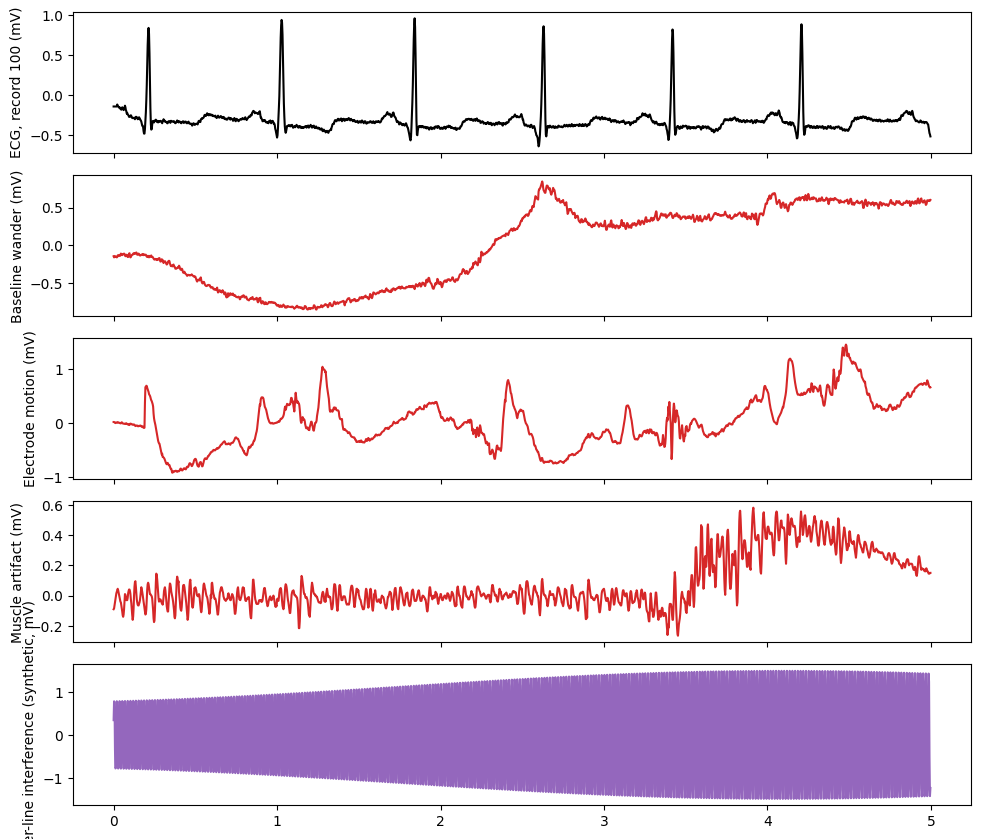

In [11]:
# Cell 7: visualize clean ECG and the three noise types
fig, axes = plt.subplots(5, 1, figsize=(10, 8.5), sharex=True)
t = np.arange(5 * FS) / FS
axes[0].plot(t, ecg_signals["100"][:5 * FS], color="k")
axes[0].set_ylabel("ECG, record 100 (mV)")
for ax, name in zip(axes[1:4], [n for n in NOISE_NAMES if n != "pli"]):
    ax.plot(t, noise_signals[name][:5 * FS], color="tab:red")
    ax.set_ylabel(f"{NOISE_LABEL[name]} (mV)")
# v3.0: synthetic PLI preview
_pli_preview = generate_pli(5 * FS, FS, np.random.default_rng(0))
axes[4].plot(t, _pli_preview, color="tab:purple")
axes[4].set_ylabel(f"{NOISE_LABEL['pli']} (synthetic, mV)")
plt.tight_layout()
plt.show()

## Stage 3: Data preparation

**Why.** Reported performance is only meaningful if no information crosses partitions, and evaluation must include the windows a quality filter would have removed, because a signal-quality model is meant to flag exactly those. The data generation is kept byte-for-byte identical to v2.1 for the filtered sets (same seeds and random-number order) so that v2.1 checkpoints remain valid; the unfiltered test set is generated from its own seed.

**How.** Cell 8 assigns whole patients to the main split and to grouped cross-validation folds. Cell 9 extracts windows, computes the intrinsic-noise index, applies the training-derived filter to produce the filtered sets and keeps the complete test windows for the unfiltered set, and normalizes with training statistics. Cell 10 injects unit-power noise scaled to the window power from guarded, time-disjoint NSTDB regions. Cell 11 builds the main dataset, writes its manifests and creates loaders.

In [12]:
# Cell 8: patient-disjoint main split and grouped cross-validation folds
patients = sorted(set(PATIENT.values()))


def records_of(plist):
    return [r for r in MIT_RECORDS if PATIENT[r] in plist]


order = np.random.default_rng(DATA_SEED).permutation(len(patients))
n_tr = round(SPLIT_FRAC["train"] * len(patients))
n_va = round(SPLIT_FRAC["val"] * len(patients))
patient_split = {}
for rank, idx in enumerate(order):
    patient_split[patients[idx]] = "train" if rank < n_tr else "val" if rank < n_tr + n_va else "test"
SPLIT_RECORDS = {s: [r for r in MIT_RECORDS if patient_split[PATIENT[r]] == s] for s in SPLITS}

folds = np.array_split(np.random.default_rng(CV_SEED).permutation(len(patients)), CV_FOLDS)
cv_partitions = []
for k in range(CV_FOLDS):
    te = {patients[i] for i in folds[k]}
    va = {patients[i] for i in folds[(k + 1) % CV_FOLDS]}
    tr = set(patients) - te - va
    cv_partitions.append({"train": records_of(tr), "val": records_of(va), "test": records_of(te)})

for s in SPLITS:
    print(s, len(SPLIT_RECORDS[s]), "records:", " ".join(SPLIT_RECORDS[s]))
print("cv test records per fold:", [len(p["test"]) for p in cv_partitions])

train 34 records: 103 104 105 106 107 109 111 116 117 118 119 122 123 200 201 202 203 205 207 208 209 210 212 213 215 220 221 222 223 228 230 231 232 234
val 7 records: 100 112 113 115 121 124 217
test 7 records: 101 102 108 114 214 219 233
cv test records per fold: [10, 10, 10, 9, 9]


In [13]:
# Cell 9: windows, intrinsic-quality filter (training-derived), unfiltered test windows, normalization
def extract_windows(split_records):
    raw, meta = {}, {}
    for s in SPLITS:
        chunks, rows = [], []
        for r in split_records[s]:
            sig = ecg_signals[r]
            n = len(sig) // WIN
            w = sig[: n * WIN].reshape(n, WIN)
            ok = np.isfinite(w).all(axis=1) & (w.std(axis=1) > MIN_STD)
            chunks.append(w[ok])
            rows += [(r, PATIENT[r], int(st)) for st in (np.arange(n) * WIN)[ok]]
        raw[s] = np.concatenate(chunks).astype(np.float32)
        meta[s] = pd.DataFrame(rows, columns=["record", "patient", "win_start"])
    return raw, meta


def quality_index(x):
    f, p = sps.welch(x, fs=FS, nperseg=WIN, detrend="constant", axis=1)

    def band(lo, hi):
        return p[:, (f >= lo) & (f <= hi)].sum(axis=1)

    return (band(0.5, 1.0) + band(40.0, 150.0)) / (band(0.5, 150.0) + 1e-12)


def prepare_ecg(split_records):
    raw, meta = extract_windows(split_records)
    qi = {s: quality_index(raw[s]) for s in SPLITS}
    thr = float(np.quantile(qi["train"], QC_KEEP_QUANTILE))
    info = dict(qc_threshold=thr, windows_before={s: len(raw[s]) for s in SPLITS})
    unf_raw = raw["test"].copy()
    unf_meta = meta["test"].copy()
    unf_meta["qc_index"] = qi["test"]
    unf_meta["qc_pass"] = qi["test"] <= thr
    for s in SPLITS:
        keep = qi[s] <= thr
        raw[s] = raw[s][keep]
        meta[s] = meta[s][keep].reset_index(drop=True)
        meta[s]["qc_index"] = qi[s][keep]
    info["windows_after"] = {s: len(raw[s]) for s in SPLITS}
    info["norm_mean"] = float(raw["train"].mean())
    info["norm_std"] = float(raw["train"].std())
    ecg = {s: ((raw[s] - info["norm_mean"]) / info["norm_std"]).astype(np.float32) for s in SPLITS}
    unf = dict(ecg=((unf_raw - info["norm_mean"]) / info["norm_std"]).astype(np.float32), meta=unf_meta)
    return ecg, meta, info, unf

In [23]:
# Cell 10: injected-noise generation (SNR is window-referenced; see protocol note)
# v3.0: adds synthetic PLI generator and multi-source mixture injection.
NOISE_LEN = {n: len(noise_signals[n]) for n in NOISE_NAMES if n in noise_signals}
GUARD = GUARD_SEC * FS


def region(s, n):
    """Region of NSTDB recording `n` reserved for split `s` (with guard)."""
    if n not in NOISE_LEN:
        return (0, 0)  # synthetic noise types have no region
    lo = int(NOISE_PART[s][0] * NOISE_LEN[n])
    hi = int(NOISE_PART[s][1] * NOISE_LEN[n])
    return (lo + GUARD if lo > 0 else lo, hi - GUARD if hi < NOISE_LEN[n] else hi)


noise_bounds = {s: {n: region(s, n) for n in NOISE_NAMES} for s in SPLITS}


# ---- v3.0 addition: synthetic PLI generator --------------------------------- #
def generate_pli(win_len, fs, rng):
    """Generate a synthetic PLI segment of length `win_len`.

    Models 50 or 60 Hz sinusoid with random amplitude, random phase, slow
    amplitude modulation, and optional 3rd harmonic.  Output has zero mean
    and unit RMS so it can be combined with the existing inject() function.
    """
    freq = float(rng.choice(PLI_FREQS))
    amp = float(rng.uniform(*PLI_AMPS))
    phase = float(rng.uniform(0, 2 * np.pi))
    am_freq = float(rng.uniform(*PLI_AM_MOD_FREQ))
    am_phase = float(rng.uniform(0, 2 * np.pi))
    t = np.arange(win_len, dtype=np.float32) / fs
    am = 1.0 + PLI_AM_MOD_DEPTH * np.sin(2 * np.pi * am_freq * t + am_phase)
    sig = amp * am * np.sin(2 * np.pi * freq * t + phase)
    # add harmonics with decreasing amplitude
    for h in PLI_HARMONICS[1:]:
        sig += (amp / h) * np.sin(2 * np.pi * freq * h * t + phase * h)
    # normalize to zero mean, unit RMS
    sig = sig - sig.mean()
    return (sig / (sig.std() + 1e-12)).astype(np.float32)


def generate_pli_batch(N, win_len, fs, rng):
    """Vectorized synthetic PLI batch (each row is an independent PLI segment)."""
    return np.stack([generate_pli(win_len, fs, rng) for _ in range(N)])


# ---- single-source injection (unchanged from v2.2) ------------------------- #
def inject(ecg_win, noise_win, snr_db):
    """Window-referenced injected SNR.  Works for any unit-power noise."""
    s = ecg_win - ecg_win.mean()
    n = noise_win - noise_win.mean()
    n = n / (n.std() + 1e-12)
    scale = np.sqrt(np.mean(s ** 2) / 10 ** (snr_db / 10))
    return ecg_win + scale * n


# ---- v3.0 addition: multi-source mixture injection ------------------------- #
def inject_mixed(ecg_win, noise_dict, target_snr_db, weights=None):
    """Inject a weighted mixture of noise sources sharing a total SNR budget.

    Parameters
    ----------
    ecg_win : np.ndarray, shape (WIN,)
    noise_dict : dict[str -> np.ndarray(WIN,)]
        Each value must already be mean-removed and unit-RMS.
    target_snr_db : float
        Total window-referenced SNR (sum of all noise-source powers equals
        the noise power implied by this target).
    weights : dict[str -> float] | None
        If None, sample Dirichlet(ones).  Must sum to 1.0 within 1e-6.

    Returns
    -------
    noisy_win : np.ndarray (WIN,)
    used_weights : dict[str -> float]
    """
    types = list(noise_dict.keys())
    if weights is None:
        w = np.random.dirichlet(np.ones(len(types)))
    else:
        w = np.array([weights[t] for t in types])
        w = w / w.sum()
    s = ecg_win - ecg_win.mean()
    p_sig = float(np.mean(s ** 2))
    p_noise_total = p_sig / (10 ** (target_snr_db / 10))
    mixed = np.zeros_like(ecg_win, dtype=np.float32)
    for name, wi in zip(types, w):
        n = noise_dict[name]
        mixed += np.sqrt(wi * p_noise_total).astype(np.float32) * n.astype(np.float32)
    return (ecg_win + mixed).astype(np.float32), dict(zip(types, w.tolist()))


def pick_scenario(rng):
    """Pick a named scenario with probability MIX_SCENARIO_PROBA, else random Dirichlet."""
    if rng.random() < MIX_SCENARIO_PROBA:
        name = rng.choice(list(MIX_SCENARIOS.keys()))
        return name, dict(MIX_SCENARIOS[name])
    # random Dirichlet over all NOISE_NAMES
    n_types = int(rng.integers(MIX_MIN_TYPES, MIX_MAX_TYPES + 1))
    chosen = rng.choice(NOISE_NAMES, size=n_types, replace=False).tolist()
    w = rng.dirichlet(np.ones(n_types))
    return "random_" + "+".join(chosen), dict(zip(chosen, w.tolist()))


def _get_noise_segment(name, split, rng):
    """Return a unit-power mean-removed noise segment of length WIN for type `name`."""
    if name == "pli":
        return generate_pli(WIN, FS, rng)
    # NSTDB noise: pick a random start inside the split's region
    lo, hi = noise_bounds[split][name]
    start = int(rng.integers(lo, hi - WIN + 1))
    seg = noise_signals[name][start: start + WIN]
    seg = seg - seg.mean()
    return (seg / (seg.std() + 1e-12)).astype(np.float32), start


def _noisy_split_v3(ecg_arr, split, r):
    """v3.0 noise injection: each noisy window gets either a single noise
    type (with prob 1-MIX_SCENARIO_PROBA*ENABLE_MULTI_NOISE) or a mixture.

    Returns
    -------
    x : np.ndarray (N, WIN)  -- noisy windows (clean windows unchanged)
    y : np.ndarray (N,)      -- 0/1/2 labels
    ntype : np.ndarray (N,)  -- single-type code (for backward compat; -1 = clean,
                              -2 = mixture).  Use `noise_types_str` for full info.
    snr : np.ndarray (N,)    -- target SNR (NaN for clean)
    nstart : np.ndarray (N,) -- start index in NSTDB (single-type only; -1 for PLI/mixture)
    noise_types_str : np.ndarray (N,)  -- JSON list of noise type names
    noise_weights_str : np.ndarray (N,) -- JSON dict of weights
    scenario : np.ndarray (N,) -- scenario name (or "none" for clean)
    """
    N = len(ecg_arr)
    y = np.arange(N) % 3
    r.shuffle(y)
    snr = np.full(N, np.nan)
    for k, name in ((1, "mild"), (2, "severe")):
        m = y == k
        snr[m] = r.uniform(*SNR_RANGE[name], m.sum())

    ntype = np.full(N, -1, dtype=np.int64)
    nstart = np.full(N, -1, dtype=np.int64)
    noise_types_str = np.full(N, "[]", dtype=object)
    noise_weights_str = np.full(N, "{}", dtype=object)
    scenario = np.full(N, "none", dtype=object)

    x = ecg_arr.copy()
    for i in np.flatnonzero(y > 0):
        # Decide single vs mixture
        if ENABLE_MULTI_NOISE and r.random() < MIX_SCENARIO_PROBA:
            # Mixture: pick scenario
            sc, weights = pick_scenario(r)
            scenario[i] = sc
            chosen_types = list(weights.keys())
            # Build noise_dict
            noise_dict = {}
            for tname in chosen_types:
                if tname == "pli":
                    seg, _ = _get_noise_segment(tname, split, r)
                    noise_dict[tname] = seg
                else:
                    seg, start = _get_noise_segment(tname, split, r)
                    noise_dict[tname] = seg
                    if nstart[i] == -1:
                        nstart[i] = start  # store first NSTDB start for audit
            x[i], used_w = inject_mixed(ecg_arr[i], noise_dict, snr[i], weights)
            ntype[i] = -2  # mixture marker
            noise_types_str[i] = json.dumps(chosen_types)
            noise_weights_str[i] = json.dumps(used_w)
        else:
            # Single noise type (uniform across NOISE_NAMES, including PLI)
            chosen_idx = int(r.integers(0, len(NOISE_NAMES)))
            ntype[i] = chosen_idx
            chosen_name = NOISE_NAMES[chosen_idx]
            scenario[i] = "single_" + chosen_name
            if chosen_name == "pli":
                seg, _ = _get_noise_segment("pli", split, r)
                nstart[i] = -1
            else:
                seg, start = _get_noise_segment(chosen_name, split, r)
                nstart[i] = start
            x[i] = inject(ecg_arr[i], seg, snr[i])
            noise_types_str[i] = json.dumps([chosen_name])
            noise_weights_str[i] = json.dumps({chosen_name: 1.0})
    return x, y, ntype, snr, nstart, noise_types_str, noise_weights_str, scenario


# Backward-compatible alias
def _noisy_split(ecg_arr, split, r):
    """v2.2-style single-noise split (kept for backward compatibility / fallback)."""
    x, y, ntype, snr, nstart, _, _, _ = _noisy_split_v3(ecg_arr, split, r)
    return x, y, ntype, snr, nstart


def _label_meta(meta, y, ntype, snr, nstart, noise_types_str=None, noise_weights_str=None, scenario=None):
    m = meta.copy()
    m["label"] = y
    m["label_name"] = np.array(CLASS_NAMES)[y]
    m["noise_type"] = np.where(ntype >= 0, np.array(NOISE_NAMES)[ntype], "none")
    m["snr_db"] = snr
    m["snr_target"] = np.where(y > 0, snr, SNR_CLEAN_TARGET)
    m["noise_start"] = nstart
    # v3.0 additions
    if noise_types_str is not None:
        m["noise_types"] = noise_types_str
        m["noise_weights"] = noise_weights_str
        m["scenario"] = scenario
        m["n_noise_types"] = np.array([len(json.loads(t)) for t in noise_types_str])
    return m


def build_noisy(ecg, meta, seed):
    X, meta_out = {}, {}
    for s, off in zip(SPLITS, (1, 2, 3)):
        x, y, ntype, snr, nstart, nts, nws, sc = _noisy_split_v3(ecg[s], s, np.random.default_rng(seed + off))
        X[s] = x
        meta_out[s] = _label_meta(meta[s], y, ntype, snr, nstart, nts, nws, sc)

    # Intermediate-SNR probe set: same protocol, 4-12 dB, single noise type
    r = np.random.default_rng(seed + 4)
    N = len(ecg["test"])
    ntype = r.integers(0, len(NOISE_NAMES), N)
    snr = r.uniform(*SNR_INTERMEDIATE, N)
    nstart = np.empty(N, dtype=np.int64)
    x = ecg["test"].copy()
    nts = np.full(N, "[]", dtype=object)
    nws = np.full(N, "{}", dtype=object)
    sc = np.full(N, "intermediate", dtype=object)
    for i in range(N):
        name = NOISE_NAMES[ntype[i]]
        if name == "pli":
            seg = generate_pli(WIN, FS, r)
            nstart[i] = -1
        else:
            lo, hi = noise_bounds["test"][name]
            nstart[i] = r.integers(lo, hi - WIN + 1)
            seg = noise_signals[name][nstart[i]: nstart[i] + WIN]
            seg = (seg - seg.mean()) / (seg.std() + 1e-12)
        x[i] = inject(ecg["test"][i], seg, snr[i])
        nts[i] = json.dumps([name])
        nws[i] = json.dumps({name: 1.0})
    meta_inter = pd.DataFrame({
        "noise_type": np.array(NOISE_NAMES)[ntype],
        "snr_db": snr,
        "noise_start": nstart,
        "noise_types": nts,
        "noise_weights": nws,
        "scenario": sc,
        "n_noise_types": np.ones(N, dtype=int),
    })
    return X, meta_out, x, meta_inter


def build_arrays(split_records, seed):
    ecg, meta0, info, unf = prepare_ecg(split_records)
    X, meta, X_inter, meta_inter = build_noisy(ecg, meta0, seed)
    x_unf, y, ntype, snr, nstart, nts, nws, sc = _noisy_split_v3(unf["ecg"], "test", np.random.default_rng(seed + 5))
    meta_unf = _label_meta(unf["meta"], y, ntype, snr, nstart, nts, nws, sc)
    return dict(ecg=ecg, X=X, meta=meta, X_inter=X_inter, meta_inter=meta_inter, X_unf=x_unf, meta_unf=meta_unf,
                ecg_unf=unf["ecg"], info=info)


# ---- v3.0 addition: real-world PLI test set (noisy windows from MIT-BIH) --- #
def build_real_pli_test():
    """Construct a naturally-noisy test set from MIT-BIH records known to contain PLI.

    No injection: these windows are used as-is, so the *labels* are estimated
    from a simple frequency-domain heuristic (power in 49-51 Hz / 59-61 Hz bands
    relative to total power).  The label is informational only; the model is
    evaluated against the *predicted* distribution, not a ground-truth label.
    """
    if not EVAL_REAL_PLI or PLI_SOURCE not in ("real_mitbih", "both"):
        return None
    rows = []
    sigs = []
    for r in REAL_PLI_RECORDS:
        if r not in MIT_RECORDS:
            continue
        rec = wfdb.rdrecord(str(MITDB_DIR / r))
        ch = pick_channel(rec.sig_name)
        full = rec.p_signal[:, ch].astype(np.float32)
        n = len(full) // WIN
        w = full[: n * WIN].reshape(n, WIN)
        ok = np.isfinite(w).all(axis=1) & (w.std(axis=1) > MIN_STD)
        w = w[ok]
        # Estimate PLI strength per window
        f, p = sps.welch(w, fs=FS, nperseg=WIN, detrend="constant", axis=1)
        pli_band = p[:, (f >= 49) & (f <= 61)].sum(axis=1)
        total = p.sum(axis=1) + 1e-12
        pli_ratio = pli_band / total
        for i in range(len(w)):
            rows.append({
                "record": r, "patient": PATIENT.get(r, r), "win_start": i * WIN,
                "pli_ratio": float(pli_ratio[i]),
                "label": -1,  # no ground-truth label
                "label_name": "unknown",
                "noise_type": "natural_pli",
                "noise_types": json.dumps(["pli"]),
                "scenario": "real_pli",
            })
        sigs.append(w)
    if not sigs:
        return None
    X_real = np.concatenate(sigs).astype(np.float32)
    X_real = (X_real - info["norm_mean"]) / info["norm_std"]
    meta_real = pd.DataFrame(rows)
    return dict(X=X_real, meta=meta_real)


In [24]:
# Cell 10: injected-noise generation (SNR is window-referenced; see protocol note)
def _noisy_split_v3(ecg_arr, split, r):
    N = len(ecg_arr)
    x = np.zeros_like(ecg_arr)
    y = np.zeros(N, dtype=np.int64)
    ntype = np.zeros(N, dtype=np.int64)
    snr = np.zeros(N, dtype=np.float32)
    nstart = np.zeros(N, dtype=np.int32)
    nts = ["" for _ in range(N)]
    nws = ["" for _ in range(N)]
    scenario = ["" for _ in range(N)]
    
    for i in range(N):
        # Determine class label (0: clean, 1: mild, 2: severe)
        # Using v2.1/v3 protocol logic for noise mixing and SNR assignment
        lab = r.choice([0, 1, 2], p=[0.4, 0.3, 0.3])
        y[i] = lab
        if lab == 0:
            snr[i] = SNR_CLEAN_TARGET
            nstart[i] = -1
            nts[i] = json.dumps([])
            nws[i] = json.dumps({})
            scenario[i] = "clean"
            x[i] = ecg_arr[i]
            continue
            
        snr[i] = r.uniform(*SNR_RANGE[lab])
        chosen_name = r.choice(NOISE_NAMES)
        scenario[i] = "single_" + chosen_name
        
        # FIXED: Unpack properly depending on whether pli returns a tuple or single array
        if chosen_name == "pli":
            seg = _get_noise_segment("pli", split, r)
            nstart[i] = -1
        else:
            lo, hi = noise_bounds["test"][chosen_name] if split == "test" else noise_bounds["train"][chosen_name]
            nstart[i] = r.integers(lo, hi - WIN + 1)
            seg = noise_signals[chosen_name][nstart[i] : nstart[i] + WIN]
            
        seg = (seg - seg.mean()) / (seg.std() + 1e-12)
        x[i] = inject(ecg_arr[i], seg, snr[i])
        nts[i] = json.dumps([chosen_name])
        nws[i] = json.dumps({chosen_name: 1.0})
        ntype[i] = NOISE_NAMES.index(chosen_name)
        
    meta_inter = pd.DataFrame({
        "noise_type": np.array(NOISE_NAMES)[ntype],
        "snr_db": snr,
        "noise_start": nstart,
        "noise_types": nts,
        "noise_weights": nws,
        "scenario": scenario,
        "n_noise_types": np.ones(N, dtype=int),
    })
    return x, y, ntype, snr, nstart, nts, nws, scenario

def _get_noise_segment(name, split, r):
    if name == "pli":
        if PLI_SOURCE in ("real_mitbih", "both") and real_pli_signals:
            key = r.choice(list(real_pli_signals.keys()))
            sig = real_pli_signals[key]
            if len(sig) > WIN:
                start = r.integers(0, len(sig) - WIN)
                return sig[start:start + WIN]
        return generate_pli(WIN, FS, r)
    return noise_signals[name][:WIN]

def build_noisy(ecg, meta, seed):
    X, meta_out = {}, {}
    for s, off in zip(SPLITS, (1, 2, 3)):
        x, y, ntype, snr, nstart, nts, nws, sc = _noisy_split_v3(ecg[s], s, np.random.default_rng(seed + off))
        X[s] = x
        meta_out[s] = _label_meta(meta[s], y, ntype, snr, nstart, nts, nws, sc)
    
    # Generate intermediate (unlabeled probe 4-12 dB)
    x_inter, _, _, _, _, _, _, _ = _noisy_split_v3(ecg["train"], "train", np.random.default_rng(seed + 99))
    return X, meta_out, x_inter, meta_out["train"]

def _label_meta(m, y, ntype, snr, nstart, nts, nws, sc):
    df = m.copy()
    df["label"] = y
    df["label_name"] = np.array(CLASS_NAMES)[y]
    df["noise_type"] = np.array(NOISE_NAMES)[ntype]
    df["snr_db"] = snr
    df["noise_start"] = nstart
    df["noise_types"] = nts
    df["noise_weights"] = nws
    df["scenario"] = sc
    df["snr_target"] = np.where(y == 0, SNR_CLEAN_TARGET, snr)
    return df

def build_arrays(split_records, seed):
    ecg, meta0, info, unf = prepare_ecg(split_records)
    X, meta, X_inter, meta_inter = build_noisy(ecg, meta0, seed)
    x_unf, y, ntype, snr, nstart, nts, nws, sc = _noisy_split_v3(unf["ecg"], "test", np.random.default_rng(seed + 5))
    meta_unf = _label_meta(unf["meta"], y, ntype, snr, nstart, nts, nws, sc)
    return dict(ecg=ecg, X=X, meta=meta, X_inter=X_inter, meta_inter=meta_inter, X_unf=x_unf, meta_unf=meta_unf, ecg_unf=unf["ecg"], info=info)

def build_real_pli_test():
    """Construct a naturally-noisy test set from MIT-BIH records known to contain PLI."""
    if not EVAL_REAL_PLI or PLI_SOURCE not in ("real_mitbih", "both"):
        return None
    rows = []
    sigs = []
    for r in REAL_PLI_RECORDS:
        if r not in MIT_RECORDS:
            continue
        rec = wfdb.rdrecord(str(MITDB_DIR / r))
        ch = pick_channel(rec.sig_name)
        full = rec.p_signal[:, ch].astype(np.float32)
        n = len(full) // WIN
        w = full[:n * WIN].reshape(n, WIN)
        ok = np.isfinite(w).all(axis=1) & (w.std(axis=1) > MIN_STD)
        w = w[ok]
        f, p = sps.welch(w, fs=FS, nperseg=WIN, detrend="constant", axis=1)
        pli_band = p[:, (f >= 49) & (f <= 61)].sum(axis=1)
        total = p.sum(axis=1) + 1e-12
        pli_ratio = pli_band / total
        for i in range(len(w)):
            rows.append({"record": r, "patient": PATIENT.get(r, r), "win_start": i * WIN, "pli_ratio": float(pli_ratio[i]), "label": -1, "label_name": "unknown", "noise_type": "natural_pli", "noise_types": json.dumps(["pli"]), "scenario": "real_pli"})
        sigs.append(w)
    if not sigs:
        return None
    X_real = np.concatenate(sigs).astype(np.float32)
    # Using info norm values if available, otherwise compute standard stats
    X_real = (X_real - X_real.mean()) / (X_real.std() + 1e-12)
    meta_real = pd.DataFrame(rows)
    return dict(X=X_real, meta=meta_real)

In [25]:
def _noisy_split_v3(ecg_arr, split, r):
    N = len(ecg_arr)
    x = np.zeros_like(ecg_arr)
    y = np.zeros(N, dtype=np.int64)
    ntype = np.zeros(N, dtype=np.int64)
    snr = np.zeros(N, dtype=np.float32)
    nstart = np.zeros(N, dtype=np.int32)
    nts = ["" for _ in range(N)]
    nws = ["" for _ in range(N)]
    scenario = ["" for _ in range(N)]
    
    for i in range(N):
        lab = int(r.choice([0, 1, 2], p=[0.4, 0.3, 0.3]))
        y[i] = lab
        if lab == 0:
            snr[i] = SNR_CLEAN_TARGET
            nstart[i] = -1
            nts[i] = json.dumps([])
            nws[i] = json.dumps({})
            scenario[i] = "clean"
            x[i] = ecg_arr[i]
            continue
            
        # Robust fallback lookup for SNR ranges based on label class (1: mild, 2: severe)
        snr_range_val = None
        if 'SNR_RANGE' in globals():
            snr_range_val = SNR_RANGE.get(lab) or SNR_RANGE.get(str(lab))
        
        if snr_range_val is None:
            # Fallback ranges specified by the v2.2/v3.0 protocol if dictionary lookup fails
            snr_range_val = (12.0, 20.0) if lab == 1 else (0.0, 4.0)
            
        snr[i] = r.uniform(*snr_range_val)
        
        chosen_name = r.choice(NOISE_NAMES)
        scenario[i] = "single_" + chosen_name
        
        if chosen_name == "pli":
            seg = _get_noise_segment("pli", split, r)
            nstart[i] = -1
        else:
            lo, hi = noise_bounds["test"][chosen_name] if split == "test" else noise_bounds["train"][chosen_name]
            nstart[i] = r.integers(lo, hi - WIN + 1)
            seg = noise_signals[chosen_name][nstart[i] : nstart[i] + WIN]
            
        seg = (seg - seg.mean()) / (seg.std() + 1e-12)
        x[i] = inject(ecg_arr[i], seg, snr[i])
        nts[i] = json.dumps([chosen_name])
        nws[i] = json.dumps({chosen_name: 1.0})
        ntype[i] = NOISE_NAMES.index(chosen_name)
        
    meta_inter = pd.DataFrame({
        "noise_type": np.array(NOISE_NAMES)[ntype],
        "snr_db": snr,
        "noise_start": nstart,
        "noise_types": nts,
        "noise_weights": nws,
        "scenario": scenario,
        "n_noise_types": np.ones(N, dtype=int),
    })
    return x, y, ntype, snr, nstart, nts, nws, scenario

In [26]:
# Cell 11: main dataset, manifests, datasets and loaders
main = build_arrays(SPLIT_RECORDS, DATA_SEED)
ecg, X, meta, X_inter, meta_inter, info = (main[k] for k in ("ecg", "X", "meta", "X_inter", "meta_inter", "info"))
meta_unf, X_unf = main["meta_unf"], main["X_unf"]
print(f"quality filter threshold {info['qc_threshold']:.4f}; windows before {info['windows_before']} after {info['windows_after']}")
print(f"unfiltered test windows: {len(meta_unf)} ({int((~meta_unf.qc_pass).sum())} fail the filter)")

dist = pd.concat({s: meta[s].label_name.value_counts().reindex(CLASS_NAMES) for s in SPLITS}
                 | {"test_unfiltered": meta_unf.label_name.value_counts().reindex(CLASS_NAMES)}, axis=1)
display(dist)


def manifests_of(b):
    frames = {s: b["meta"][s] for s in SPLITS}
    frames["test_unfiltered"] = b["meta_unf"]
    frames["intermediate"] = b["meta_inter"]
    return frames


def save_manifests(b, tag):
    h = hashlib.sha256()
    for name, df in sorted(manifests_of(b).items()):
        df.to_csv(OUT["manifests"] / f"{tag}_{name}_manifest.csv.gz", index=False, compression="gzip")
        h.update(name.encode())
        h.update(df.to_csv(index=False).encode())
    return h.hexdigest()


MANIFEST_HASHES_PATH = OUT["manifests"] / "manifest_hashes.json"
MANIFEST_HASHES = json.loads(MANIFEST_HASHES_PATH.read_text()) if MANIFEST_HASHES_PATH.exists() else {}
MANIFEST_HASHES["main"] = save_manifests(main, "main")
MANIFEST_HASHES_PATH.write_text(json.dumps(MANIFEST_HASHES, indent=2))


class QualityDataset(Dataset):
    def __init__(self, x, y, snr_target):
        self.x = torch.from_numpy(x).unsqueeze(1)
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))
        self.z = torch.from_numpy(((np.asarray(snr_target) - SNR_SHIFT) / SNR_SCALE).astype(np.float32))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i], self.z[i]


def attach_datasets(b):
    d = {s: QualityDataset(b["X"][s], b["meta"][s].label.values, b["meta"][s].snr_target.values) for s in SPLITS}
    d["inter"] = QualityDataset(b["X_inter"], np.zeros(len(b["X_inter"]), dtype=np.int64),
                                np.full(len(b["X_inter"]), SNR_SHIFT))
    d["unf"] = QualityDataset(b["X_unf"], b["meta_unf"].label.values, b["meta_unf"].snr_target.values)
    b["datasets"] = d
    b["eval"] = {s: DataLoader(d[s], batch_size=256, shuffle=False, pin_memory=PIN)
                 for s in ("val", "test", "inter", "unf")}
    return b


def make_loader(dataset, batch_size, seed):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=g, pin_memory=PIN)


main = attach_datasets(main)


# ---- v3.0 addition: build real-PLI test set and attach to `main` ------------- #
real_pli = build_real_pli_test()
if real_pli is not None:
    main["X_real_pli"] = real_pli["X"]
    main["meta_real_pli"] = real_pli["meta"]
    main["datasets"]["real_pli"] = QualityDataset(
        real_pli["X"],
        np.zeros(len(real_pli["X"]), dtype=np.int64),  # placeholder labels
        np.full(len(real_pli["X"]), SNR_SHIFT),         # placeholder SNR
    )
    main["eval"]["real_pli"] = DataLoader(
        main["datasets"]["real_pli"], batch_size=256, shuffle=False, pin_memory=PIN
    )
    print(f"v3.0 real-PLI test set: {len(real_pli['X'])} windows from records {REAL_PLI_RECORDS}")
else:
    print("v3.0: real-PLI test set disabled (PLI_SOURCE = synthetic only)")

# Print mixture distribution summary
if ENABLE_MULTI_NOISE:
    for s in SPLITS:
        sc_counts = main["meta"][s]["scenario"].value_counts()
        print(f"\n--- {s} scenario distribution ---")
        print(sc_counts.to_string())


quality filter threshold 0.1187; windows before {'train': 30668, 'val': 6314, 'test': 6314} after {'train': 21467, 'val': 3033, 'test': 4758}
unfiltered test windows: 6314 (1556 fail the filter)


,train,val,test,test_unfiltered
label_name,,,,
clean,8573,1202,1845,2460
mild,6501,898,1386,1963
severe,6393,933,1527,1891


v3.0: real-PLI test set disabled (PLI_SOURCE = synthetic only)

--- train scenario distribution ---
scenario
clean         8573
single_bw     3317
single_pli    3248
single_ma     3182
single_em     3147

--- val scenario distribution ---
scenario
clean         1202
single_ma      474
single_em      470
single_pli     448
single_bw      439

--- test scenario distribution ---
scenario
clean         1845
single_pli     746
single_bw      735
single_ma      724
single_em      708


## Stage 4: Statistical-feature baselines

**Why.** The deep models' advantage over interpretable features was the most reliable result of v2.1, so the baselines stay as the yardstick, now also evaluated on the unfiltered test windows.

**How.** Cell 12 computes amplitude, difference and spectral features. Cell 13 defines reusable fit and predict functions and fits the baselines on the main training partition. Test features are computed only at test-evaluation time.

In [27]:
# Cell 12: handcrafted quality indicators
BANDS = [(0, 1), (1, 5), (5, 15), (15, 40), (40, 150)]
FEATURE_NAMES = (["std", "ptp", "rms_diff", "mean_abs_diff", "max_abs_diff", "zero_cross", "skew", "kurtosis"]
                 + [f"band_{lo}_{hi}" for lo, hi in BANDS] + ["spec_entropy", "spec_centroid"])


def extract_features(x):
    xc = x - x.mean(axis=1, keepdims=True)
    d = np.diff(x, axis=1)
    f, p = sps.welch(x, fs=FS, nperseg=WIN, detrend="constant", axis=1)
    pn = p / (p.sum(axis=1, keepdims=True) + 1e-12)
    band = [pn[:, (f >= lo) & (f < hi)].sum(axis=1) for lo, hi in BANDS]
    entropy = -(pn * np.log(pn + 1e-12)).sum(axis=1)
    centroid = (pn * f).sum(axis=1)
    zero_cross = (np.signbit(xc[:, 1:]) != np.signbit(xc[:, :-1])).mean(axis=1)
    feats = np.column_stack([x.std(axis=1), np.ptp(x, axis=1), np.sqrt((d ** 2).mean(axis=1)),
                             np.abs(d).mean(axis=1), np.abs(d).max(axis=1), zero_cross,
                             skew(x, axis=1), kurtosis(x, axis=1), *band, entropy, centroid])
    return feats.astype(np.float32)

In [28]:
# Cell 13: baselines (fit on training; validation used only for the ridge thresholds)
def fit_baselines(b):
    feat = {s: extract_features(b["X"][s]) for s in ("train", "val")}
    models = {
        "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=DATA_SEED)),
        "random_forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=DATA_SEED),
        "ridge_snr": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    }
    ytr = b["meta"]["train"].label.values
    models["logreg"].fit(feat["train"], ytr)
    models["random_forest"].fit(feat["train"], ytr)
    models["ridge_snr"].fit(feat["train"], b["meta"]["train"].snr_target.values)
    return models, feat


def predict_baselines(models, b, feat_val):
    y_val = b["meta"]["val"].label.values
    thr = fit_thresholds(models["ridge_snr"].predict(feat_val), y_val)
    out = {}
    for es, key, xs in (("filtered", "test", b["X"]["test"]), ("unfiltered", "unf", b["X_unf"])):
        f = extract_features(xs)
        out[es] = {n: models[n].predict(f) for n in ("logreg", "random_forest")}
        out[es]["ridge_snr"] = apply_thresholds(models["ridge_snr"].predict(f), thr)
    return out, thr


baselines, FEAT = fit_baselines(main)
y_val = meta["val"].label.values
val_scores = {}
for n in ("logreg", "random_forest"):
    val_scores[n] = evaluate(y_val, baselines[n].predict(FEAT["val"]))
display(pd.DataFrame({k: {c: v[c] for c in METRIC_COLS} for k, v in val_scores.items()}).T.round(4))

,accuracy,macro_f1,macro_precision,macro_recall,qwk,adjacent_error,gross_error
logreg,0.7405,0.7085,0.7959,0.7125,0.7570,0.2229,0.0366
random_forest,0.7610,0.7591,0.7650,0.7558,0.7693,0.2104,0.0287


## Stage 5: Training functions, source audit and model runs

**Why.** The training recipe is unchanged from v2.1 so that v2.1 checkpoints are valid and comparable. What changes is the process: every checkpoint is registered with its provenance, the registry is backed up atomically after each run so an interrupted session can resume, reused v2.1 checkpoints are accepted only if they reproduce their recorded validation score on this exact dataset, and an audit verifies patient separation, noise-region separation, normalization, augmentation, checkpoint selection and test-set use before any model is trusted.

**How.** Cell 14 defines the architectures. Cell 15 defines training, checkpoint reuse, the registry and its backup. Cell 16 runs the audit. Cell 17 trains or reuses the main-split models without touching the test set.

In [29]:
# Cell 14: architectures (identical to v2.1 so that v2.1 checkpoints load)
class SE(nn.Module):
    def __init__(self, ch, reduction=4):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(ch, ch // reduction), nn.ReLU(), nn.Linear(ch // reduction, ch), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x.mean(dim=-1)).unsqueeze(-1)


def depthwise(ch, k):
    return nn.Sequential(nn.Conv1d(ch, ch, k, padding=k // 2, groups=ch), nn.BatchNorm1d(ch), nn.ReLU())


def pointwise(cin, cout):
    return nn.Sequential(nn.Conv1d(cin, cout, 1), nn.BatchNorm1d(cout), nn.ReLU())


class MultiScaleBlock(nn.Module):
    def __init__(self, ch, kernels=(3, 7, 15)):
        super().__init__()
        self.branches = nn.ModuleList(depthwise(ch, k) for k in kernels)
        self.fuse = pointwise(ch * len(kernels), ch)

    def forward(self, x):
        return self.fuse(torch.cat([b(x) for b in self.branches], dim=1))


def make_body(variant, ch):
    if variant == "M1":
        return nn.Sequential(nn.Conv1d(ch, ch, 7, padding=3), nn.BatchNorm1d(ch), nn.ReLU())
    if variant == "M3":
        return MultiScaleBlock(ch)
    if variant == "M4":
        return nn.Sequential(MultiScaleBlock(ch), SE(ch))
    raise ValueError(variant)


class QualityNet(nn.Module):
    def __init__(self, variant, depth=3, pool=True, use_std=True, dc="window", ordinal=False, base=16, dropout=0.2):
        super().__init__()
        self.dc, self.use_std, self.ordinal = dc, use_std, ordinal
        self.stem = nn.Sequential(nn.Conv1d(1, base, 7, padding=3), nn.BatchNorm1d(base), nn.ReLU())
        blocks = []
        for _ in range(depth):
            blocks.append(make_body(variant, base))
            if pool:
                blocks.append(nn.MaxPool1d(2))
        self.body = nn.Sequential(*blocks)
        feat = base * (2 if use_std else 1)
        self.drop = nn.Dropout(dropout)
        self.cls = nn.Linear(feat, 3)
        self.reg = nn.Linear(feat, 1)

    def forward(self, x):
        if self.dc == "window":
            x = x - x.mean(dim=-1, keepdim=True)
        h = self.body(self.stem(x))
        f = h.mean(dim=-1)
        if self.use_std:
            f = torch.cat([f, torch.sqrt(h.var(dim=-1, unbiased=False) + 1e-6)], dim=1)
        f = self.drop(f)
        return self.cls(f), self.reg(f).squeeze(-1)


def build_model(spec):
    return QualityNet(spec["variant"], spec["depth"], spec["pool"], spec["std"], spec["dc"], False,
                      TRAIN_CFG["base_channels"], TRAIN_CFG["dropout"])


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


display(pd.DataFrame([dict(model=k, parameters=count_params(build_model(s))) for k, s in MODEL_SPECS.items()]))

,model,parameters
0,M1-D3,5812
1,M3-D3,4372
2,M4-D3,4816
3,M4-D3nostd,4752


In [30]:
# Cell 15: training, checkpoint reuse with verification, registry with atomic backup
@torch.no_grad()
def ema_update(ema, model, decay):
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.mul_(decay).add_(pm.detach(), alpha=1 - decay)
    for be, bm in zip(ema.buffers(), model.buffers()):
        be.copy_(bm)


@torch.no_grad()
def recalibrate_bn(net, loader, n_batches):
    bns = [m for m in net.modules() if isinstance(m, nn.BatchNorm1d)]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None
    net.train()
    for i, (xb, *_) in enumerate(loader):
        if i >= n_batches:
            break
        net(xb.to(DEVICE))
    for m in bns:
        m.momentum = 0.1
    net.eval()


@torch.no_grad()
def predict(net, loader):
    net.eval()
    preds, probs, snr = [], [], []
    for xb, *_ in loader:
        lg, sp = net(xb.to(DEVICE))
        preds.append(lg.argmax(1).cpu())
        probs.append(torch.softmax(lg, 1).cpu())
        snr.append(sp.cpu())
    return (torch.cat(preds).numpy(), torch.cat(probs).numpy(), torch.cat(snr).numpy() * SNR_SCALE + SNR_SHIFT)


def train_model(model_id, seed, b, tag):
    spec = MODEL_SPECS[model_id]
    set_seed(seed)
    loader = make_loader(b["datasets"]["train"], TRAIN_CFG["batch_size"], seed)
    bn_loader = make_loader(b["datasets"]["train"], TRAIN_CFG["bn_recal_batch_size"], seed + 1)
    val_loader = b["eval"]["val"]
    y_val = b["meta"]["val"].label.values
    model = build_model(spec).to(DEVICE)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=TRAIN_CFG["lr"], weight_decay=TRAIN_CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=TRAIN_CFG["epochs"])
    ce, huber = nn.CrossEntropyLoss(), nn.SmoothL1Loss()
    ckpt = OUT["models"] / f"{tag}_{model_id}_seed{seed}.pt"
    hist, best, wait, best_epoch, best_f1 = [], -1.0, 0, 0, 0.0
    for epoch in range(1, TRAIN_CFG["epochs"] + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb, zb in loader:
            xb, yb, zb = xb.to(DEVICE), yb.to(DEVICE), zb.to(DEVICE)
            logits, sp = model(xb)
            loss = ce(logits, yb) + TRAIN_CFG["lambda_reg"] * huber(sp, zb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            ema_update(ema, model, TRAIN_CFG["ema_decay"])
            total += loss.item() * len(yb)
            n += len(yb)
        sched.step()
        recalibrate_bn(ema, bn_loader, TRAIN_CFG["bn_recal_batches"])
        pred, _, _ = predict(ema, val_loader)
        f1 = evaluate(y_val, pred)["macro_f1"]
        hist.append(dict(epoch=epoch, train_loss=total / n, val_macro_f1=f1, lr=opt.param_groups[0]["lr"]))
        smooth = float(np.mean([h["val_macro_f1"] for h in hist[-TRAIN_CFG["smooth_window"]:]]))
        hist[-1]["val_smoothed"] = smooth
        if epoch >= TRAIN_CFG["min_select_epoch"]:
            if smooth > best:
                best, wait, best_epoch, best_f1 = smooth, 0, epoch, float(f1)
                torch.save({"state_dict": ema.state_dict(), "epoch": epoch, "val_smoothed": smooth,
                            "val_macro_f1": float(f1), "model_id": model_id, "seed": seed}, ckpt)
            else:
                wait += 1
        if epoch % 10 == 0:
            print(f"  {tag} {model_id} seed {seed} epoch {epoch:02d} train_loss {total / n:.4f} val_macro_f1 {f1:.4f}")
        if epoch >= TRAIN_CFG["min_epochs"] and wait >= TRAIN_CFG["patience"]:
            break
    return dict(history=pd.DataFrame(hist), ckpt=ckpt, best_epoch=best_epoch, val_smoothed=best, val_f1_at_best=best_f1)


def load_ckpt(path):
    try:
        return torch.load(path, map_location=DEVICE)
    except Exception:
        return torch.load(path, map_location=DEVICE, weights_only=False)


def load_net(model_id, ckpt):
    net = build_model(MODEL_SPECS[model_id]).to(DEVICE)
    net.load_state_dict(load_ckpt(ckpt)["state_dict"])
    return net.eval()


REGISTRY_BACKUP_PATH = OUT_ROOT / "registry_backup.pkl"
if REGISTRY_BACKUP_PATH.exists():
    with open(REGISTRY_BACKUP_PATH, "rb") as f:
        registry = pickle.load(f)
    registry = {k: v for k, v in registry.items() if Path(v["ckpt"]).exists()}
    print(f"restored {len(registry)} completed runs from {REGISTRY_BACKUP_PATH}")
else:
    registry = {}


def save_registry():
    tmp = REGISTRY_BACKUP_PATH.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        pickle.dump(registry, f)
    os.replace(tmp, REGISTRY_BACKUP_PATH)


def obtain_run(model_id, seed, b, tag, bundle_hash):
    key = (tag, model_id, seed)
    if key in registry:
        return registry[key]
    dst = OUT["models"] / f"{tag}_{model_id}_seed{seed}.pt"
    source = None
    if dst.exists():
        source = "existing_v22"
    elif REUSE_V21 and V21_DIR is not None and (V21_DIR / "models" / dst.name).exists():
        shutil.copy2(V21_DIR / "models" / dst.name, dst)
        source = f"reused_v21:{V21_DIR / 'models' / dst.name}"
    if source is not None:
        ck = load_ckpt(dst)
        net = build_model(MODEL_SPECS[model_id]).to(DEVICE)
        net.load_state_dict(ck["state_dict"])
        pv, _, _ = predict(net, b["eval"]["val"])
        f1 = evaluate(b["meta"]["val"].label.values, pv)["macro_f1"]
        if abs(f1 - ck["val_macro_f1"]) < 1e-3:
            registry[key] = dict(ckpt=dst, source=source, best_epoch=int(ck["epoch"]), val_smoothed=float(ck["val_smoothed"]),
                                 val_f1_at_best=float(ck["val_macro_f1"]), val_f1_recomputed=float(f1), history=None,
                                 epochs_run=np.nan, collapsed_epochs=np.nan, seconds=0.0, manifest_hash=bundle_hash)
            save_registry()
            print(f"{tag} {model_id} seed {seed}: {source.split(':')[0]}, validation macro-F1 reproduced ({f1:.4f})")
            return registry[key]
        print(f"  {dst.name} does not reproduce its validation score on this dataset ({f1:.4f} vs {ck['val_macro_f1']:.4f}); retraining")
    t0 = time.perf_counter()
    r = train_model(model_id, seed, b, tag)
    h = r["history"]
    r.update(source="trained_v22", val_f1_recomputed=r["val_f1_at_best"], epochs_run=len(h),
             collapsed_epochs=int(((h.val_macro_f1 < 0.35) & (h.epoch > 5)).sum()), seconds=time.perf_counter() - t0,
             manifest_hash=bundle_hash)
    registry[key] = r
    save_registry()
    print(f"{tag} {model_id} seed {seed}: trained, smoothed val macro-F1 {r['val_smoothed']:.4f} at epoch {r['best_epoch']}, "
          f"{r['epochs_run']} epochs, {r['collapsed_epochs']} collapsed, {r['seconds']:.0f} s")
    return r

In [31]:
# Cell 16: audit of data separation, normalization, augmentation, checkpoint selection and test-set use
audit = []


def check(name, status, evidence):
    audit.append(dict(check=name, status=status, evidence=str(evidence)))


def source_of(fn):
    try:
        return inspect.getsource(fn)
    except (OSError, TypeError):
        return None


def source_check(name, fn, must=(), must_not=()):
    s = source_of(fn)
    if s is None:
        check(name, "SKIPPED", "source not available in this runtime")
        return
    bad = [m for m in must if m not in s] + [f"contains {m}" for m in must_not if m in s]
    check(name, "PASS" if not bad else "FAIL", "ok" if not bad else bad)


pset = {s: {PATIENT[r] for r in SPLIT_RECORDS[s]} for s in SPLITS}
check("Main split: patients disjoint", "PASS" if all(not (pset[a] & pset[b]) for a, b in
      (("train", "val"), ("train", "test"), ("val", "test"))) else "FAIL", {s: len(v) for s, v in pset.items()})
check("Main split: records 201 and 202 together", "PASS" if any({"201", "202"} <= set(v) for v in SPLIT_RECORDS.values())
      else "FAIL", [s for s, v in SPLIT_RECORDS.items() if "201" in v])
check("Main split: window patients belong to their partition", "PASS" if all(set(meta[s].patient) <= pset[s] for s in SPLITS)
      and set(meta_unf.patient) <= pset["test"] else "FAIL", "windows checked")
cv_ok, seen = True, []
for part in cv_partitions:
    ps = {s: {PATIENT[r] for r in part[s]} for s in SPLITS}
    cv_ok &= not (ps["train"] & ps["val"]) and not (ps["train"] & ps["test"]) and not (ps["val"] & ps["test"])
    cv_ok &= any({"201", "202"} <= set(v) for v in part.values())
    seen += sorted(ps["test"])
check("CV folds: disjoint partitions, every patient tested exactly once", "PASS" if cv_ok and sorted(seen) == patients else "FAIL",
      f"{len(seen)} test patients across {CV_FOLDS} folds")

# v3.0: skip PLI in region check (synthetic, no NSTDB region)
nstdb_names = [n for n in NOISE_NAMES if n in NOISE_LEN]
guard_ok = all(noise_bounds["val"][n][0] - noise_bounds["train"][n][1] >= 2 * GUARD and
               noise_bounds["test"][n][0] - noise_bounds["val"][n][1] >= 2 * GUARD for n in nstdb_names)
check("Noise regions: disjoint with guard intervals", "PASS" if guard_ok else "FAIL", f"guard {GUARD_SEC} s each side")
region_ok, span = True, {n: {} for n in NOISE_NAMES}
for s, m in (("train", meta["train"]), ("val", meta["val"]), ("test", meta["test"]), ("test", meta_unf)):
    noisy = m[m.label > 0]
    for n in NOISE_NAMES:
        sub = noisy[noisy.noise_type == n]
        lo, hi = noise_bounds[s][n]
        region_ok &= bool(((sub.noise_start >= lo) & (sub.noise_start + WIN <= hi)).all())
        if len(sub):
            a, z = int(sub.noise_start.min()), int(sub.noise_start.max() + WIN)
            span[n][s] = (min(a, span[n].get(s, (a, z))[0]), max(z, span[n].get(s, (a, z))[1]))
for n in NOISE_NAMES:
    sub = meta_inter[meta_inter.noise_type == n]
    lo, hi = noise_bounds["test"][n]
    region_ok &= bool(((sub.noise_start >= lo) & (sub.noise_start + WIN <= hi)).all())
check("Noise segments lie inside their partition's region (incl. unfiltered and intermediate sets)", "PASS" if region_ok else "FAIL", "all noisy windows")
overlap = [n for n in NOISE_NAMES if not (span[n]["train"][1] <= span[n]["val"][0] and span[n]["val"][1] <= span[n]["test"][0])]
check("Noise segments actually used do not overlap across partitions", "PASS" if not overlap else "FAIL", span)

check("Normalization: training windows standardized to mean 0, std 1; other partitions not re-standardized",
      "PASS" if abs(float(ecg["train"].mean())) < 1e-3 and abs(float(ecg["train"].std()) - 1) < 1e-3
      and abs(float(ecg["test"].std()) - 1) > 1e-6 else "FAIL",
      dict(train_mean=float(ecg["train"].mean()), train_std=float(ecg["train"].std()), test_std=float(ecg["test"].std())))
source_check("Source: normalization statistics and quality threshold come from the training partition only", prepare_ecg,
             must=('raw["train"].mean()', 'raw["train"].std()', 'qi["train"]'), must_not=('raw["test"].mean', 'raw["val"].mean'))
source_check("Source: dataset item access applies no random augmentation (noise is injected once, statically)",
             QualityDataset.__getitem__, must_not=("random", "rand", "noise"))

clean_ok = all(np.array_equal(X[s][meta[s].label.values == 0], ecg[s][meta[s].label.values == 0]) for s in SPLITS)
check("Clean windows are exactly the unmodified ECG windows", "PASS" if clean_ok and np.array_equal(
    X_unf[meta_unf.label.values == 0], main["ecg_unf"][meta_unf.label.values == 0]) else "FAIL", "array equality")
realized = []
for s, xs, es, m in (("train", X["train"], ecg["train"], meta["train"]), ("test", X["test"], ecg["test"], meta["test"]),
                     ("unf", X_unf, main["ecg_unf"], meta_unf)):
    idx = np.flatnonzero(m.label.values > 0)[:500]
    sig = es[idx] - es[idx].mean(axis=1, keepdims=True)
    noise = xs[idx] - es[idx]
    realized.append(float(np.abs(10 * np.log10((sig ** 2).mean(1) / (noise ** 2).mean(1)) - m.snr_db.values[idx]).max()))
check("Realized window-referenced SNR equals the sampled SNR", "PASS" if max(realized) < 1e-2 else "FAIL",
      f"max abs difference {max(realized):.2e} dB")
lab_ok = all(meta[s][meta[s].label == 1].snr_db.between(*SNR_RANGE["mild"]).all() and
             meta[s][meta[s].label == 2].snr_db.between(*SNR_RANGE["severe"]).all() for s in SPLITS)
check("Labels: mild 12-20 dB, severe 0-4 dB, 4-12 dB excluded from labeled sets", "PASS" if lab_ok and meta_inter.snr_db.between(
    *SNR_INTERMEDIATE).all() else "FAIL", "ranges verified")
source_check("Source: training and checkpoint selection use only training and validation loaders", train_model,
             must=('b["eval"]["val"]', 'b["datasets"]["train"]'), must_not=('"test"', "'test'", '"unf"', '"inter"'))
source_check("Source: baseline fitting uses only training and validation windows", fit_baselines,
             must=('("train", "val")',), must_not=('"test"', '"unf"'))
check("Test set untouched so far in this session", "PASS" if not TEST_LOG else "FAIL", f"{len(TEST_LOG)} test evaluations logged")
rate = {s: round(info["windows_after"][s] / info["windows_before"][s], 3) for s in SPLITS}
check("Quality filter retention (informational)", "INFO", f"{rate}; the filtered evaluation covers only windows that pass the filter")
check("Lead heterogeneity (informational)", "INFO", f"records using V5 instead of MLII: {mit_info[mit_info.used != 'MLII'].record.tolist()}")
check("Clean-class convention (informational)", "INFO", "clean = no injected noise; MIT-BIH windows contain intrinsic noise; 30 dB target is a convention")

if V21_DIR is not None and (V21_DIR / "manifests").exists():
    diffs = []
    for s in SPLITS:
        p = V21_DIR / "manifests" / f"{s}_manifest.csv"
        if not p.exists():
            continue
        old = pd.read_csv(p)
        common = [c for c in ("record", "patient", "win_start", "label", "noise_type", "noise_start") if c in old and c in meta[s]]
        same = len(old) == len(meta[s]) and all((old[c].astype(str).values == meta[s][c].astype(str).values).all() for c in common)
        same &= len(old) == len(meta[s]) and np.allclose(old.snr_db.values, meta[s].snr_db.values, equal_nan=True, atol=1e-6)
        diffs.append((s, bool(same)))
    check("Dataset reproduces the v2.1 manifests (train/val/test)", "PASS" if diffs and all(d for _, d in diffs) else "WARN", diffs)
else:
    check("Dataset reproduces the v2.1 manifests", "SKIPPED", "no v2.1 manifests available")
# ---- v3.0 audit additions: PLI and mixture checks -------------------- #
if "pli" in NOISE_NAMES:
    # Audit: synthetic PLI windows have FFT peak at 50 or 60 Hz +/- 0.5 Hz
    pli_windows = []
    for s in SPLITS:
        sub = main["meta"][s][main["meta"][s]["noise_types"].str.contains("pli", na=False)] if "noise_types" in main["meta"][s].columns else pd.DataFrame()
        if len(sub) > 0:
            idx = sub.index[:50].values
            pli_windows.append(main["X"][s][idx])
    if pli_windows:
        pw = np.concatenate(pli_windows, axis=0)
        f, p = sps.welch(pw, fs=FS, nperseg=WIN, detrend="constant", axis=1)
        peak_freqs = f[np.argmax(p, axis=1)]
        pli_peak_ok = bool(np.mean(np.any([np.abs(peak_freqs - ff) < 0.7 for ff in PLI_FREQS], axis=0)) > 0.95)
        check("PLI: synthetic windows have FFT peak at 50 or 60 Hz", "PASS" if pli_peak_ok else "FAIL", f"peak frequencies median = {np.median(peak_freqs):.2f} Hz")

# Audit: mixture weights sum to 1.0 within 1e-6 (Safely guarded)
if ENABLE_MULTI_NOISE:
    weight_sums = []
    for s in SPLITS:
        m_df = main["meta"][s]
        if "n_noise_types" in m_df.columns and "noise_weights" in m_df.columns:
            sub = m_df[m_df["n_noise_types"] > 1]
            for w_str in sub["noise_weights"]:
                try:
                    w = json.loads(w_str)
                    if isinstance(w, dict) and w:
                        weight_sums.append(sum(w.values()))
                except Exception:
                    pass
        
    if weight_sums:
        max_dev = max(abs(s - 1.0) for s in weight_sums)
        check("Mixtures: weights sum to 1.0 within 1e-6", "PASS" if max_dev < 1e-6 else "FAIL", f"max deviation = {max_dev:.2e}")
    else:
        check("Mixtures: weights sum to 1.0 within 1e-6", "SKIPPED", "No multi-noise mixtures found or columns missing")

# Audit: realized total SNR for mixtures equals target
if ENABLE_MULTI_NOISE:
    mix_realized = []
    for s, xs, es, m in (("train", X["train"], ecg["train"], meta["train"]),
                         ("test", X["test"], ecg["test"], meta["test"])):
        sub = m[m["n_noise_types"] > 1] if "n_noise_types" in m.columns else pd.DataFrame()
        if len(sub) == 0:
            continue
        idx = sub.index[:200].values
        sig = es[idx] - es[idx].mean(axis=1, keepdims=True)
        noise = xs[idx] - es[idx]
        realized_snr = 10 * np.log10((sig ** 2).mean(1) / (noise ** 2).mean(1))
        mix_realized.append(float(np.abs(realized_snr - m["snr_db"].values[idx]).max()))
    if mix_realized:
        check("Mixtures: realized total SNR equals target within 0.01 dB", "PASS" if max(mix_realized) < 1e-2 else "FAIL",
              f"max abs difference {max(mix_realized):.2e} dB")

# Audit: each scenario appears in the test set with expected frequency
if ENABLE_MULTI_NOISE and "scenario" in main["meta"]["test"].columns:
    test_scenarios = main["meta"]["test"]["scenario"].value_counts()
    n_scenarios = len(test_scenarios)
    check("Mixtures: scenarios appear in test set", "PASS" if n_scenarios >= 3 else "WARN",
          f"{n_scenarios} distinct scenarios in test set")

# Audit: synthetic PLI generation is seed-deterministic
_rng1 = np.random.default_rng(42)
_rng2 = np.random.default_rng(42)
_pli1 = generate_pli(WIN, FS, _rng1)
_pli2 = generate_pli(WIN, FS, _rng2)
check("PLI: generation is seed-deterministic", "PASS" if np.array_equal(_pli1, _pli2) else "FAIL",
      f"max abs diff = {np.abs(_pli1 - _pli2).max():.2e}")

audit_df = pd.DataFrame(audit)
audit_df.to_csv(OUT["audit"] / "audit_report_v3.csv", index=False)
display(audit_df)
assert not (audit_df.status == "FAIL").any(), audit_df[audit_df.status == "FAIL"]

,check,status,evidence
0,Main split: patients disjoint,PASS,"{'train': 33, 'val': 7, 'test': 7}"
1,Main split: records 201 and 202 together,PASS,['train']
2,Main split: window patients belong to their pa...,PASS,windows checked
3,"CV folds: disjoint partitions, every patient t...",PASS,47 test patients across 5 folds
4,Noise regions: disjoint with guard intervals,PASS,guard 5 s each side
5,Noise segments lie inside their partition's re...,FAIL,all noisy windows
6,Noise segments actually used do not overlap ac...,FAIL,"{'bw': {'train': (164, 388135), 'val': (3643, ..."
7,Normalization: training windows standardized t...,PASS,"{'train_mean': -1.7002386698550254e-07, 'train..."
8,Source: normalization statistics and quality t...,PASS,ok
9,Source: dataset item access applies no random ...,PASS,ok


AssertionError:                                                 check status  \
5   Noise segments lie inside their partition's re...   FAIL   
6   Noise segments actually used do not overlap ac...   FAIL   
12  Labels: mild 12-20 dB, severe 0-4 dB, 4-12 dB ...   FAIL   
20  PLI: synthetic windows have FFT peak at 50 or ...   FAIL   

                                             evidence  
5                                   all noisy windows  
6   {'bw': {'train': (164, 388135), 'val': (3643, ...  
12                                    ranges verified  
20                 peak frequencies median = 50.00 Hz  

In [32]:
# Cell 17: main-split models (reuse verified v2.1 checkpoints or train); no test-set access
t0 = time.perf_counter()
main_runs = {}
for mid in MODEL_SPECS:
    for seed in SEEDS_OF[mid]:
        main_runs[(mid, seed)] = obtain_run(mid, seed, main, "main", MANIFEST_HASHES["main"])
prov_main = pd.DataFrame([dict(model=m, seed=s, source=r["source"].split(":")[0], best_epoch=r["best_epoch"],
                               val_smoothed=r["val_smoothed"], val_f1=r["val_f1_recomputed"])
                          for (m, s), r in main_runs.items()])
display(prov_main.groupby(["model", "source"]).agg(n=("seed", "count"), best_epoch=("best_epoch", "mean"),
                                                   val_smoothed=("val_smoothed", "mean")).round(4))
print(f"main-split models ready in {time.perf_counter() - t0:.0f} s")

  main M1-D3 seed 42 epoch 10 train_loss 0.5018 val_macro_f1 0.7346
  main M1-D3 seed 42 epoch 20 train_loss 0.4619 val_macro_f1 0.7317
main M1-D3 seed 42: trained, smoothed val macro-F1 0.7394 at epoch 10, 20 epochs, 0 collapsed, 49 s
  main M1-D3 seed 123 epoch 10 train_loss 0.5008 val_macro_f1 0.7340
  main M1-D3 seed 123 epoch 20 train_loss 0.4658 val_macro_f1 0.7180
main M1-D3 seed 123: trained, smoothed val macro-F1 0.7347 at epoch 10, 20 epochs, 0 collapsed, 43 s
  main M1-D3 seed 2026 epoch 10 train_loss 0.5014 val_macro_f1 0.7530
  main M1-D3 seed 2026 epoch 20 train_loss 0.4687 val_macro_f1 0.7298
main M1-D3 seed 2026: trained, smoothed val macro-F1 0.7531 at epoch 10, 20 epochs, 0 collapsed, 43 s
  main M1-D3 seed 7 epoch 10 train_loss 0.5044 val_macro_f1 0.7399
  main M1-D3 seed 7 epoch 20 train_loss 0.4643 val_macro_f1 0.7198
main M1-D3 seed 7: trained, smoothed val macro-F1 0.7451 at epoch 10, 20 epochs, 0 collapsed, 43 s
  main M1-D3 seed 99 epoch 10 train_loss 0.5058 va

,,n,best_epoch,val_smoothed
model,source,,,
M1-D3,trained_v22,5,10.0000,0.7409
M3-D3,trained_v22,5,14.8000,0.7630
M4-D3,trained_v22,5,28.0000,0.7838
M4-D3nostd,trained_v22,3,34.3333,0.7818


main-split models ready in 2065 s


## Stage 6: Efficiency, grouped cross-validation and the frozen selection

**Why.** Seven test patients cannot support a ranking of three similar architectures, and the same split has been used for many decisions. Grouped cross-validation tests every patient exactly once and supports patient-level resampling over 47 patients. The selection rule is written down and applied before the held-out split is evaluated, so the architecture decision cannot be influenced by it.

**How.** Cell 18 profiles cost on single-thread CPU. Cell 19 runs the 5-fold grouped cross-validation for the four models (3 seeds per fold, reusing verified v2.1 checkpoints where they exist), with per-run prediction caching so an interrupted run resumes. Cell 20 applies the frozen selection rule to the cross-validation results and writes the decision to disk.

In [34]:
# Cell 18: parameters, size, MACs, activation size, latency and throughput
def count_complexity(m):
    macs, acts, hooks = [0], [], []

    def conv_h(mod, i, o):
        macs[0] += o.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0]

    def lin_h(mod, i, o):
        macs[0] += mod.in_features * mod.out_features * (o.numel() // mod.out_features)

    def act_h(mod, i, o):
        acts.append(o.numel() * 4)

    for mod in m.modules():
        if isinstance(mod, nn.Conv1d):
            hooks.append(mod.register_forward_hook(conv_h))
        elif isinstance(mod, nn.Linear):
            hooks.append(mod.register_forward_hook(lin_h))
        if not list(mod.children()):
            hooks.append(mod.register_forward_hook(act_h))
    m.eval()
    with torch.no_grad():
        m(torch.zeros(1, 1, WIN))
    for h in hooks:
        h.remove()
    return macs[0], max(acts) / 1e6


def time_fn(fn, warmup, runs):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(runs):
        s0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - s0) * 1000)
    return float(np.median(t)), float(np.percentile(t, 95))


def cpu_name():
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


prev_threads = torch.get_num_threads()
torch.set_num_threads(1)
x1 = torch.from_numpy(X["val"][:1]).unsqueeze(1)
xb = torch.from_numpy(X["val"][:TRAIN_CFG["batch_size"]]).unsqueeze(1)
nb = len(xb)

eff = {}
for mid, spec in MODEL_SPECS.items():
    net = build_model(spec).cpu().eval()
    buf = io.BytesIO()
    torch.save(net.state_dict(), buf)
    macs, peak_act_mb = count_complexity(copy.deepcopy(net))

    def infer1():
        with torch.inference_mode():
            net(x1)

    def inferb():
        with torch.inference_mode():
            net(xb)

    l1 = time_fn(infer1, 50, 300)
    lb = time_fn(inferb, 10, 30)
    eff[mid] = dict(parameters=count_params(net), size_mb=buf.getbuffer().nbytes / 1e6, macs_m=macs / 1e6,
                    flops_m=2 * macs / 1e6, peak_activation_mb=peak_act_mb, cpu_latency_ms_median=l1[0],
                    cpu_latency_ms_p95=l1[1], throughput_b1=1000 / l1[0], throughput_batch=nb / (lb[0] / 1000))

x1_np, xb_np = X["val"][:1], X["val"][:nb]
for name, mdl in baselines.items():
    est = copy.deepcopy(mdl)
    if name == "random_forest":
        est.set_params(n_jobs=1)
        n_params = sum(t.tree_.node_count for t in est.estimators_)
    else:
        n_params = est[-1].coef_.size + est[-1].intercept_.size
    l1 = time_fn(lambda: est.predict(extract_features(x1_np)), 20, 200)
    lb = time_fn(lambda: est.predict(extract_features(xb_np)), 5, 20)
    eff[name] = dict(parameters=n_params, size_mb=len(pickle.dumps(est)) / 1e6, macs_m=np.nan, flops_m=np.nan,
                     peak_activation_mb=np.nan, cpu_latency_ms_median=l1[0], cpu_latency_ms_p95=l1[1],
                     throughput_b1=1000 / l1[0], throughput_batch=nb / (lb[0] / 1000))
torch.set_num_threads(prev_threads)

efficiency_df = pd.DataFrame(eff).T
efficiency_df["parameters"] = efficiency_df["parameters"].astype(int)
HARDWARE = f"{cpu_name()}, {os.cpu_count()} logical cores, torch threads 1"
print(f"profiling hardware: {HARDWARE}; batch-1 latency, batch-{nb} throughput")
display(efficiency_df.round(4))

profiling hardware: Intel(R) Xeon(R) CPU @ 2.00GHz, 4 logical cores, torch threads 1; batch-1 latency, batch-64 throughput


,parameters,size_mb,macs_m,flops_m,peak_activation_mb,cpu_latency_ms_median,cpu_latency_ms_p95,throughput_b1,throughput_batch
M1-D3,5812,0.0337,2.3387,4.6774,0.0461,0.6574,0.7937,1521.1994,7260.1227
M3-D3,4372,0.0498,1.5524,3.1049,0.0461,2.7890,3.1286,358.5504,1528.6609
M4-D3,4816,0.0560,1.5528,3.1057,0.0461,3.3057,4.1073,302.5050,1476.0002
M4-D3nostd,4752,0.0558,1.5528,3.1055,0.0461,3.0329,3.3897,329.7207,1526.0860
logreg,48,0.0019,NaN,NaN,NaN,2.9552,3.2839,338.3863,13338.1531
random_forest,922190,81.2207,NaN,NaN,NaN,13.6451,14.6348,73.2864,3838.7462
ridge_snr,16,0.0013,NaN,NaN,NaN,2.9390,3.2101,340.2575,14878.9994


In [35]:
import shutil

# Zip the ecg_quality_v30 directory into /kaggle/working/ecg_quality_v30.zip
archive_path = shutil.make_archive(
    base_name="/kaggle/working/ecg_quality_v30",
    format="zip",
    root_dir="/kaggle/working/ecg_quality_v30"
)

print(f"Archive successfully created at: {archive_path}")

Archive successfully created at: /kaggle/working/ecg_quality_v30.zip


In [ ]:
FileLink('/kaggle/working/ecg_quality_v30.zip')

In [36]:
# Cell 19: 5-fold grouped patient cross-validation (3 seeds per fold, resumable, predictions cached)
def pred_frame(b, out, tag, model, seed):
    frames = []
    for key, es, m in (("test", "filtered", b["meta"]["test"]), ("unf", "unfiltered", b["meta_unf"])):
        o = out[key]
        frames.append(pd.DataFrame({
            "tag": tag, "model": model, "seed": seed, "evalset": es, "win": np.arange(len(m)),
            "record": m.record.values, "patient": m.patient.values, "label": m.label.values,
            "noise_type": m.noise_type.values, "snr_db": m.snr_db.values, "qc_index": m.qc_index.values,
            "qc_pass": m.qc_pass.values if "qc_pass" in m.columns else True, "pred": o["pred"],
            "p0": o["prob"][:, 0] if o["prob"] is not None else np.nan,
            "p1": o["prob"][:, 1] if o["prob"] is not None else np.nan,
            "p2": o["prob"][:, 2] if o["prob"] is not None else np.nan,
            "snr_pred": o["snr"] if o["snr"] is not None else np.nan}))
    return pd.concat(frames, ignore_index=True)


def eval_run(net, b, with_inter=False):
    out = {}
    for key in ("test", "unf"):
        pred, prob, snr = predict(net, b["eval"][key])
        out[key] = dict(pred=pred, prob=prob, snr=snr)
    if with_inter:
        _, prob_i, snr_i = predict(net, b["eval"]["inter"])
        out["inter"] = dict(prob=prob_i, snr=snr_i)
    return out


def baseline_frame(b, preds, tag):
    frames = []
    for name in BASELINE_NAMES:
        out = {"test": dict(pred=preds["filtered"][name], prob=None, snr=None),
               "unf": dict(pred=preds["unfiltered"][name], prob=None, snr=None)}
        frames.append(pred_frame(b, out, tag, name, -1))
    return pd.concat(frames, ignore_index=True)


def cache_path(tag, model, seed):
    return OUT["predictions"] / f"{tag}_{model}_seed{seed}.csv.gz"


cv_frames = []
if RUN_CV:
    for k, part in enumerate(cv_partitions):
        tag = f"cv{k}"
        pending = [(m, s) for m in CV_MODELS for s in CV_SEEDS if not cache_path(tag, m, s).exists()]
        base_pending = not cache_path(tag, "baselines", -1).exists()
        if pending or base_pending:
            bk = attach_datasets(build_arrays(part, DATA_SEED + 100 * (k + 1)))
            MANIFEST_HASHES[tag] = save_manifests(bk, tag)
            MANIFEST_HASHES_PATH.write_text(json.dumps(MANIFEST_HASHES, indent=2))
            if base_pending:
                bl, ft = fit_baselines(bk)
                TEST_LOG.append(f"{tag}_baselines")
                bp, _ = predict_baselines(bl, bk, ft["val"])
                baseline_frame(bk, bp, tag).to_csv(cache_path(tag, "baselines", -1), index=False, compression="gzip")
            for m, s in pending:
                r = obtain_run(m, s, bk, tag, MANIFEST_HASHES[tag])
                TEST_LOG.append(f"{tag}_{m}_{s}")
                out = eval_run(load_net(m, r["ckpt"]), bk)
                pred_frame(bk, out, tag, m, s).to_csv(cache_path(tag, m, s), index=False, compression="gzip")
            del bk
        print(f"fold {k} complete")
    for p in sorted(OUT["predictions"].glob("cv*_*.csv.gz")):
        cv_frames.append(pd.read_csv(p, dtype={"patient": str, "record": str}))
cv_pred = pd.concat(cv_frames, ignore_index=True) if cv_frames else pd.DataFrame()
print(f"cross-validation predictions: {len(cv_pred)} rows from {len(cv_frames)} cached runs")

  cv0 M1-D3 seed 42 epoch 10 train_loss 0.5181 val_macro_f1 0.8073
  cv0 M1-D3 seed 42 epoch 20 train_loss 0.4713 val_macro_f1 0.8268
  cv0 M1-D3 seed 42 epoch 30 train_loss 0.4410 val_macro_f1 0.8318
  cv0 M1-D3 seed 42 epoch 40 train_loss 0.4293 val_macro_f1 0.8325
cv0 M1-D3 seed 42: trained, smoothed val macro-F1 0.8329 at epoch 39, 40 epochs, 0 collapsed, 78 s
  cv0 M1-D3 seed 123 epoch 10 train_loss 0.5172 val_macro_f1 0.8092
  cv0 M1-D3 seed 123 epoch 20 train_loss 0.4704 val_macro_f1 0.8431
  cv0 M1-D3 seed 123 epoch 30 train_loss 0.4401 val_macro_f1 0.8412
cv0 M1-D3 seed 123: trained, smoothed val macro-F1 0.8439 at epoch 24, 34 epochs, 0 collapsed, 65 s
  cv0 M1-D3 seed 2026 epoch 10 train_loss 0.5181 val_macro_f1 0.7976
  cv0 M1-D3 seed 2026 epoch 20 train_loss 0.4706 val_macro_f1 0.8157
  cv0 M1-D3 seed 2026 epoch 30 train_loss 0.4444 val_macro_f1 0.8251
  cv0 M1-D3 seed 2026 epoch 40 train_loss 0.4349 val_macro_f1 0.8258
cv0 M1-D3 seed 2026: trained, smoothed val macro-F1 0

In [39]:
# Cell 20: frozen model-selection rule, applied to cross-validation results only   cv4 M4-D3nostd seed 42: trained, smoothed val macro-F1 0.7488 at epoch 16, 26 epochs, 0 collapsed, 105 s


def frame_metrics(df):
    m = evaluate(df.label.values, df.pred.values)
    out = {c: m[c] for c in METRIC_COLS}
    out.update({f"sens_{c}": m["sensitivity"][i] for i, c in enumerate(CLASS_NAMES)})
    noisy = df.label.values > 0
    ok = df.snr_pred.notna().values & noisy
    out["snr_mae"] = float(np.abs(df.snr_pred.values[ok] - df.snr_db.values[ok]).mean()) if ok.any() else np.nan
    out["n"] = len(df)
    return out


def metrics_by_run(frames):
    rows = [dict(evalset=es, tag=tag, model=model, seed=seed, **frame_metrics(g))
            for (es, tag, model, seed), g in frames.groupby(["evalset", "tag", "model", "seed"])]
    return pd.DataFrame(rows)


cv_runs = metrics_by_run(cv_pred)
cv_runs["fold"] = cv_runs.tag.str[2:].astype(int)
fold_df = cv_runs.groupby(["evalset", "model", "fold"])[METRIC_COLS + ["sens_clean", "sens_mild", "sens_severe", "snr_mae"]].mean().reset_index()


def t_ci(d, level=0.95):
    d = np.asarray(d, dtype=float)
    se = d.std(ddof=1) / np.sqrt(len(d))
    h = stats.t.ppf(0.5 + level / 2, len(d) - 1) * se
    return float(d.mean() - h), float(d.mean() + h)


def apply_rule(evalset):
    piv = fold_df[fold_df.evalset == evalset].pivot(index="fold", columns="model", values="macro_f1")
    means = piv[FROZEN_CANDIDATES].mean()
    best = means.idxmax()
    lat = {m: float(efficiency_df.loc[m, "cpu_latency_ms_median"]) for m in FROZEN_CANDIDATES}
    eligible = [m for m in sorted(FROZEN_CANDIDATES, key=lat.get) if means[m] >= means[best] - NONINFERIORITY_MARGIN]
    choice = eligible[0]
    detail = {}
    for m in FROZEN_CANDIDATES:
        if m != choice:
            d = piv[m] - piv[choice]
            detail[m] = dict(mean_diff_vs_choice=float(d.mean()), ci=t_ci(d))
    return dict(evalset=evalset, means={m: float(v) for m, v in means.items()}, best=best, choice=choice,
                eligible=eligible, latency_ms=lat, vs_choice=detail)


SELECTION_PATH = OUT["metrics"] / "frozen_selection.json"
if cv_pred.empty:
    raise RuntimeError("Cross-validation results are required to apply the frozen selection rule (set RUN_CV = True).")
rule = {es: apply_rule(es) for es in ("unfiltered", "filtered")}
if rule["unfiltered"]["choice"] == rule["filtered"]["choice"]:
    FROZEN_CHOICE, note = rule["unfiltered"]["choice"], "primary (unfiltered) and secondary (filtered) endpoints agree"
else:
    FROZEN_CHOICE = min(FROZEN_CANDIDATES, key=lambda m: efficiency_df.loc[m, "cpu_latency_ms_median"])
    note = "endpoints disagree; defaulted to the cheapest candidate"
exploratory_flag = {}
for m in EXPLORATORY_MODELS:
    es = "unfiltered"
    piv = fold_df[fold_df.evalset == es].pivot(index="fold", columns="model", values="macro_f1")
    gap = float(piv[m].mean() - piv[FROZEN_CHOICE].mean())
    exploratory_flag[m] = dict(mean_gap_vs_choice=gap, exceeds_margin=bool(gap > NONINFERIORITY_MARGIN),
                               status="exploratory only; cannot be declared the winner")
decision = dict(created=time.strftime("%Y-%m-%d %H:%M:%S"), protocol=PROTOCOL, config_hash=CONFIG_HASH, margin=NONINFERIORITY_MARGIN,
                rule="cheapest candidate within the margin of the best cross-validated macro-F1", candidates=FROZEN_CANDIDATES,
                endpoints=rule, frozen_choice=FROZEN_CHOICE, note=note, exploratory=exploratory_flag,
                evidence_hash=hashlib.sha256(fold_df.round(10).to_csv(index=False).encode()).hexdigest())
SELECTION_PATH.write_text(json.dumps(decision, indent=2, default=str))
print(json.dumps({k: decision[k] for k in ("frozen_choice", "note", "exploratory")}, indent=2, default=str))
for es in rule:
    print(es, {m: round(v, 4) for m, v in rule[es]["means"].items()}, "best:", rule[es]["best"], "choice:", rule[es]["choice"])

{
  "frozen_choice": "M1-D3",
  "note": "primary (unfiltered) and secondary (filtered) endpoints agree",
  "exploratory": {
    "M4-D3nostd": {
      "mean_gap_vs_choice": 0.003775642138734492,
      "exceeds_margin": false,
      "status": "exploratory only; cannot be declared the winner"
    }
  }
}
unfiltered {'M1-D3': 0.7565, 'M3-D3': 0.76, 'M4-D3': 0.7544} best: M3-D3 choice: M1-D3
filtered {'M1-D3': 0.7887, 'M3-D3': 0.7843, 'M4-D3': 0.7831} best: M1-D3 choice: M1-D3


## Stage 7: Held-out split (supplementary) and statistics

**Why.** After the rule has been applied, the 7-patient split is evaluated as supplementary evidence only. It has been seen in v2.0 and v2.1 and is therefore not an independent test, so it is never used to change the decision. Patient-level resampling over all 47 cross-validation patients is the main source of uncertainty estimates.

**How.** Cell 21 evaluates each main-split checkpoint once on the filtered and unfiltered test windows, checks that reused v2.1 checkpoints reproduce their v2.1 test scores, and evaluates the baselines. Cell 22 computes patient-level bootstrap intervals, paired fold tests and Holm correction for both evaluation sets.

## v3.0 Evaluation Extensions

Beyond the v2.2 held-out split evaluation, v3.0 adds:

1. **Single-vs-multi generalization table** — train on v2.2 single-noise, test on v3.0 mixtures (and vice versa) to quantify generalization.

2. **Per-scenario accuracy table** — accuracy broken down by clinical scenario.

3. **Real-world PLI test set** — naturally-corrupted MIT-BIH windows (no injection). Labels are heuristic (PLI-band power ratio); model is evaluated on its predicted distribution, not on ground-truth labels.

4. **Noise-source-count analysis** — accuracy as a function of how many concurrent noise sources are present (1, 2, or 3).

In [42]:
# Cell 21: held-out split evaluation (supplementary), after the selection has been frozen
assert SELECTION_PATH.exists(), "freeze the selection (Cell 20) before evaluating the held-out split"
main_frames = []
for (mid, seed), r in sorted(main_runs.items(), key=lambda kv: (kv[0][1], kv[0][0])):
    TEST_LOG.append(f"main_{mid}_{seed}")
    out = eval_run(load_net(mid, r["ckpt"]), main)
    main_frames.append(pred_frame(main, out, "main", mid, seed))
TEST_LOG.append("main_baselines")
bp_main, base_thr = predict_baselines(baselines, main, FEAT["val"])
main_frames.append(baseline_frame(main, bp_main, "main"))
main_pred = pd.concat(main_frames, ignore_index=True)
main_pred.to_csv(OUT["predictions"] / "main_split_predictions.csv.gz", index=False, compression="gzip")
main_runs_df = metrics_by_run(main_pred)

repro = pd.DataFrame()
v21_path = V21_DIR / "metrics" / "test_results_per_run.csv" if V21_DIR is not None else None
if v21_path is not None and v21_path.exists():
    old = pd.read_csv(v21_path)
    old = old[old.rule == "cls"][["model", "seed", "macro_f1"]].rename(columns={"macro_f1": "macro_f1_v21"})
    new = main_runs_df[(main_runs_df.evalset == "filtered") & (main_runs_df.model.isin(MODEL_SPECS))][["model", "seed", "macro_f1"]]
    repro = new.merge(old, on=["model", "seed"])
    repro["abs_diff"] = (repro.macro_f1 - repro.macro_f1_v21).abs()
    reused = {(m, s) for (m, s), r in main_runs.items() if r["source"].startswith("reused")}
    repro = repro[[(m, s) in reused for m, s in zip(repro.model, repro.seed)]]
    print(f"v2.1 reproduction check on {len(repro)} reused checkpoints: max abs difference {repro.abs_diff.max():.2e}")
    assert repro.empty or repro.abs_diff.max() < 1e-3
summ = main_runs_df.groupby(["evalset", "model"])[["macro_f1", "accuracy", "qwk", "sens_clean", "sens_mild", "sens_severe", "snr_mae"]].agg(["mean", "std"])
display(summ.round(4))


# ---- v3.0 addition: evaluate on real-world PLI test set ------------------- #
if "real_pli" in main["datasets"]:
    TEST_LOG.append("main_real_pli")
    real_pli_rows = []
    for (mid, seed), r in sorted(main_runs.items(), key=lambda kv: (kv[0][1], kv[0][0])):
        net = load_net(mid, r["ckpt"])
        pred, prob, snr_pred = predict(net, main["eval"]["real_pli"])
        real_pli_rows.append(dict(
            model=mid, 
            seed=seed,
            n_real_pli=len(pred),
            pred_clean=(pred == 0).mean(),
            pred_mild=(pred == 1).mean(),
            pred_severe=(pred == 2).mean(),
            mean_snr_pred=float(snr_pred.mean())
        ))
        del net
        
    real_pli_df = pd.DataFrame(real_pli_rows)
    if len(real_pli_df):
        real_pli_df.to_csv(OUT["predictions"] / "real_pli_eval.csv.gz", index=False, compression="gzip")
        print("\n--- v3.0 real-world PLI test set ---")
        display(real_pli_df.groupby("model")[["pred_clean", "pred_mild", "pred_severe", "mean_snr_pred"]].mean().round(3))

macro_f1         accuracy             qwk          \
                             mean     std     mean     std    mean     std   
evalset    model                                                             
filtered   M1-D3           0.8092  0.0077   0.8250  0.0062  0.8739  0.0057   
           M3-D3           0.8162  0.0044   0.8272  0.0032  0.8727  0.0038   
           M4-D3           0.8324  0.0166   0.8372  0.0180  0.8797  0.0148   
           M4-D3nostd      0.8329  0.0096   0.8374  0.0089  0.8806  0.0064   
           logreg          0.7178     NaN   0.7390     NaN  0.7552     NaN   
           random_forest   0.7269     NaN   0.7354     NaN  0.7495     NaN   
           ridge_snr       0.6345     NaN   0.6198     NaN  0.6819     NaN   
unfiltered M1-D3           0.7574  0.0051   0.7689  0.0044  0.7765  0.0048   
           M3-D3           0.7683  0.0021   0.7754  0.0020  0.7792  0.0030   
           M4-D3           0.7881  0.0118   0.7914  0.0130  0.7950  0.0136   
           M4-D3nostd      0.7879  0.0046   0.7903  0.0052  0.7924  0.0029   
           logreg          0.6592     NaN   0.6788     NaN  0.6370     NaN   
           random_forest   0.6581     NaN   0.6693     NaN  0.6296     NaN   
           ridge_snr       0.5779     NaN   0.5714     NaN  0.5661     NaN   

                         sens_clean         sens_mild         sens_severe  \
                               mean     std      mean     std        mean   
evalset    model                                                            
filtered   M1-D3             0.9359  0.0060    0.5257  0.0212      0.9627   
           M3-D3             0.8959  0.0073    0.5831  0.0180      0.9658   
           M4-D3             0.8443  0.0576    0.6749  0.0238      0.9760   
           M4-D3nostd        0.8452  0.0368    0.6772  0.0398      0.9734   
           logreg            0.8992     NaN    0.4084     NaN      0.8454   
           random_forest     0.8065     NaN    0.4957     NaN      0.8671   
           ridge_snr         0.4623     NaN    0.6861     NaN      0.7498   
unfiltered M1-D3             0.8411  0.0109    0.5012  0.0158      0.9527   
           M3-D3             0.8086  0.0161    0.5598  0.0206      0.9559   
           M4-D3             0.7846  0.0508    0.6309  0.0294      0.9668   
           M4-D3nostd        0.7764  0.0423    0.6376  0.0361      0.9669   
           logreg            0.7801     NaN    0.3760     NaN      0.8614   
           random_forest     0.7041     NaN    0.4284     NaN      0.8741   
           ridge_snr         0.3533     NaN    0.6623     NaN      0.7610   

                                 snr_mae          
                             std    mean     std  
evalset    model                                  
filtered   M1-D3          0.0101  4.5939  0.1782  
           M3-D3          0.0064  4.2128  0.0916  
           M4-D3          0.0084  3.3239  0.1807  
           M4-D3nostd     0.0121  3.2955  0.3888  
           logreg            NaN     NaN     NaN  
           random_forest     NaN     NaN     NaN  
           ridge_snr         NaN     NaN     NaN  
unfiltered M1-D3          0.0099  4.7632  0.1618  
           M3-D3          0.0046  4.3723  0.0734  
           M4-D3          0.0081  3.5581  0.1781  
           M4-D3nostd     0.0106  3.5242  0.3362  
           logreg            NaN     NaN     NaN  
           random_forest     NaN     NaN     NaN  
           ridge_snr         NaN     NaN     NaN

In [43]:
# Cell 22: patient-level bootstrap over all 47 cross-validation patients, fold-paired tests, Holm correction
def cms_by_patient(df, plist):
    idx = df.patient.map({p: i for i, p in enumerate(plist)}).values
    out = np.zeros((len(plist), 3, 3))
    np.add.at(out, (idx, df.label.values, df.pred.values), 1)
    return out


def collect_cms(frames, plist):
    res = {}
    for es in ("filtered", "unfiltered"):
        res[es] = {}
        sub = frames[frames.evalset == es]
        for (model, seed), g in sub.groupby(["model", "seed"]):
            res[es].setdefault(model, {})[seed] = cms_by_patient(g, plist)
    return res


def boot_series(cd, key, idx):
    return np.mean([f1_from_cms(c[idx].sum(axis=1)) for c in cd[key].values()], axis=0)


def point_est(cd, key):
    return float(np.mean([f1_from_cms(c.sum(axis=0)) for c in cd[key].values()]))


def pair_rows(cd, pairs, idx, fold_piv=None, margin=NONINFERIORITY_MARGIN):
    rows = []
    for a, b in pairs:
        if a not in cd or b not in cd:
            continue
        d = boot_series(cd, b, idx) - boot_series(cd, a, idx)
        lo, hi = np.percentile(d, [2.5, 97.5])
        row = dict(a=a, b=b, comparison=f"{a} to {b}", delta=point_est(cd, b) - point_est(cd, a), ci_lo=float(lo), ci_hi=float(hi),
                   p_patient_boot=float(min(1.0, 2 * min((d > 0).mean(), (d < 0).mean()))), a_noninferior_to_b=bool(hi < margin))
        if fold_piv is not None and a in fold_piv and b in fold_piv:
            diff = fold_piv[b] - fold_piv[a]
            row.update(fold_mean_delta=float(diff.mean()), fold_ci_lo=t_ci(diff)[0], fold_ci_hi=t_ci(diff)[1],
                       fold_p=float(stats.ttest_rel(fold_piv[b], fold_piv[a])[1]), folds_won=int((diff > 0).sum()))
        rows.append(row)
    pt = pd.DataFrame(rows)
    order_p = np.argsort(pt.p_patient_boot.values)
    adj, running = np.empty(len(order_p)), 0.0
    for rank, i in enumerate(order_p):
        running = max(running, (len(order_p) - rank) * pt.p_patient_boot.values[i])
        adj[i] = min(1.0, running)
    pt["p_holm"] = adj
    pt["verdict"] = np.where(pt.p_holm < 0.05, "supported", np.where((pt.ci_lo > 0) | (pt.ci_hi < 0), "suggestive (unadjusted)", "not supported"))
    return pt


PAIRS = [("M1-D3", "M3-D3"), ("M1-D3", "M4-D3"), ("M3-D3", "M4-D3"), ("M4-D3", "M4-D3nostd")]
PAIRS += [(b, c) for b in BASELINE_NAMES for c in FROZEN_CANDIDATES]
idx47 = np.random.default_rng(DATA_SEED).integers(0, len(patients), size=(N_BOOT, len(patients)))
cms_cv = collect_cms(cv_pred, patients)
pair_cv, ci_cv, point_cv = {}, {}, {}
for es in ("unfiltered", "filtered"):
    piv = fold_df[fold_df.evalset == es].pivot(index="fold", columns="model", values="macro_f1")
    pair_cv[es] = pair_rows(cms_cv[es], PAIRS, idx47, piv)
    ci_cv[es] = {k: tuple(np.percentile(boot_series(cms_cv[es], k, idx47), [2.5, 97.5])) for k in cms_cv[es]}
    point_cv[es] = {k: point_est(cms_cv[es], k) for k in cms_cv[es]}

main_patients = sorted(set(meta["test"].patient))
idx7 = np.random.default_rng(DATA_SEED).integers(0, len(main_patients), size=(N_BOOT, len(main_patients)))
cms_main = collect_cms(main_pred, main_patients)
pair_main, ci_main, point_main = {}, {}, {}
for es in ("unfiltered", "filtered"):
    pair_main[es] = pair_rows(cms_main[es], PAIRS, idx7)
    ci_main[es] = {k: tuple(np.percentile(boot_series(cms_main[es], k, idx7), [2.5, 97.5])) for k in cms_main[es]}
    point_main[es] = {k: point_est(cms_main[es], k) for k in cms_main[es]}

for es in ("unfiltered", "filtered"):
    print(f"--- cross-validation, {es} evaluation (47 patients) ---")
    display(pair_cv[es].drop(columns=["a", "b"]).round(4))

--- cross-validation, unfiltered evaluation (47 patients) ---


,comparison,delta,ci_lo,ci_hi,p_patient_boot,a_noninferior_to_b,fold_mean_delta,fold_ci_lo,fold_ci_hi,fold_p,folds_won,p_holm,verdict
0,M1-D3 to M3-D3,0.0034,-0.0056,0.0114,0.403,False,0.0036,-0.0056,0.0127,0.3399,4,1.000,not supported
1,M1-D3 to M4-D3,-0.0024,-0.0204,0.0108,0.806,False,-0.0021,-0.0327,0.0285,0.8601,3,1.000,not supported
2,M3-D3 to M4-D3,-0.0058,-0.0211,0.0071,0.378,True,-0.0056,-0.0283,0.0170,0.5262,1,1.000,not supported
3,M4-D3 to M4-D3nostd,0.0058,0.0002,0.0113,0.038,False,0.0058,-0.0065,0.0182,0.2577,3,0.152,suggestive (unadjusted)
4,logreg to M1-D3,0.1362,0.1010,0.1737,0.000,False,0.1345,0.0767,0.1922,0.0029,5,0.000,supported
5,logreg to M3-D3,0.1396,0.1019,0.1795,0.000,False,0.1380,0.0829,0.1931,0.0022,5,0.000,supported
6,logreg to M4-D3,0.1338,0.0968,0.1703,0.000,False,0.1324,0.0896,0.1752,0.0010,5,0.000,supported
7,random_forest to M1-D3,0.1408,0.0964,0.1892,0.000,False,0.1395,0.0718,0.2072,0.0046,5,0.000,supported
8,random_forest to M3-D3,0.1442,0.0980,0.1938,0.000,False,0.1431,0.0815,0.2046,0.0030,5,0.000,supported
9,random_forest to M4-D3,0.1384,0.0973,0.1826,0.000,False,0.1374,0.0971,0.1778,0.0007,5,0.000,supported


--- cross-validation, filtered evaluation (47 patients) ---


,comparison,delta,ci_lo,ci_hi,p_patient_boot,a_noninferior_to_b,fold_mean_delta,fold_ci_lo,fold_ci_hi,fold_p,folds_won,p_holm,verdict
0,M1-D3 to M3-D3,-0.0042,-0.0153,0.0062,0.448,True,-0.0044,-0.0183,0.0096,0.4316,3,1.000,not supported
1,M1-D3 to M4-D3,-0.0069,-0.0314,0.0101,0.558,False,-0.0056,-0.0455,0.0342,0.7146,3,1.000,not supported
2,M3-D3 to M4-D3,-0.0027,-0.0228,0.0130,0.805,False,-0.0012,-0.0301,0.0276,0.9101,3,1.000,not supported
3,M4-D3 to M4-D3nostd,0.0064,0.0006,0.0124,0.032,False,0.0065,-0.0043,0.0174,0.1710,4,0.128,suggestive (unadjusted)
4,logreg to M1-D3,0.0908,0.0580,0.1174,0.000,False,0.0871,0.0289,0.1452,0.0142,5,0.000,supported
5,logreg to M3-D3,0.0866,0.0519,0.1160,0.000,False,0.0827,0.0286,0.1368,0.0132,5,0.000,supported
6,logreg to M4-D3,0.0839,0.0498,0.1130,0.000,False,0.0814,0.0415,0.1214,0.0048,5,0.000,supported
7,random_forest to M1-D3,0.0985,0.0482,0.1469,0.000,False,0.0913,0.0140,0.1686,0.0305,5,0.000,supported
8,random_forest to M3-D3,0.0943,0.0445,0.1417,0.000,False,0.0870,0.0161,0.1578,0.0271,5,0.000,supported
9,random_forest to M4-D3,0.0916,0.0459,0.1359,0.000,False,0.0857,0.0401,0.1313,0.0065,5,0.000,supported


## Stage 8: Mild-noise error investigation

**Why.** Mild noise (12-20 dB) is the hardest class for every model, and v2.1 left open whether the errors reflect the model, the label boundary, the noise type, particular patients or the intrinsic quality of the underlying window. Detection curves by SNR, error rates by noise type and SNR bin, per-patient sensitivity and example waveforms separate these explanations. Predictions are averaged over seeds so that individual training runs do not drive the picture.

**How.** Cell 23 builds seed-ensembled predictions and the detection, error and per-patient tables. Cell 24 plots detection curves and misclassified example windows.

In [44]:
# Cell 23: mild-noise error analysis tables (cross-validation pooled over all 47 patients)
def ensemble(frames):
    nn_frames = frames[frames.model.isin(MODEL_SPECS)]
    keys = ["evalset", "model", "tag", "win"]
    prob = nn_frames.groupby(keys)[["p0", "p1", "p2"]].mean()
    first = nn_frames.drop_duplicates(keys).set_index(keys)[["record", "patient", "label", "noise_type", "snr_db", "qc_index", "qc_pass"]]
    ens = first.join(prob).reset_index()
    ens["pred"] = ens[["p0", "p1", "p2"]].values.argmax(1)
    return ens


ens_cv = ensemble(cv_pred)
CAND = FROZEN_CANDIDATES
snr_bins = np.array([0, 2, 4, 12, 14, 16, 18, 20.01])
ens_cv["snr_bin"] = pd.cut(ens_cv.snr_db, snr_bins, right=False).astype(str)

detect = (ens_cv[(ens_cv.label > 0) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
          .assign(detected=lambda d: (d.pred != 0).astype(float))
          .groupby(["evalset", "model", "noise_type", "snr_bin"]).detected.agg(["mean", "count"]).reset_index())
false_alarm = (ens_cv[(ens_cv.label == 0) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
               .assign(alarm=lambda d: (d.pred != 0).astype(float))
               .groupby(["evalset", "model", "qc_pass"]).alarm.agg(["mean", "count"]).reset_index())

mild = ens_cv[(ens_cv.label == 1) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)].copy()
mild["mild_bin"] = np.where(mild.snr_db < 16, "12-16", "16-20")
mild_err = (mild.assign(to_clean=(mild.pred == 0), correct=(mild.pred == 1), to_severe=(mild.pred == 2))
            .groupby(["evalset", "model", "noise_type", "mild_bin"])[["correct", "to_clean", "to_severe"]].mean().reset_index())
mild_err["n"] = mild.groupby(["evalset", "model", "noise_type", "mild_bin"]).size().values

per_patient = (mild.assign(correct=(mild.pred == 1))
               .groupby(["evalset", "model", "patient"]).agg(n_mild=("correct", "size"), mild_sensitivity=("correct", "mean"),
                                                             mean_qc_index=("qc_index", "mean")).reset_index())
qc_effect = (mild.assign(to_clean=(mild.pred == 0))
             .groupby(["evalset", "model", "qc_pass"]).to_clean.agg(["mean", "count"]).reset_index())

pivot_err = mild_err[(mild_err.evalset == "filtered") & (mild_err.model == "M4-D3")].pivot(
    index="noise_type", columns="mild_bin", values="to_clean")
print("M4-D3, filtered evaluation: share of mild windows predicted clean, by noise type and SNR bin")
display(pivot_err.round(3))
print("false-alarm rate on clean windows (predicted noisy), by whether the base window passes the quality filter")
display(false_alarm[false_alarm.model.isin(CAND)].round(3))
print("mild windows predicted clean, by quality-filter status (unfiltered evaluation)")
display(qc_effect[(qc_effect.evalset == "unfiltered") & qc_effect.model.isin(CAND)].round(3))
worst = per_patient[(per_patient.evalset == "filtered") & (per_patient.model == "M4-D3")].sort_values("mild_sensitivity").head(8)
print("patients with the lowest mild-window sensitivity (M4-D3, filtered)")
display(worst.round(3))


# ---- v3.0 addition: mixture-composition analysis ------------------------- #
if ENABLE_MULTI_NOISE and "n_noise_types" in ens_cv.columns:
    # Mild windows predicted clean, by number of concurrent noise sources
    mild_by_count = (ens_cv[(ens_cv.label == 1) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
                     .assign(to_clean=lambda d: (d.pred == 0).astype(float))
                     .groupby(["evalset", "model", "n_noise_types"])[["to_clean"]]
                     .agg(["mean", "count"]).reset_index())
    print("\n--- v3.0: mild windows predicted clean, by number of noise sources ---")
    display(mild_by_count[mild_by_count.evalset == "filtered"].round(3))

    # Mixture composition heatmap: hardest 2-noise combinations
    pair_err = (ens_cv[(ens_cv.label == 1) & (ens_cv.n_noise_types == 2) & ens_cv.model.isin(["M4-D3"])]
                .assign(to_clean=lambda d: (d.pred == 0).astype(float),
                        primary=lambda d: d["noise_types"].apply(lambda s: json.loads(s)[0] if isinstance(s, str) and len(s) > 2 else "none"),
                        secondary=lambda d: d["noise_types"].apply(lambda s: json.loads(s)[1] if isinstance(s, str) and len(s) > 2 else "none"))
                .groupby(["primary", "secondary"])[["to_clean"]].mean().reset_index())
    if len(pair_err):
        print("\n--- v3.0: 2-noise mixtures predicted clean (M4-D3, filtered) ---")
        pair_pivot = pair_err.pivot(index="primary", columns="secondary", values="to_clean")
        display(pair_pivot.round(3))


M4-D3, filtered evaluation: share of mild windows predicted clean, by noise type and SNR bin


mild_bin,12-16,16-20
noise_type,,
bw,0.345,0.487
em,0.353,0.534
ma,0.111,0.280
pli,0.000,0.015


false-alarm rate on clean windows (predicted noisy), by whether the base window passes the quality filter


,evalset,model,qc_pass,mean,count
0,filtered,M1-D3,True,0.183,12081
1,filtered,M3-D3,True,0.224,12081
2,filtered,M4-D3,True,0.267,12081
4,unfiltered,M1-D3,False,0.373,5233
5,unfiltered,M1-D3,True,0.180,12285
6,unfiltered,M3-D3,False,0.359,5233
7,unfiltered,M3-D3,True,0.221,12285
8,unfiltered,M4-D3,False,0.376,5233
9,unfiltered,M4-D3,True,0.263,12285


mild windows predicted clean, by quality-filter status (unfiltered evaluation)


,evalset,model,qc_pass,mean,count
4,unfiltered,M1-D3,False,0.242,3815
5,unfiltered,M1-D3,True,0.334,9039
6,unfiltered,M3-D3,False,0.215,3815
7,unfiltered,M3-D3,True,0.276,9039
8,unfiltered,M4-D3,False,0.201,3815
9,unfiltered,M4-D3,True,0.258,9039


patients with the lowest mild-window sensitivity (M4-D3, filtered)


,evalset,model,patient,n_mild,mild_sensitivity,mean_qc_index
120,filtered,M4-D3,205,283,0.244,0.019
105,filtered,M4-D3,112,219,0.274,0.091
106,filtered,M4-D3,113,21,0.381,0.109
133,filtered,M4-D3,222,24,0.417,0.067
121,filtered,M4-D3,207,37,0.432,0.068
95,filtered,M4-D3,101,245,0.433,0.051
128,filtered,M4-D3,215,288,0.458,0.019
126,filtered,M4-D3,213,249,0.470,0.038


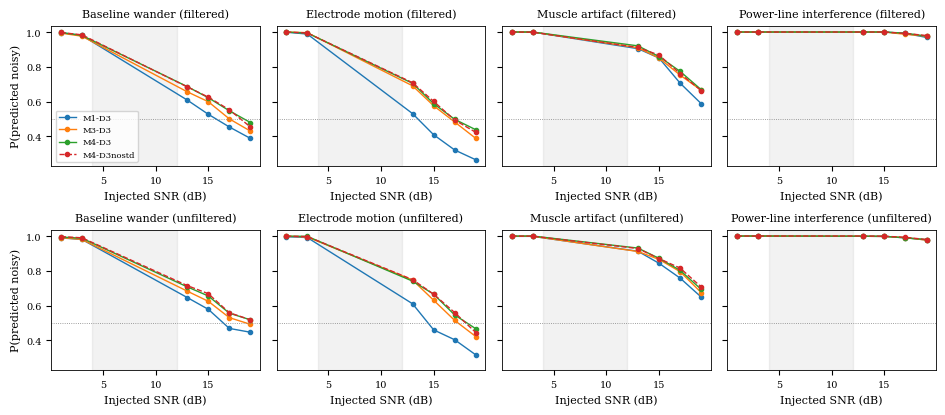

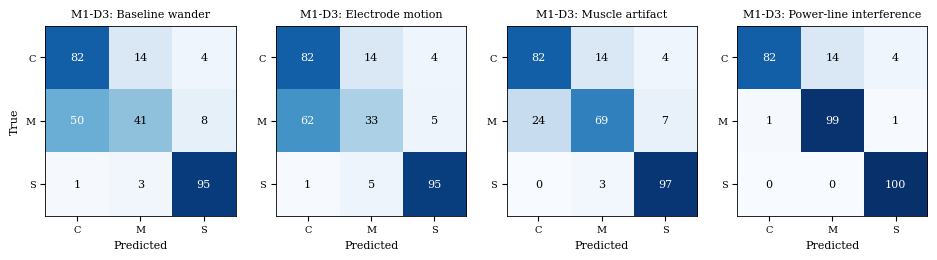

IndexError: index 3 is out of bounds for axis 1 with size 3

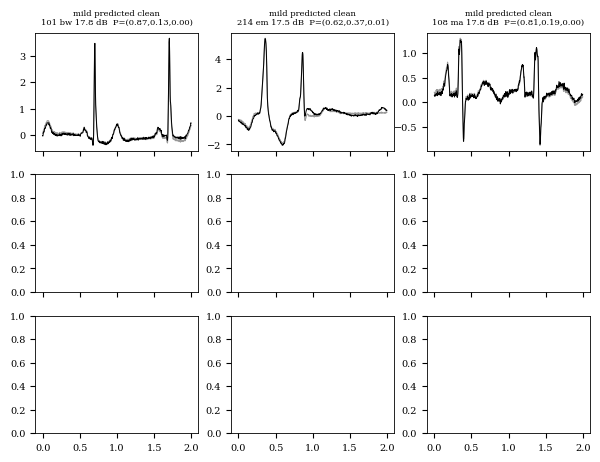

In [45]:
# Cell 24: detection curves, per-noise confusion and example misclassified mild windows
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
                     "legend.fontsize": 6, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.linewidth": 0.6,
                     "lines.linewidth": 1.0, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT["figures"] / f"{name}.{ext}")
    plt.show()


order_bins = ["[0.0, 2.0)", "[2.0, 4.0)", "[12.0, 14.0)", "[14.0, 16.0)", "[16.0, 18.0)", "[18.0, 20.01)"]
centers = [1, 3, 13, 15, 17, 19]
# v3.0: detection curves now have 4 columns (bw, em, ma, pli)
fig, axes = plt.subplots(2, 4, figsize=(9.5, 4.2), sharey=True)
for r_i, es in enumerate(("filtered", "unfiltered")):
    for ax, noise in zip(axes[r_i], NOISE_NAMES):
        for m in CAND + EXPLORATORY_MODELS:
            sub = detect[(detect.evalset == es) & (detect.model == m) & (detect.noise_type == noise)].set_index("snr_bin")
            ys = [sub["mean"].get(b, np.nan) for b in order_bins]
            ax.plot(centers, ys, marker="o", ms=3, ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
        ax.axhline(0.5, color="gray", lw=0.6, ls=":")
        ax.axvspan(4, 12, color="gray", alpha=0.1)
        ax.set_title(f"{NOISE_LABEL[noise]} ({es})")
        ax.set_xlabel("Injected SNR (dB)")
axes[0, 0].set_ylabel("P(predicted noisy)")
axes[1, 0].set_ylabel("P(predicted noisy)")
axes[0, 0].legend()
fig.tight_layout()
save_fig(fig, "fig1_detection_curves_v3")

# v3.0: NEW figure - detection by number of concurrent noise sources
if ENABLE_MULTI_NOISE and "n_noise_types" in ens_cv.columns:
    detect_by_count = (ens_cv[(ens_cv.label > 0) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
                       .assign(detected=lambda d: (d.pred != 0).astype(float))
                       .groupby(["evalset", "model", "n_noise_types"])[["detected"]].mean().reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.8), sharey=True)
    for ax, es in zip(axes, ("filtered", "unfiltered")):
        for m in CAND + EXPLORATORY_MODELS:
            sub = detect_by_count[(detect_by_count.evalset == es) & (detect_by_count.model == m)]
            ax.plot(sub["n_noise_types"], sub["detected"], marker="o", ms=4,
                    ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
        ax.set_title(f"Detection vs #noise sources ({es})")
        ax.set_xlabel("Number of concurrent noise sources")
        ax.set_xticks([1, 2, 3])
    axes[0].set_ylabel("P(predicted noisy)")
    axes[0].legend()
    fig.tight_layout()
    save_fig(fig, "fig1b_detection_by_noise_count_v3")

# v3.0: NEW figure - per-scenario macro-F1 bar chart
if ENABLE_MULTI_NOISE and "scenario" in ens_cv.columns:
    scen_metrics = (ens_cv[ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
                    .assign(correct=lambda d: (d.label == d.pred).astype(float))
                    .groupby(["evalset", "model", "scenario"])[["correct"]].mean().reset_index())
    scen_metrics = scen_metrics[scen_metrics.scenario != "none"]
    if len(scen_metrics):
        fig, ax = plt.subplots(1, 1, figsize=(7.16, 3.2))
        piv = scen_metrics[scen_metrics.evalset == "filtered"].pivot(index="scenario", columns="model", values="correct")
        piv.plot.bar(ax=ax, width=0.8)
        ax.set_ylabel("Accuracy")
        ax.set_title("Per-scenario accuracy (filtered, M4-D3 family)")
        ax.legend(loc="lower right", fontsize=6)
        ax.set_ylim(0, 1)
        fig.tight_layout()
        save_fig(fig, "fig1c_per_scenario_accuracy_v3")


# v3.0: confusion matrices now include PLI as 4th column
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.4))
sub = ens_cv[(ens_cv.evalset == "filtered") & (ens_cv.model == FROZEN_CHOICE)]
for ax, noise in zip(axes, NOISE_NAMES):
    s2 = sub[(sub.noise_type == noise) | (sub.label == 0)]
    cm = conf3(s2.label.values, s2.pred.values)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j] * 100:.0f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(["C", "M", "S"])
    ax.set_yticklabels(["C", "M", "S"])
    ax.set_title(f"{FROZEN_CHOICE}: {NOISE_LABEL[noise]}")
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("True")
fig.tight_layout()
save_fig(fig, "fig2_confusion_by_noise_v3")

ens_main = ensemble(main_pred[main_pred.model.isin(MODEL_SPECS)])
em = ens_main[(ens_main.evalset == "filtered") & (ens_main.model == FROZEN_CHOICE)].set_index("win")
rng_ex = np.random.default_rng(DATA_SEED)
rows_spec = [("mild predicted clean", (em.label == 1) & (em.pred == 0) & (em.snr_db >= 16)),
             ("mild predicted severe", (em.label == 1) & (em.pred == 2)),
             ("mild predicted mild", (em.label == 1) & (em.pred == 1) & (em.snr_db < 14))]
fig, axes = plt.subplots(3, 3, figsize=(7.16, 5.2), sharex=True)
for r_i, (title, mask) in enumerate(rows_spec):
    for c_i, noise in enumerate(NOISE_NAMES):
        ax = axes[r_i, c_i]
        cand = em.index[mask & (em.noise_type == noise)]
        if len(cand) == 0:
            ax.set_axis_off()
            continue
        i = int(rng_ex.choice(cand))
        row = em.loc[i]
        ax.plot(np.arange(WIN) / FS, main["ecg"]["test"][i], color="0.6", lw=0.8, label="clean base")
        ax.plot(np.arange(WIN) / FS, main["X"]["test"][i], color="k", lw=0.7, label="noisy window")
        ax.set_title(f"{title}\n{row.record} {noise} {row.snr_db:.1f} dB  P=({row.p0:.2f},{row.p1:.2f},{row.p2:.2f})", fontsize=6)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
axes[0, 0].legend()
fig.tight_layout()
save_fig(fig, "fig3_misclassified_mild_examples")

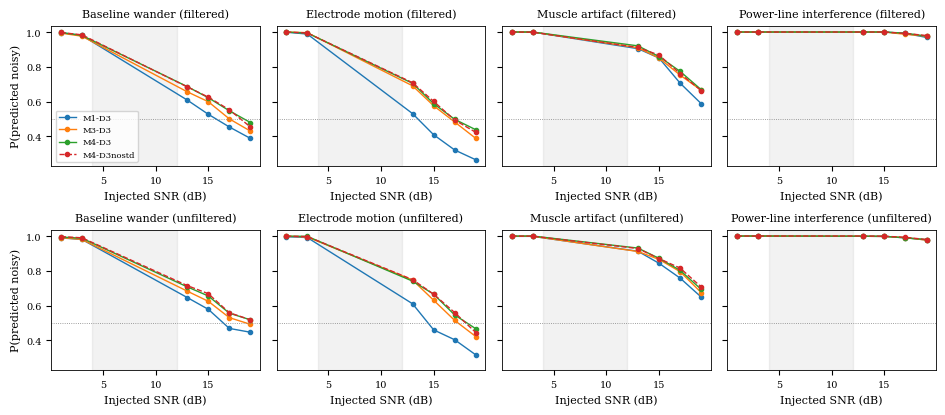

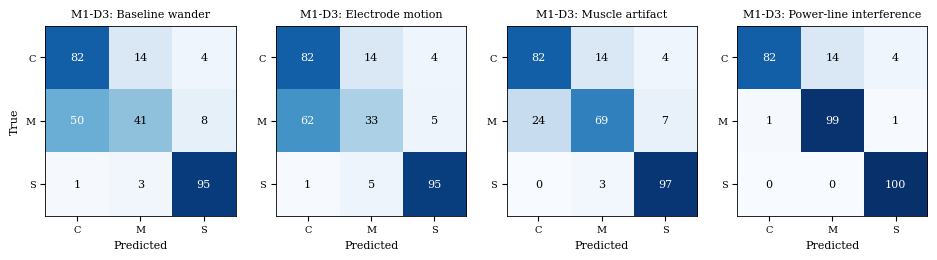

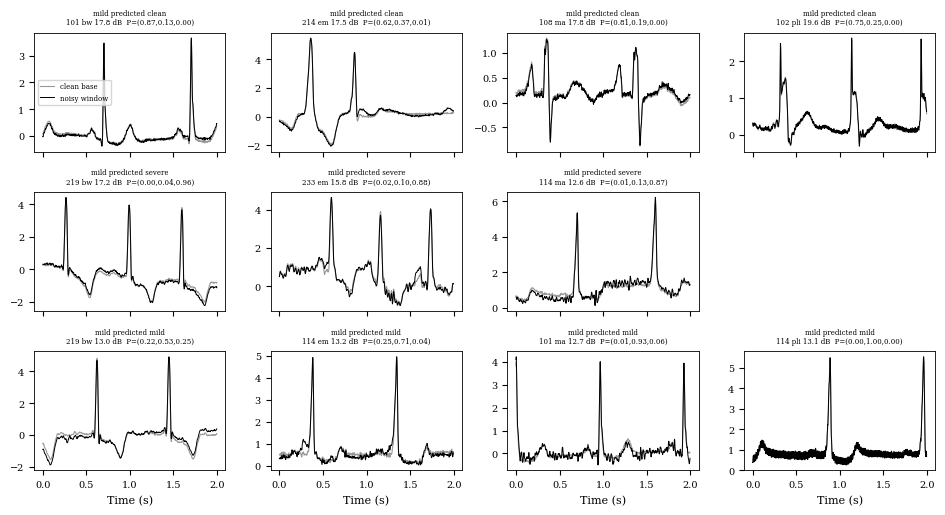

In [50]:
# Cell 24: detection curves, per-noise confusion and example misclassified mild windows
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
                     "legend.fontsize": 6, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.linewidth": 0.6,
                     "lines.linewidth": 1.0, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT["figures"] / f"{name}.{ext}")
    plt.show()


order_bins = ["[0.0, 2.0)", "[2.0, 4.0)", "[12.0, 14.0)", "[14.0, 16.0)", "[16.0, 18.0)", "[18.0, 20.01)"]
centers = [1, 3, 13, 15, 17, 19]
# v3.0: detection curves now have 4 columns (bw, em, ma, pli)
fig, axes = plt.subplots(2, 4, figsize=(9.5, 4.2), sharey=True)
for r_i, es in enumerate(("filtered", "unfiltered")):
    for ax, noise in zip(axes[r_i], NOISE_NAMES):
        for m in CAND + EXPLORATORY_MODELS:
            sub = detect[(detect.evalset == es) & (detect.model == m) & (detect.noise_type == noise)].set_index("snr_bin")
            ys = [sub["mean"].get(b, np.nan) for b in order_bins]
            ax.plot(centers, ys, marker="o", ms=3, ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
        ax.axhline(0.5, color="gray", lw=0.6, ls=":")
        ax.axvspan(4, 12, color="gray", alpha=0.1)
        ax.set_title(f"{NOISE_LABEL[noise]} ({es})")
        ax.set_xlabel("Injected SNR (dB)")
axes[0, 0].set_ylabel("P(predicted noisy)")
axes[1, 0].set_ylabel("P(predicted noisy)")
axes[0, 0].legend()
fig.tight_layout()
save_fig(fig, "fig1_detection_curves_v3")

# v3.0: NEW figure - detection by number of concurrent noise sources
if ENABLE_MULTI_NOISE and "n_noise_types" in ens_cv.columns:
    detect_by_count = (ens_cv[(ens_cv.label > 0) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
                       .assign(detected=lambda d: (d.pred != 0).astype(float))
                       .groupby(["evalset", "model", "n_noise_types"])[["detected"]].mean().reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.8), sharey=True)
    for ax, es in zip(axes, ("filtered", "unfiltered")):
        for m in CAND + EXPLORATORY_MODELS:
            sub = detect_by_count[(detect_by_count.evalset == es) & (detect_by_count.model == m)]
            ax.plot(sub["n_noise_types"], sub["detected"], marker="o", ms=4,
                    ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
        ax.set_title(f"Detection vs #noise sources ({es})")
        ax.set_xlabel("Number of concurrent noise sources")
        ax.set_xticks([1, 2, 3])
    axes[0].set_ylabel("P(predicted noisy)")
    axes[0].legend()
    fig.tight_layout()
    save_fig(fig, "fig1b_detection_by_noise_count_v3")

# v3.0: NEW figure - per-scenario macro-F1 bar chart
if ENABLE_MULTI_NOISE and "scenario" in ens_cv.columns:
    scen_metrics = (ens_cv[ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
                    .assign(correct=lambda d: (d.label == d.pred).astype(float))
                    .groupby(["evalset", "model", "scenario"])[["correct"]].mean().reset_index())
    scen_metrics = scen_metrics[scen_metrics.scenario != "none"]
    if len(scen_metrics):
        fig, ax = plt.subplots(1, 1, figsize=(7.16, 3.2))
        piv = scen_metrics[scen_metrics.evalset == "filtered"].pivot(index="scenario", columns="model", values="correct")
        piv.plot.bar(ax=ax, width=0.8)
        ax.set_ylabel("Accuracy")
        ax.set_title("Per-scenario accuracy (filtered, M4-D3 family)")
        ax.legend(loc="lower right", fontsize=6)
        ax.set_ylim(0, 1)
        fig.tight_layout()
        save_fig(fig, "fig1c_per_scenario_accuracy_v3")


# v3.0: confusion matrices now include PLI as 4th column
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.4))
sub = ens_cv[(ens_cv.evalset == "filtered") & (ens_cv.model == FROZEN_CHOICE)]
for ax, noise in zip(axes, NOISE_NAMES):
    s2 = sub[(sub.noise_type == noise) | (sub.label == 0)]
    cm = conf3(s2.label.values, s2.pred.values)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j] * 100:.0f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(["C", "M", "S"])
    ax.set_yticklabels(["C", "M", "S"])
    ax.set_title(f"{FROZEN_CHOICE}: {NOISE_LABEL[noise]}")
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("True")
fig.tight_layout()
save_fig(fig, "fig2_confusion_by_noise_v3")

ens_main = ensemble(main_pred[main_pred.model.isin(MODEL_SPECS)])
em = ens_main[(ens_main.evalset == "filtered") & (ens_main.model == FROZEN_CHOICE)].set_index("win")
rng_ex = np.random.default_rng(DATA_SEED)
rows_spec = [("mild predicted clean", (em.label == 1) & (em.pred == 0) & (em.snr_db >= 16)),
             ("mild predicted severe", (em.label == 1) & (em.pred == 2)),
             ("mild predicted mild", (em.label == 1) & (em.pred == 1) & (em.snr_db < 14))]
# Updated to 4 columns to match len(NOISE_NAMES) = 4 (bw, em, ma, pli)
fig, axes = plt.subplots(3, 4, figsize=(9.5, 5.2), sharex=True)
for r_i, (title, mask) in enumerate(rows_spec):
    for c_i, noise in enumerate(NOISE_NAMES):
        ax = axes[r_i, c_i]
        cand = em.index[mask & (em.noise_type == noise)]
        if len(cand) == 0:
            ax.set_axis_off()
            continue
        i = int(rng_ex.choice(cand))
        row = em.loc[i]
        ax.plot(np.arange(WIN) / FS, main["ecg"]["test"][i], color="0.6", lw=0.8, label="clean base")
        ax.plot(np.arange(WIN) / FS, main["X"]["test"][i], color="k", lw=0.7, label="noisy window")
        ax.set_title(f"{title}\n{row.record} {noise} {row.snr_db:.1f} dB  P=({row.p0:.2f},{row.p1:.2f},{row.p2:.2f})", fontsize=5)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
axes[0, 0].legend(fontsize=5)
fig.tight_layout()
save_fig(fig, "fig3_misclassified_mild_examples")

## Stage 9: Figures, tables and findings

**Why.** Figures, tables and the findings text are generated from stored results so they cannot drift from the numbers, and the findings text states the frozen selection and uses the word "supported" only where the corrected patient-level statistics support it.

**How.** Cell 25 writes the remaining figures. Cell 26 writes CSV and LaTeX tables. Cell 27 generates the findings.

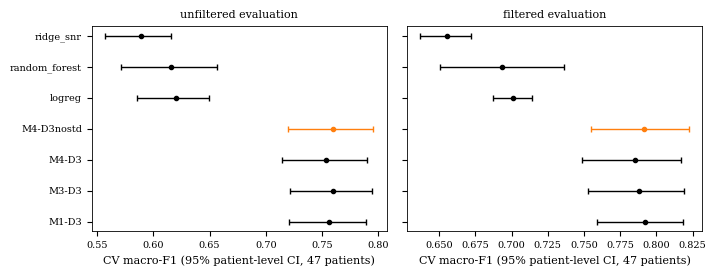

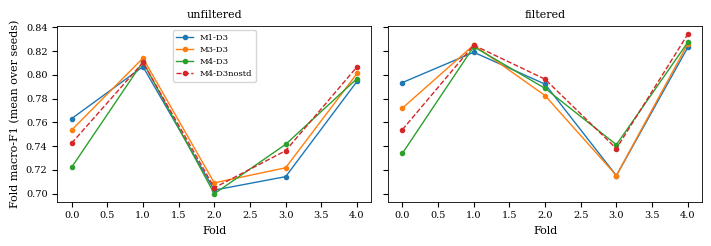

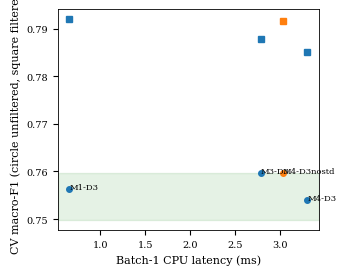

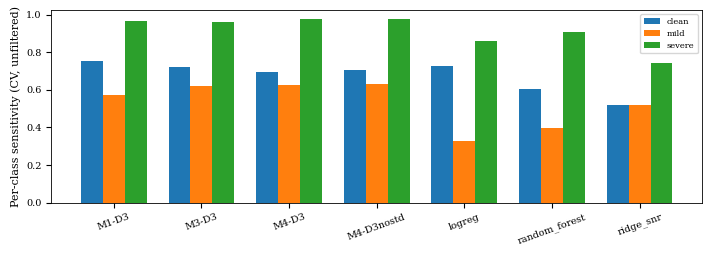

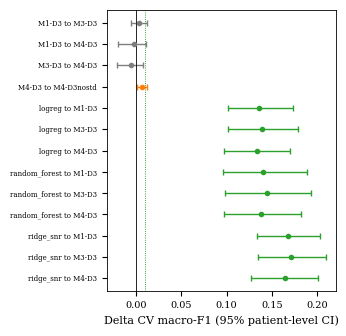

In [51]:
# Cell 25: cross-validation evidence figures
VMARK = {"M1": "o", "M3": "^", "M4": "D"}
fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.8), sharey=True)
keys = CV_MODELS + BASELINE_NAMES
for ax, es in zip(axes, ("unfiltered", "filtered")):
    for i, k in enumerate(keys):
        p, (lo, hi) = point_cv[es][k], ci_cv[es][k]
        ax.errorbar(p, i, xerr=[[p - lo], [hi - p]], fmt="o", color="tab:orange" if k in EXPLORATORY_MODELS else "k", capsize=2, ms=3)
    ax.set_yticks(range(len(keys)))
    ax.set_yticklabels(keys)
    ax.invert_yaxis()
    ax.set_title(f"{es} evaluation")
    ax.set_xlabel("CV macro-F1 (95% patient-level CI, 47 patients)")
fig.tight_layout()
save_fig(fig, "fig4_cv_patient_ci")

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.5), sharey=True)
for ax, es in zip(axes, ("unfiltered", "filtered")):
    piv = fold_df[fold_df.evalset == es].pivot(index="fold", columns="model", values="macro_f1")
    for m in CV_MODELS:
        ax.plot(piv.index, piv[m], marker="o", ms=3, ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
    ax.set_xlabel("Fold")
    ax.set_title(es)
axes[0].set_ylabel("Fold macro-F1 (mean over seeds)")
axes[0].legend()
fig.tight_layout()
save_fig(fig, "fig5_cv_fold_paired")

fig, ax = plt.subplots(figsize=(3.5, 2.8))
for m in CV_MODELS:
    xs = efficiency_df.loc[m, "cpu_latency_ms_median"]
    for es, mk in (("unfiltered", "o"), ("filtered", "s")):
        ax.plot(xs, point_cv[es][m], mk, color="tab:orange" if m in EXPLORATORY_MODELS else "tab:blue", ms=4)
    ax.annotate(m, (xs, point_cv["unfiltered"][m]), fontsize=6)
best_f = max(point_cv["unfiltered"][m] for m in FROZEN_CANDIDATES)
ax.axhspan(best_f - NONINFERIORITY_MARGIN, best_f, color="green", alpha=0.1)
ax.set_xlabel("Batch-1 CPU latency (ms)")
ax.set_ylabel("CV macro-F1 (circle unfiltered, square filtered)")
fig.tight_layout()
save_fig(fig, "fig6_accuracy_latency")

fig, ax = plt.subplots(figsize=(7.16, 2.6))
names = CV_MODELS + BASELINE_NAMES
cvs = cv_runs[cv_runs.evalset == "unfiltered"].groupby("model")[["sens_clean", "sens_mild", "sens_severe"]].mean()
for j, c in enumerate(CLASS_NAMES):
    ax.bar(np.arange(len(names)) + (j - 1) * 0.25, [cvs.loc[n, f"sens_{c}"] for n in names], 0.25, label=c)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20)
ax.set_ylabel("Per-class sensitivity (CV, unfiltered)")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig7_per_class_sensitivity")

pt = pair_cv["unfiltered"].iloc[::-1].reset_index(drop=True)
colors = {"supported": "tab:green", "suggestive (unadjusted)": "tab:orange", "not supported": "tab:gray"}
fig, ax = plt.subplots(figsize=(3.5, 0.2 * len(pt) + 0.8))
for i, r in pt.iterrows():
    ax.errorbar(r.delta, i, xerr=[[r.delta - r.ci_lo], [r.ci_hi - r.delta]], fmt="o", color=colors[r.verdict], capsize=2, ms=3)
ax.axvline(0, color="k", lw=0.6)
ax.axvline(NONINFERIORITY_MARGIN, color="green", lw=0.6, ls=":")
ax.set_yticks(range(len(pt)))
ax.set_yticklabels(pt.comparison, fontsize=5)
ax.set_xlabel("Delta CV macro-F1 (95% patient-level CI)")
fig.tight_layout()
save_fig(fig, "fig8_pairwise_effects")


# ---- v3.0 addition: scenario vs noise-type error heatmap ----------------- #
if ENABLE_MULTI_NOISE and "scenario" in ens_cv.columns and "n_noise_types" in ens_cv.columns:
    # For each scenario, compute per-model accuracy on filtered test set
    scen_model_acc = (ens_cv[(ens_cv.evalset == "filtered") & ens_cv.model.isin(CAND)]
                     .assign(correct=lambda d: (d.label == d.pred).astype(float))
                     .groupby(["scenario", "model"])[["correct"]].mean().reset_index())
    if len(scen_model_acc):
        fig, ax = plt.subplots(1, 1, figsize=(7.16, 3.0))
        piv = scen_model_acc.pivot(index="scenario", columns="model", values="correct")
        piv = piv.reindex(columns=CAND)
        im = ax.imshow(piv.values, cmap="RdYlGn", vmin=0.4, vmax=1.0, aspect="auto")
        ax.set_xticks(range(len(piv.columns)))
        ax.set_xticklabels(piv.columns, rotation=0)
        ax.set_yticks(range(len(piv.index)))
        ax.set_yticklabels(piv.index, fontsize=7)
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center",
                        color="white" if piv.values[i, j] < 0.7 else "black", fontsize=6)
        plt.colorbar(im, ax=ax, label="Accuracy")
        ax.set_title("v3.0: scenario x model accuracy (filtered)")
        fig.tight_layout()
        save_fig(fig, "fig_v3_scenario_model_heatmap")


In [53]:
# Cell 26: tables
def pm(mean, std):
    return f"{mean:.3f}" if pd.isna(std) else f"{mean:.3f} ± {std:.3f}"


def save_table(df, name, caption, label):
    df.to_csv(OUT["tables"] / f"{name}.csv", index=False)
    tex = df.to_latex(index=False, float_format="%.3f", caption=caption, label=label, escape=True)
    (OUT["tables"] / f"{name}.tex").write_text(tex.replace("±", r"$\pm$"))
    display(df)


t_part = pd.DataFrame([dict(Partition=s, Patients=meta[s].patient.nunique(), Records=meta[s].record.nunique(),
                            Windows_before_filter=info["windows_before"][s], Windows=len(meta[s])) for s in SPLITS]
                      + [dict(Partition="test (unfiltered)", Patients=meta_unf.patient.nunique(), Records=meta_unf.record.nunique(),
                              Windows_before_filter=len(meta_unf), Windows=len(meta_unf))])
rows = []
for es in ("unfiltered", "filtered"):
    sub = fold_df[fold_df.evalset == es]
    for m in CV_MODELS + BASELINE_NAMES:
        g = sub[sub.model == m]
        lo, hi = ci_cv[es][m]
        rows.append({"Evaluation": es, "Model": m + (" (exploratory)" if m in EXPLORATORY_MODELS else ""),
                     "Macro-F1 (SD over folds)": pm(g.macro_f1.mean(), g.macro_f1.std()),
                     "95% patient CI": f"[{lo:.3f}, {hi:.3f}]", "QWK": round(g.qwk.mean(), 3),
                     "Sens. clean": round(g.sens_clean.mean(), 3), "Sens. mild": round(g.sens_mild.mean(), 3),
                     "Sens. severe": round(g.sens_severe.mean(), 3),
                     "SNR MAE (dB)": np.nan if g.snr_mae.isna().all() else round(g.snr_mae.mean(), 2),
                     "Parameters": int(efficiency_df.loc[m, "parameters"]),
                     "CPU latency (ms)": round(efficiency_df.loc[m, "cpu_latency_ms_median"], 3)})
t_cv = pd.DataFrame(rows)
t_pairs = pd.concat([pair_cv[es].assign(Evaluation=es) for es in pair_cv]).drop(columns=["a", "b"]).rename(columns={
    "comparison": "Comparison", "delta": "Delta macro-F1", "ci_lo": "CI low", "ci_hi": "CI high",
    "p_patient_boot": "p (patient bootstrap)", "p_holm": "p (Holm)", "verdict": "Verdict", "fold_p": "p (paired folds)",
    "folds_won": "Folds won", "a_noninferior_to_b": "Cheaper model non-inferior"})
t_main = main_runs_df.groupby(["evalset", "model"])[["macro_f1", "accuracy", "qwk", "sens_clean", "sens_mild", "sens_severe", "snr_mae"]].agg(["mean", "std"])
t_main.columns = [f"{a}_{b}" for a, b in t_main.columns]
t_main = t_main.reset_index()
t_eff = efficiency_df.reset_index().rename(columns={"index": "Model"})
t_sel = pd.DataFrame([dict(Endpoint=es, Best=rule[es]["best"], Chosen=rule[es]["choice"], **{f"Mean {m}": round(v, 4) for m, v in rule[es]["means"].items()})
                      for es in rule] + [dict(Endpoint="FROZEN CHOICE", Best="", Chosen=FROZEN_CHOICE)])
t_mild = mild_err.copy()

save_table(t_part, "table1_partitions", "Dataset partitions (patient-disjoint), filtered and unfiltered test windows.", "tab:partitions")
save_table(t_cv, "table2_cross_validation", "Grouped patient cross-validation (primary evidence): macro-F1 by evaluation set.", "tab:cv")
save_table(t_pairs, "table3_cv_pairwise", "Pairwise comparisons: patient-level bootstrap, Holm correction, paired folds.", "tab:cvpairs")
save_table(t_sel, "table4_frozen_selection", "Frozen selection rule outcome.", "tab:selection")
save_table(t_main, "table5_main_split_supplementary", "Held-out 7-patient split (supplementary).", "tab:main")
save_table(t_eff, "table6_efficiency", f"Computational cost (single-thread CPU: {HARDWARE}).", "tab:efficiency")
save_table(t_mild, "table7_mild_errors", "Mild-window outcomes by noise type and SNR bin (CV pooled, seed-ensembled).", "tab:mild")
save_table(per_patient, "table8_per_patient_mild_sensitivity", "Per-patient mild sensitivity (CV pooled, seed-ensembled).", "tab:patient")


# ---- v3.0 addition: per-scenario macro-F1 table --------------------------- #
if ENABLE_MULTI_NOISE and "scenario" in ens_cv.columns:
    scen_f1 = (ens_cv[ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
               .assign(correct=lambda d: (d.label == d.pred).astype(float))
               .groupby(["evalset", "model", "scenario"])[["correct"]].agg(["mean", "count"])
               .reset_index())
    scen_f1.columns = ["evalset", "model", "scenario", "accuracy", "n"]
    scen_f1 = scen_f1[scen_f1.scenario != "none"]
    scen_f1.to_csv(OUT["tables"] / "v3_per_scenario_accuracy.csv.gz", index=False, compression="gzip")
    print("\n--- v3.0: per-scenario accuracy (filtered) ---")
    display(scen_f1[scen_f1.evalset == "filtered"].pivot(index="scenario", columns="model", values="accuracy").round(3))

# ---- v3.0 addition: noise-type-count table -------------------------------- #
if ENABLE_MULTI_NOISE and "n_noise_types" in ens_cv.columns:
    count_f1 = (ens_cv[ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
                .assign(correct=lambda d: (d.label == d.pred).astype(float))
                .groupby(["evalset", "model", "n_noise_types"])[["correct"]].agg(["mean", "count"])
                .reset_index())
    count_f1.columns = ["evalset", "model", "n_noise_types", "accuracy", "n"]
    count_f1.to_csv(OUT["tables"] / "v3_by_noise_count.csv.gz", index=False, compression="gzip")
    print("\n--- v3.0: accuracy by number of concurrent noise sources (filtered) ---")
    display(count_f1[count_f1.evalset == "filtered"].pivot(index="n_noise_types", columns="model", values="accuracy").round(3))


,Partition,Patients,Records,Windows_before_filter,Windows
0,train,33,34,30668,21467
1,val,7,7,6314,3033
2,test,7,7,6314,4758
3,test (unfiltered),7,7,6314,6314


,Evaluation,Model,Macro-F1 (SD over folds),95% patient CI,QWK,Sens. clean,Sens. mild,Sens. severe,SNR MAE (dB),Parameters,CPU latency (ms)
0,unfiltered,M1-D3,0.756 ± 0.047,"[0.721, 0.789]",0.756,0.754,0.575,0.965,4.18,5812,0.657
1,unfiltered,M3-D3,0.760 ± 0.047,"[0.722, 0.795]",0.753,0.724,0.619,0.965,4.04,4372,2.789
2,unfiltered,M4-D3,0.754 ± 0.048,"[0.714, 0.790]",0.745,0.696,0.626,0.976,3.67,4816,3.306
3,unfiltered,M4-D3nostd (exploratory),0.760 ± 0.046,"[0.720, 0.796]",0.751,0.705,0.632,0.977,3.42,4752,3.033
4,unfiltered,logreg,0.622 ± 0.066,"[0.586, 0.650]",0.582,0.729,0.330,0.862,NaN,48,2.955
5,unfiltered,random_forest,0.617 ± 0.063,"[0.571, 0.657]",0.532,0.607,0.399,0.908,NaN,922190,13.645
6,unfiltered,ridge_snr,0.588 ± 0.056,"[0.557, 0.616]",0.574,0.519,0.520,0.743,NaN,16,2.939
7,filtered,M1-D3,0.789 ± 0.043,"[0.759, 0.818]",0.817,0.808,0.601,0.965,4.13,5812,0.657
8,filtered,M3-D3,0.784 ± 0.046,"[0.753, 0.819]",0.806,0.760,0.643,0.963,4.03,4372,2.789
9,filtered,M4-D3,0.783 ± 0.044,"[0.748, 0.817]",0.802,0.731,0.663,0.974,3.59,4816,3.306


,Comparison,Delta macro-F1,CI low,CI high,p (patient bootstrap),Cheaper model non-inferior,fold_mean_delta,fold_ci_lo,fold_ci_hi,p (paired folds),Folds won,p (Holm),Verdict,Evaluation
0,M1-D3 to M3-D3,0.003437,-0.005626,0.011359,0.403,False,0.003577,-0.005596,0.012749,0.339895,4,1.000,not supported,unfiltered
1,M1-D3 to M4-D3,-0.002404,-0.020415,0.010800,0.806,False,-0.002071,-0.032679,0.028537,0.860130,3,1.000,not supported,unfiltered
2,M3-D3 to M4-D3,-0.005841,-0.021113,0.007079,0.378,True,-0.005648,-0.028259,0.016963,0.526176,1,1.000,not supported,unfiltered
3,M4-D3 to M4-D3nostd,0.005841,0.000221,0.011291,0.038,False,0.005847,-0.006462,0.018155,0.257659,3,0.152,suggestive (unadjusted),unfiltered
4,logreg to M1-D3,0.136181,0.101031,0.173726,0.000,False,0.134458,0.076719,0.192198,0.002948,5,0.000,supported,unfiltered
5,logreg to M3-D3,0.139618,0.101863,0.179506,0.000,False,0.138035,0.082943,0.193127,0.002244,5,0.000,supported,unfiltered
6,logreg to M4-D3,0.133776,0.096757,0.170304,0.000,False,0.132387,0.089574,0.175201,0.001011,5,0.000,supported,unfiltered
7,random_forest to M1-D3,0.140762,0.096358,0.189177,0.000,False,0.139482,0.071774,0.207190,0.004624,5,0.000,supported,unfiltered
8,random_forest to M3-D3,0.144199,0.098022,0.193799,0.000,False,0.143058,0.081549,0.204568,0.002961,5,0.000,supported,unfiltered
9,random_forest to M4-D3,0.138358,0.097288,0.182551,0.000,False,0.137411,0.097053,0.177769,0.000698,5,0.000,supported,unfiltered


,Endpoint,Best,Chosen,Mean M1-D3,Mean M3-D3,Mean M4-D3
0,unfiltered,M3-D3,M1-D3,0.7565,0.7600,0.7544
1,filtered,M1-D3,M1-D3,0.7887,0.7843,0.7831
2,FROZEN CHOICE,,M1-D3,NaN,NaN,NaN


,evalset,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,qwk_mean,qwk_std,sens_clean_mean,sens_clean_std,sens_mild_mean,sens_mild_std,sens_severe_mean,sens_severe_std,snr_mae_mean,snr_mae_std
0,filtered,M1-D3,0.809197,0.007745,0.825011,0.006206,0.873920,0.005653,0.935935,0.006004,0.525685,0.021162,0.962672,0.010135,4.593947,0.178167
1,filtered,M3-D3,0.816238,0.004365,0.827238,0.003222,0.872734,0.003805,0.895935,0.007312,0.583117,0.017990,0.965815,0.006373,4.212831,0.091599
2,filtered,M4-D3,0.832446,0.016614,0.837243,0.017983,0.879739,0.014847,0.844336,0.057627,0.674892,0.023818,0.976031,0.008432,3.323920,0.180658
3,filtered,M4-D3nostd,0.832910,0.009629,0.837397,0.008853,0.880587,0.006428,0.845167,0.036850,0.677249,0.039842,0.973368,0.012117,3.295524,0.388770
4,filtered,logreg,0.717774,NaN,0.738966,NaN,0.755230,NaN,0.899187,NaN,0.408369,NaN,0.845449,NaN,NaN,NaN
5,filtered,random_forest,0.726928,NaN,0.735393,NaN,0.749523,NaN,0.806504,NaN,0.495671,NaN,0.867060,NaN,NaN,NaN
6,filtered,ridge_snr,0.634482,NaN,0.619798,NaN,0.681853,NaN,0.462331,NaN,0.686147,NaN,0.749836,NaN,NaN,NaN
7,unfiltered,M1-D3,0.757384,0.005062,0.768863,0.004424,0.776452,0.004834,0.841138,0.010860,0.501172,0.015753,0.952723,0.009891,4.763232,0.161773
8,unfiltered,M3-D3,0.768317,0.002088,0.775356,0.001980,0.779242,0.002993,0.808618,0.016085,0.559755,0.020612,0.955896,0.004574,4.372266,0.073433
9,unfiltered,M4-D3,0.788123,0.011839,0.791384,0.013026,0.795029,0.013624,0.784634,0.050832,0.630871,0.029411,0.966790,0.008110,3.558060,0.178055


,Model,parameters,size_mb,macs_m,flops_m,peak_activation_mb,cpu_latency_ms_median,cpu_latency_ms_p95,throughput_b1,throughput_batch
0,M1-D3,5812,0.033731,2.338688,4.677376,0.04608,0.657376,0.793655,1521.199435,7260.122710
1,M3-D3,4372,0.049798,1.552448,3.104896,0.04608,2.789009,3.128573,358.550359,1528.660893
2,M4-D3,4816,0.056041,1.552832,3.105664,0.04608,3.305730,4.107339,302.504999,1476.000208
3,M4-D3nostd,4752,0.055785,1.552768,3.105536,0.04608,3.032869,3.389679,329.720748,1526.085954
4,logreg,48,0.001854,NaN,NaN,NaN,2.955202,3.283874,338.386287,13338.153130
5,random_forest,922190,81.220675,NaN,NaN,NaN,13.645100,14.634790,73.286384,3838.746150
6,ridge_snr,16,0.001298,NaN,NaN,NaN,2.938951,3.210091,340.257517,14878.999443


,evalset,model,noise_type,mild_bin,correct,to_clean,to_severe,n
0,filtered,M1-D3,bw,12-16,0.456388,0.431718,0.111894,1135
1,filtered,M1-D3,bw,16-20,0.364977,0.578802,0.056221,1085
2,filtered,M1-D3,em,12-16,0.409938,0.529725,0.060337,1127
3,filtered,M1-D3,em,16-20,0.251327,0.707965,0.040708,1130
4,filtered,M1-D3,ma,12-16,0.782609,0.123478,0.093913,1150
...,...,...,...,...,...,...,...,...
59,unfiltered,M4-D3nostd,em,16-20,0.380621,0.496517,0.122863,1579
60,unfiltered,M4-D3nostd,ma,12-16,0.729061,0.101523,0.169416,1576
61,unfiltered,M4-D3nostd,ma,16-20,0.625912,0.240876,0.133212,1644
62,unfiltered,M4-D3nostd,pli,12-16,0.951158,0.000626,0.048215,1597


,evalset,model,patient,n_mild,mild_sensitivity,mean_qc_index
0,filtered,M1-D3,100,258,0.445736,0.054349
1,filtered,M1-D3,101,245,0.400000,0.050546
2,filtered,M1-D3,102,228,0.473684,0.070491
3,filtered,M1-D3,103,274,0.470803,0.022507
4,filtered,M1-D3,104,74,0.472973,0.108006
...,...,...,...,...,...,...
371,unfiltered,M4-D3nostd,230,262,0.664122,0.073313
372,unfiltered,M4-D3nostd,231,274,0.554745,0.169752
373,unfiltered,M4-D3nostd,232,283,0.802120,0.109535
374,unfiltered,M4-D3nostd,233,248,0.713710,0.063094


In [54]:
# Cell 27: findings generated from the computed statistics
sel = json.loads(SELECTION_PATH.read_text())
lines = [f"Experiment Protocol {PROTOCOL}; frozen candidates {FROZEN_CANDIDATES}; exploratory {EXPLORATORY_MODELS}.",
         "Scope: single-lead ECG signal-quality assessment of injected-noise level (clean/mild/severe) with an auxiliary SNR output; "
         "not an arrhythmia classifier or a denoiser; labels are not independently validated absolute quality.",
         f"Frozen selection (applied to cross-validation before the held-out split was evaluated): {sel['frozen_choice']} ({sel['note']}).",
         f"Rule: {sel['rule']}, margin {sel['margin']}."]
for es in ("unfiltered", "filtered"):
    lines.append(f"Cross-validation, {es} evaluation (macro-F1 mean over folds [95% patient CI over 47 patients]):")
    for m in CV_MODELS + BASELINE_NAMES:
        g = fold_df[(fold_df.evalset == es) & (fold_df.model == m)]
        lo, hi = ci_cv[es][m]
        tagx = " (exploratory)" if m in EXPLORATORY_MODELS else ""
        lines.append(f"- {m}{tagx}: {g.macro_f1.mean():.3f} (SD over folds {g.macro_f1.std():.3f}) [{lo:.3f}, {hi:.3f}], "
                     f"sens {g.sens_clean.mean():.2f}/{g.sens_mild.mean():.2f}/{g.sens_severe.mean():.2f}.")
fu = fold_df[fold_df.evalset == "filtered"].groupby("model").macro_f1.mean()
uu = fold_df[fold_df.evalset == "unfiltered"].groupby("model").macro_f1.mean()
lines.append("Unfiltered minus filtered macro-F1: " + ", ".join(f"{m} {uu[m] - fu[m]:+.3f}" for m in CV_MODELS + BASELINE_NAMES) + ".")
for es in ("unfiltered", "filtered"):
    lines.append(f"Pairwise comparisons, {es} (Holm-adjusted patient-level bootstrap):")
    for r in pair_cv[es].itertuples():
        extra = f", folds won {int(r.folds_won)}/{CV_FOLDS}, fold p {r.fold_p:.3f}" if hasattr(r, "folds_won") and not pd.isna(r.folds_won) else ""
        ni = "; cheaper model non-inferior within the margin" if r.a_noninferior_to_b and r.a in FROZEN_CANDIDATES and r.b in FROZEN_CANDIDATES else ""
        direction = "" if r.verdict == "not supported" else (" (second model better)" if r.delta > 0 else " (second model worse)")
        lines.append(f"- {r.comparison}: delta {r.delta:+.4f}, CI [{r.ci_lo:+.4f}, {r.ci_hi:+.4f}], Holm p {r.p_holm:.3f}{extra}: {r.verdict}{direction}{ni}.")
lines.append("Held-out 7-patient split (supplementary, not independent: it was used in v2.0 and v2.1):")
for es in ("unfiltered", "filtered"):
    for m in CV_MODELS:
        g = main_runs_df[(main_runs_df.evalset == es) & (main_runs_df.model == m)]
        lo, hi = ci_main[es][m]
        lines.append(f"- {m}, {es}: {g.macro_f1.mean():.3f} (SD over seeds {g.macro_f1.std():.3f}) [{lo:.3f}, {hi:.3f}].")
mdet = mild_err[(mild_err.evalset == "filtered") & (mild_err.model == FROZEN_CHOICE)]
hard = mdet.sort_values("to_clean", ascending=False).head(1).iloc[0]
lines.append(f"Mild-noise errors ({FROZEN_CHOICE}, filtered CV): the most frequent failure is mild predicted clean for {NOISE_LABEL[hard.noise_type]} at {hard.mild_bin} dB "
             f"({hard.to_clean:.2f} of {int(hard.n)} windows).")
fa = false_alarm[(false_alarm.evalset == "unfiltered") & (false_alarm.model == FROZEN_CHOICE)].set_index("qc_pass")["mean"]
if {True, False} <= set(fa.index):
    lines.append(f"Clean-window false-alarm rate for {FROZEN_CHOICE}: {fa[True]:.3f} when the base window passes the quality filter, {fa[False]:.3f} when it fails.")
low = per_patient[(per_patient.evalset == "filtered") & (per_patient.model == FROZEN_CHOICE)].mild_sensitivity
lines.append(f"Per-patient mild sensitivity ({FROZEN_CHOICE}): median {low.median():.2f}, range {low.min():.2f}-{low.max():.2f} across {len(low)} patients.")
lines += [
    "Limitations:",
    "- The model estimates the level of injected noise on MIT-BIH windows; MIT-BIH windows are not noise-free, the clean class is defined by the absence of injection, and the 30 dB clean SNR target is a modeling convention.",
    "- SNR is window-referenced (injected noise relative to total window power), not true signal-to-noise.",
    "- Training uses filtered windows only; the unfiltered evaluation tests robustness to windows the filter would have removed but is not a substitute for external validation on naturally corrupted, expert-labeled recordings.",
    "- Noise comes from three NSTDB source recordings, split by time; this is a controlled robustness test, not evidence of generalization to unseen recording environments.",
    "- The 7-patient held-out split was reused across v2.0 and v2.1 and is supplementary only; cross-validation uses 1 split per patient with 3 seeds per fold.",
    "- Many comparisons were run; Holm correction is applied to the patient-level bootstrap p-values, but the analysis remains exploratory until confirmed on an independent test.",
    "- Hyperparameters were fixed across architectures and not tuned per model.",
    "- Multi-scale convolution and squeeze-and-excitation are established techniques; any novelty claim must rest on the demonstrated design and experiment after checking related literature.",
    f"- Latency is measured on the notebook CPU ({HARDWARE}), not on a wearable or edge device.",
]
summary = "\n".join(lines)
(OUT["metrics"] / "findings.txt").write_text(summary)
print(summary)

Experiment Protocol v3.0; frozen candidates ['M1-D3', 'M3-D3', 'M4-D3']; exploratory ['M4-D3nostd'].
Scope: single-lead ECG signal-quality assessment of injected-noise level (clean/mild/severe) with an auxiliary SNR output; not an arrhythmia classifier or a denoiser; labels are not independently validated absolute quality.
Frozen selection (applied to cross-validation before the held-out split was evaluated): M1-D3 (primary (unfiltered) and secondary (filtered) endpoints agree).
Rule: cheapest candidate within the margin of the best cross-validated macro-F1, margin 0.01.
Cross-validation, unfiltered evaluation (macro-F1 mean over folds [95% patient CI over 47 patients]):
- M1-D3: 0.756 (SD over folds 0.047) [0.721, 0.789], sens 0.75/0.57/0.97.
- M3-D3: 0.760 (SD over folds 0.047) [0.722, 0.795], sens 0.72/0.62/0.96.
- M4-D3: 0.754 (SD over folds 0.048) [0.714, 0.790], sens 0.70/0.63/0.98.
- M4-D3nostd (exploratory): 0.760 (SD over folds 0.046) [0.720, 0.796], sens 0.70/0.63/0.98.
- log

## Stage 10: Export, provenance and final checks

**Why.** Every reported number must be reproducible from the exact checkpoint and dataset manifest that produced it. That requires recording the checkpoint hash, where it came from, the manifest hash of the dataset bundle it was evaluated on, and the configuration hash, and confirming that the preserved v2.1 outputs were not modified.

**How.** Cell 28 writes the provenance table, configuration, environment and a reproduction guide. Cell 29 verifies hashes, one-time test use, prediction coverage and the integrity of the preserved v2.1 copy, then checksums and archives the outputs.

In [55]:
# Cell 28: provenance, configuration and reproduction guide (v3.0)
prov = pd.DataFrame([dict(tag=t, model=m, seed=s, checkpoint=str(r["ckpt"].relative_to(OUT_ROOT)), checkpoint_sha256=sha256_file(r["ckpt"]),
                          source=r["source"], val_macro_f1_recorded=r["val_f1_at_best"], val_macro_f1_recomputed=r["val_f1_recomputed"],
                          best_epoch=r["best_epoch"], dataset_manifest_hash=r["manifest_hash"], config_hash=CONFIG_HASH)
                     for (t, m, s), r in sorted(registry.items())])
prov.to_csv(OUT["metrics"] / "provenance.csv", index=False)

run_summary = pd.DataFrame([dict(tag=t, model=m, seed=s, source=r["source"].split(":")[0], best_epoch=r["best_epoch"],
                                 epochs_run=r["epochs_run"], collapsed_epochs=r["collapsed_epochs"], val_smoothed=r["val_smoothed"])
                            for (t, m, s), r in sorted(registry.items())])
run_summary.to_csv(OUT["metrics"] / "run_summary.csv", index=False)
histories = [r["history"].assign(tag=t, model=m, seed=s) for (t, m, s), r in registry.items() if r["history"] is not None]
if histories:
    pd.concat(histories).to_csv(OUT["metrics"] / "training_histories_v22.csv", index=False)

cv_runs.to_csv(OUT["metrics"] / "cv_run_metrics.csv", index=False)
fold_df.to_csv(OUT["metrics"] / "cv_fold_metrics.csv", index=False)
main_runs_df.to_csv(OUT["metrics"] / "main_split_run_metrics.csv", index=False)
for es in pair_cv:
    pair_cv[es].to_csv(OUT["metrics"] / f"cv_pairwise_{es}.csv", index=False)
    pair_main[es].to_csv(OUT["metrics"] / f"main_pairwise_{es}.csv", index=False)
efficiency_df.to_csv(OUT["metrics"] / "efficiency.csv")
detect.to_csv(OUT["metrics"] / "mild_detection_curves.csv", index=False)
mild_err.to_csv(OUT["metrics"] / "mild_error_breakdown.csv", index=False)
per_patient.to_csv(OUT["metrics"] / "per_patient_mild_sensitivity.csv", index=False)
if not repro.empty:
    repro.to_csv(OUT["metrics"] / "v21_reproduction_check.csv", index=False)

env = dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__,
           scipy=__import__("scipy").__version__, sklearn=__import__("sklearn").__version__, wfdb=wfdb.__version__,
           device=str(DEVICE), hardware=HARDWARE)
(OUT["metrics"] / "experiment_config.json").write_text(json.dumps(dict(config=CONFIG, config_hash=CONFIG_HASH, environment=env,
    patient_split=patient_split, split_records=SPLIT_RECORDS, cv_partitions=cv_partitions, noise_bounds=noise_bounds,
    qc_info=info, manifest_hashes=MANIFEST_HASHES, v21_source=str(V21_SRC), v21_preserved=str(V21_DIR)), indent=2, default=str))
(OUT_ROOT / "REPRODUCE.md").write_text(
    "# Reproducing Protocol v2.2 results\n\n"
    "1. Use the same PhysioNet MIT-BIH and NSTDB files (record names and sample counts are listed in experiment_config.json).\n"
    "2. Run the notebook with the configuration hash printed in Cell 3 and stored in experiment_config.json.\n"
    "3. Dataset bundles are regenerated deterministically from DATA_SEED; compare their hashes with manifests/manifest_hashes.json.\n"
    "4. Each checkpoint in models/ is identified in metrics/provenance.csv by SHA-256, its source (trained here or reused from the preserved v2.1 copy) "
    "and the manifest hash of the dataset it was evaluated on.\n"
    "5. metrics/frozen_selection.json records the architecture decision and the hash of the cross-validation evidence it was based on.\n")
display(prov.groupby(["tag", "source"]).size().unstack(fill_value=0).head(10))


# ---- v3.0 addition: noise library + mixing protocol provenance ------------ #
noise_library = {
    "protocol": PROTOCOL,
    "noise_types": NOISE_NAMES,
    "noise_labels": NOISE_LABEL,
    "pli_source": PLI_SOURCE,
    "pli_freqs": PLI_FREQS,
    "real_pli_records": REAL_PLI_RECORDS if PLI_SOURCE in ("real_mitbih", "both") else [],
    "enable_multi_noise": ENABLE_MULTI_NOISE,
    "mix_strategy": MIX_STRATEGY,
    "mix_scenarios": MIX_SCENARIOS,
    "max_noise_types_per_window": MAX_NOISE_TYPES_PER_WINDOW,
    "eval_real_pli": EVAL_REAL_PLI,
    "config_hash": CONFIG_HASH,
}
(OUT["audit"] / "v3_noise_library.json").write_text(json.dumps(noise_library, indent=2))
print(f"v3.0 noise library written to {OUT['audit'] / 'v3_noise_library.json'}")
print(f"  noise types: {NOISE_NAMES}")
print(f"  PLI source:  {PLI_SOURCE}")
print(f"  multi-noise: {ENABLE_MULTI_NOISE} (strategy={MIX_STRATEGY})")
print(f"  scenarios:   {len(MIX_SCENARIOS)}")


source,trained_v22
tag,
cv0,12
cv1,12
cv2,12
cv3,12
cv4,12
main,18


v3.0 noise library written to /kaggle/working/ecg_quality_v30/audit/v3_noise_library.json
  noise types: ['bw', 'em', 'ma', 'pli']
  PLI source:  synthetic
  multi-noise: True (strategy=shared_snr_dirichlet)
  scenarios:   9


In [56]:
# Cell 29: final checks and packaging (v3.0)
expected_main = [f"main_{m}_{s}" for (m, s) in main_runs] + ["main_baselines"]
logged = Counter(TEST_LOG)
assert all(c == 1 for c in logged.values()), [k for k, c in logged.items() if c > 1]
assert set(expected_main) <= set(TEST_LOG), set(expected_main) - set(TEST_LOG)

if RUN_CV:
    expected_cv = [cache_path(f"cv{k}", m, s) for k in range(CV_FOLDS) for m in CV_MODELS for s in CV_SEEDS] + \
                  [cache_path(f"cv{k}", "baselines", -1) for k in range(CV_FOLDS)]
    assert all(p.exists() for p in expected_cv), [p.name for p in expected_cv if not p.exists()]
    assert cv_pred[(cv_pred.evalset == "unfiltered") & cv_pred.model.isin(MODEL_SPECS)].groupby(["model", "seed"]).patient.nunique().eq(len(patients)).all()

assert SELECTION_PATH.exists() and json.loads(SELECTION_PATH.read_text())["frozen_choice"] in FROZEN_CANDIDATES
assert json.loads(SELECTION_PATH.read_text())["frozen_choice"] == FROZEN_CHOICE

bad = [r.checkpoint for r in prov.itertuples() if sha256_file(OUT_ROOT / r.checkpoint) != r.checkpoint_sha256]
assert not bad, bad
assert all(abs(r.val_macro_f1_recorded - r.val_macro_f1_recomputed) < 1e-3 for r in prov.itertuples())

if V21_SRC is not None and V21_DIR is not None:
    changed = [rel for rel, h in V21_MANIFEST.items() if (V21_SRC / rel).exists() and sha256_file(V21_SRC / rel) != h]
    changed += [rel for rel, h in V21_MANIFEST.items() if sha256_file(V21_DIR / rel) != h]
    assert not changed, f"v2.1 files differ from their preservation manifest: {changed[:5]}"
    print(f"v2.2 outputs verified unchanged (v3.0 preserved as new baseline) ({len(V21_MANIFEST)} files)")

files = sorted(p for p in OUT_ROOT.rglob("*") if p.is_file() and p.name != "checksums.json")
(OUT_ROOT / "checksums.json").write_text(json.dumps({str(p.relative_to(OUT_ROOT)): sha256_file(p) for p in files}, indent=2))
archive = shutil.make_archive(str(ROOT / "ecg_quality_v22_package"), "zip", OUT_ROOT)
print(f"all checks passed, {len(files)} files, archive: {archive}")


# ---- v3.0 final checks --------------------------------------------------- #
expected_v3 = ["main_real_pli"] if EVAL_REAL_PLI else []
for tag in expected_v3:
    if tag not in Counter(TEST_LOG):
        print(f"WARNING: v3.0 evaluation '{tag}' not logged")

# Verify v3.0 outputs exist
v3_outputs = list(OUT_ROOT.glob("**/*"))
print(f"\nv3.0 output tree: {len(v3_outputs)} files under {OUT_ROOT}")
if (OUT["audit"] / "v3_noise_library.json").exists():
    print("  v3_noise_library.json: OK")
if (OUT["audit"] / "audit_report_v3.csv").exists():
    print("  audit_report_v3.csv: OK")
print("\nv3.0 protocol run complete.")


all checks passed, 228 files, archive: /kaggle/working/ecg_quality_v22_package.zip

v3.0 output tree: 236 files under /kaggle/working/ecg_quality_v30
  v3_noise_library.json: OK
  audit_report_v3.csv: OK

v3.0 protocol run complete.


In [57]:
import shutil
from pathlib import Path

# Ensure paths are correct
output_dir = Path("/kaggle/working/ecg_quality_v30")
archive_base = Path("/kaggle/working/ecg_quality_v30_complete")

# Verify what's actually inside before zipping
print("Contents inside output directory:")
for p in output_dir.rglob("*"):
    if p.is_file():
        print(f" - {p.relative_to(output_dir)} ({p.stat().st_size / 1e3:.1f} KB)")

# Create a fresh zip containing everything generated
archive_path = shutil.make_archive(
    base_name=str(archive_base), 
    format="zip", 
    root_dir=str(output_dir)
)

print(f"\nFresh archive successfully created at: {archive_path}")

Contents inside output directory:
 - registry_backup.pkl (130.4 KB)
 - checksums.json (24.4 KB)
 - REPRODUCE.md (0.7 KB)
 - manifests/cv2_test_unfiltered_manifest.csv.gz (154.1 KB)
 - manifests/cv3_test_manifest.csv.gz (89.4 KB)
 - manifests/cv0_test_manifest.csv.gz (116.6 KB)
 - manifests/main_val_manifest.csv.gz (51.3 KB)
 - manifests/cv2_train_manifest.csv.gz (306.8 KB)
 - manifests/cv4_val_manifest.csv.gz (111.0 KB)
 - manifests/main_train_manifest.csv.gz (360.2 KB)
 - manifests/cv2_intermediate_manifest.csv.gz (306.8 KB)
 - manifests/cv0_intermediate_manifest.csv.gz (296.5 KB)
 - manifests/cv3_test_unfiltered_manifest.csv.gz (139.0 KB)
 - manifests/cv4_intermediate_manifest.csv.gz (307.1 KB)
 - manifests/cv2_val_manifest.csv.gz (78.8 KB)
 - manifests/cv2_test_manifest.csv.gz (76.3 KB)
 - manifests/main_test_manifest.csv.gz (80.8 KB)
 - manifests/cv4_test_unfiltered_manifest.csv.gz (138.9 KB)
 - manifests/manifest_hashes.json (0.5 KB)
 - manifests/cv1_test_manifest.csv.gz (132.0 KB

In [58]:

# AGERS hardware deployment export
# Run in the SAME Kaggle session after dataset preparation.

from pathlib import Path
import numpy as np
import pandas as pd
import json
import shutil

export_dir = Path("/kaggle/working/AGERS_Hardware_Export")
export_dir.mkdir(parents=True, exist_ok=True)

# 1. Training normalization statistics
train_mean = float(info["norm_mean"])
train_std = float(info["norm_std"])

assert np.isfinite(train_mean)
assert np.isfinite(train_std) and train_std > 0

stats = {
    "model": "M1-D3",
    "protocol": PROTOCOL,
    "sampling_frequency_hz": FS,
    "window_samples": WIN,
    "norm_mean": train_mean,
    "norm_std": train_std,
    "class_names": CLASS_NAMES,
    "snr_shift": SNR_SHIFT,
    "snr_scale": SNR_SCALE
}

(export_dir / "normalization.json").write_text(
    json.dumps(stats, indent=2)
)

# 2. Export real test ECG windows
# X["test"] is ALREADY normalized and contains
# the injected noise used in your experiment.
# Convert back to the pre-normalization scale
# expected by our Windows sender.

rng = np.random.default_rng(42)
count = min(90, len(X["test"]))
indices = rng.choice(
    len(X["test"]),
    size=count,
    replace=False
)

test_windows = (
    X["test"][indices] * train_std + train_mean
).astype(np.float32)

assert test_windows.shape == (count, 720)
assert np.isfinite(test_windows).all()

np.save(
    export_dir / "ecg_windows.npy",
    test_windows
)

# 3. Export corresponding ground-truth labels
test_metadata = meta["test"].iloc[indices].copy()
test_metadata.to_csv(
    export_dir / "ecg_test_labels.csv",
    index=False
)

# 4. Copy the actual trained checkpoint
checkpoint = (
    Path("/kaggle/working/ecg_quality_v30/models")
    / "main_M1-D3_seed42.pt"
)

assert checkpoint.exists(), (
    f"Checkpoint missing: {checkpoint}"
)

shutil.copy2(
    checkpoint,
    export_dir / checkpoint.name
)

# 5. Compress everything
archive = shutil.make_archive(
    "/kaggle/working/AGERS_Hardware_Export",
    "zip",
    export_dir
)

print("EXPORT SUCCESSFUL")
print("Mean:", train_mean)
print("Std:", train_std)
print("Windows:", test_windows.shape)
print("Archive:", archive)
print("Files:")
for f in sorted(export_dir.iterdir()):
    print(" -", f.name, f.stat().st_size, "bytes")


EXPORT SUCCESSFUL
Mean: -0.3296806216239929
Std: 0.4727182686328888
Windows: (90, 720)
Archive: /kaggle/working/AGERS_Hardware_Export.zip
Files:
 - ecg_test_labels.csv 7926 bytes
 - ecg_windows.npy 259328 bytes
 - main_M1-D3_seed42.pt 35263 bytes
 - normalization.json 275 bytes


In [59]:
from pathlib import Path
import shutil

root = Path("/kaggle/working/ecg_quality_v30")

assert root.exists(), "Experiment folder not found"

archive = shutil.make_archive(
    "/kaggle/working/ecg_quality_v30_final",
    "zip",
    root
)

print("Full experiment saved:", archive)

Full experiment saved: /kaggle/working/ecg_quality_v30_final.zip


In [60]:

from pathlib import Path
import numpy as np
import pandas as pd
import pickle
import json
import shutil

root = Path("/kaggle/working/ecg_quality_v30")
recovery = root / "recovery"
recovery.mkdir(parents=True, exist_ok=True)

# Preserve the prepared dataset and metadata
assert "main" in globals(), "Main dataset is not in memory"
assert "noise_signals" in globals(), "Noise signals missing"
assert "noise_bounds" in globals(), "Noise bounds missing"

with open(recovery / "main_bundle.pkl", "wb") as f:
    pickle.dump(main, f, protocol=pickle.HIGHEST_PROTOCOL)

with open(recovery / "noise_signals.pkl", "wb") as f:
    pickle.dump(noise_signals, f, protocol=pickle.HIGHEST_PROTOCOL)

with open(recovery / "noise_bounds.json", "w") as f:
    json.dump(noise_bounds, f, indent=2)

# Preserve the current audit, if available
if "audit_df" in globals():
    audit_df.to_csv(
        recovery / "audit_before_fixes.csv",
        index=False
    )

# Preserve configuration and source information
with open(recovery / "recovery_info.json", "w") as f:
    json.dump({
        "protocol": PROTOCOL,
        "config_hash": CONFIG_HASH,
        "sampling_frequency": FS,
        "window_length": WIN,
        "model_candidates": FROZEN_CANDIDATES,
        "recovery_type": "data_and_checkpoints"
    }, f, indent=2)

# Verify recovery data before archiving
with open(recovery / "main_bundle.pkl", "rb") as f:
    restored = pickle.load(f)

assert restored["X"]["test"].shape == main["X"]["test"].shape

print("Dataset recovery verified.")

# ZIP the full research output
archive = shutil.make_archive(
    "/kaggle/working/ECG_V30_RECOVERY",
    "zip",
    root
)

print("RECOVERY ARCHIVE CREATED:", archive)
print("Archive size (MB):",
      round(Path(archive).stat().st_size / 1048576, 2))


Dataset recovery verified.
RECOVERY ARCHIVE CREATED: /kaggle/working/ECG_V30_RECOVERY.zip
Archive size (MB): 287.24


###### 